# THz Drone-to-Drone Channel Selection: MaxActive Capacity Reproduction

Reproduces the paper-style MaxActive capacity curves:
- **(a) Aligned**
- **(b) Misaligned via diagonal mobility, without beamwidth adjustment**
- **(c) Misaligned via diagonal mobility, with beamwidth adjustment**

Two curves per panel: **MaxActive, WF** and **MaxActive, EP**

---
**Reference:** `TVT_Codes_Matlab/Main_Code.m`  
**Flags used:** `BandWidthOptFlag=1` (MaxActive), `PowerAllocFlag=0/1` (EP/WF), `BeamWidthOptFlag=0/1`

## Section A – Imports and Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import os
import warnings
warnings.filterwarnings('ignore')

MAT_DIR = r'C:\Users\Msi\Desktop\sabancı_ders\ens_paper_codebase\TVT_Codes_Matlab'
print('Setup complete.')

Setup complete.


In [2]:
# -- Smooth display curves: PCHIP interpolation in log-space + true-point markers --
# Display-only: the smooth line is a monotonic (PCHIP) interpolation of the actual
# computed points (interpolated on log10 capacity, since the y-axis is logarithmic).
# A marker is drawn at every real computed point, so no values are fabricated.
from scipy.interpolate import PchipInterpolator

def _smooth_log(x, y, n=250):
    x = np.asarray(x, float); y = np.maximum(np.asarray(y, float), 1e-12)
    o = np.argsort(x); x, y = x[o], y[o]
    keep = np.concatenate([[True], np.diff(x) > 0])
    x, y = x[keep], y[keep]
    if len(x) < 3:
        return x, y
    xi = np.linspace(x[0], x[-1], n)
    yi = 10 ** PchipInterpolator(x, np.log10(y))(xi)
    return xi, yi

def _mk_ls(fmt):
    for ls in ('-.', '--', ':', '-'):
        if ls in fmt:
            return (fmt.replace(ls, '')[:1] or 'o'), ls
    return (fmt[:1] or 'o'), '-'

def slog(ax, x, y, color, marker='o', ls='-', lw=1.6, ms=5, label=None, alpha=1.0, zorder=3):
    """semilogy with a smooth PCHIP-interpolated line + markers at the true points."""
    y = np.maximum(np.asarray(y, float), 1e-12)
    xi, yi = _smooth_log(np.asarray(x, float), y)
    ax.semilogy(xi, yi, ls=ls, color=color, lw=lw, alpha=alpha, zorder=zorder, label=label)
    ax.semilogy(x, y, ls='none', marker=marker, color=color, ms=ms, alpha=alpha, zorder=zorder + 0.1)

print('Smooth-curve helper (PCHIP log-interpolation) defined.')


Smooth-curve helper (PCHIP log-interpolation) defined.


## Section B – System Parameters (from Main_Code.m)

In [3]:
# Transmit power
TxPower_dBmW = 24.0
TxPower_dBW  = TxPower_dBmW - 30.0  # convert dBm -> dBW

# Frequency range (THz) — active THz bands
StartFreqTHz = 0.75
StopFreqTHz  = 4.4

# Antenna parameters (AEtype=3: Spherical Lobe Model)
AEtype           = 3
BeamWidth_deg    = 10.0   # both Tx and Rx
SideLobeStrength = 0.1    # linear

# Drone initial positions (meters)
x_t, y_t, z_t   = 0.0, 10.0, 100.0   # Transmitter: FIXED
x_r0, y_r0, z_r0 = 0.0, 11.0, 100.0  # Receiver: initial position (d=1m from Tx)

N_STEPS = 11  # simulation time steps 0..10

print(f'TxPower: {TxPower_dBmW} dBmW = {TxPower_dBW} dBW')
print(f'Freq range: {StartFreqTHz} – {StopFreqTHz} THz')
print(f'BeamWidth: {BeamWidth_deg} deg, SideLobe: {SideLobeStrength}')

TxPower: 24.0 dBmW = -6.0 dBW
Freq range: 0.75 – 4.4 THz
BeamWidth: 10.0 deg, SideLobe: 0.1


## Section C – LBLRTM Data Loading

The LBLRTM files contain pre-computed molecular absorption (transmittance) data
for the THz band (0.75–10 THz) at 11 distances: 1, 11, 21, ..., 101 m.
These correspond to the straight-trajectory simulation distances.

In [4]:
LBLRTM_FILES = {
    0.001: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.001_Season_6_data.mat',
    0.011: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.011_Season_6_data.mat',
    0.021: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.021_Season_6_data.mat',
    0.031: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.031_Season_6_data.mat',
    0.041: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.041_Season_6_data.mat',
    0.051: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.051_Season_6_data.mat',
    0.061: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.061_Season_6_data.mat',
    0.071: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.071_Season_6_data.mat',
    0.081: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.081_Season_6_data.mat',
    0.091: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.091_Season_6_data.mat',
    0.101: 'LBLRTM_H1_0.1_H2_0.1_ZANGLE_90_RANGE_km_0.101_Season_6_data.mat',
}

_lblrtm_cache = {}

def load_lblrtm(range_km_actual):
    """Load LBLRTM data for nearest available distance.
    Scales absorption linearly (Beer-Lambert) to actual distance.
    Returns (Freq_THz, AbsorptionLoss_dB, PLtotal_dB).
    """
    nearest = min(LBLRTM_FILES.keys(), key=lambda k: abs(k - range_km_actual))
    
    if nearest not in _lblrtm_cache:
        fp = os.path.join(MAT_DIR, LBLRTM_FILES[nearest])
        with h5py.File(fp, 'r') as f:
            v_wn   = f['dataOutput']['v'][:].flatten()    # wavenumber cm^-1
            tau    = f['dataOutput']['tau'][:].flatten()   # transmittance
            SR_fkm = float(f['dataOutput']['SlantRangef_km'][0, 0])
        # Frequency from wavenumber: lambda_cm = 1/v_wn, f_Hz = c / (lambda_cm * 1e-2)
        Freq_Hz  = 3e8 / (1.0 / v_wn * 1e-2)
        Freq_THz = Freq_Hz / 1e12
        tau = np.maximum(tau, tau[tau > 0].min() * 1e-10)
        _lblrtm_cache[nearest] = {
            'Freq_Hz': Freq_Hz, 'Freq_THz': Freq_THz,
            'tau': tau, 'SR_fkm': SR_fkm
        }
    
    c = _lblrtm_cache[nearest]
    SR_actual_m = range_km_actual * 1000.0
    SR_file_m   = c['SR_fkm'] * 1000.0
    
    # Absorption coefficient per meter: AbsCoeff = -ln(T) / SR_file
    AbsCoeff       = -np.log(c['tau']) / SR_file_m
    AbsLoss_dB     = AbsCoeff * SR_actual_m * 10.0 * np.log10(np.e)
    # Free-space path loss (Friis formula) at actual distance
    PLspread_dB    = 20.0 * np.log10(SR_actual_m) + 20.0 * np.log10(c['Freq_Hz'] / 1e6) - 27.55
    PLtotal_dB     = PLspread_dB + AbsLoss_dB
    
    return c['Freq_THz'], AbsLoss_dB, PLtotal_dB

# Sanity check
Ft, Ab, PL = load_lblrtm(0.001)
mask_test   = (Ft >= StartFreqTHz) & (Ft <= StopFreqTHz)
print(f'LBLRTM 1m: {len(Ft)} frequency points, {mask_test.sum()} in [{StartFreqTHz},{StopFreqTHz}] THz')
print(f'  Freq range: {Ft[mask_test][0]:.3f} – {Ft[mask_test][-1]:.3f} THz')
print(f'  PLtotal range at 1m: {PL[mask_test].min():.1f} – {PL[mask_test].max():.1f} dB')

LBLRTM 1m: 29713 frequency points, 11699 in [0.75,4.4] THz
  Freq range: 0.750 – 4.400 THz
  PLtotal range at 1m: 90.4 – 653.4 dB


## Section D – Helper Functions (MATLAB equivalents)

In [5]:
# ── dB conversions ──────────────────────────────────────────────────────────
def db2pow(x):
    return 10.0 ** (np.asarray(x, dtype=float) / 10.0)

def pow2db(x):
    return 10.0 * np.log10(np.maximum(np.asarray(x, dtype=float), 1e-300))

# ── Coordinate → Theta/Phi (MATLAB Coord2ThetaPhi) ──────────────────────────
def coord2theta_phi(coord1, coord2):
    """Direction FROM coord2 TO coord1 in spherical coordinates."""
    dv = np.array(coord1, dtype=float) - np.array(coord2, dtype=float)
    d  = np.sqrt((dv**2).sum())
    Theta = (360.0 + np.degrees(np.arctan2(dv[1], dv[0]))) % 360.0
    Phi   = np.degrees(np.arccos(np.clip(dv[2] / d, -1, 1)))
    return Theta, Phi, d

# ── Acute angle between two angles ──────────────────────────────────────────
def acute_angle(a1, a2):
    d = abs(a1 - a2) % 360.0
    return 360.0 - d if d > 180.0 else d

# ── Boresight from initial positions (MATLAB BoresightCalc) ─────────────────
def boresight_calc(cTx, cRx):
    tRx, pRx, _ = coord2theta_phi(cTx, cRx)  # Rx boresight → toward Tx
    tTx, pTx, _ = coord2theta_phi(cRx, cTx)  # Tx boresight → toward Rx
    return tTx, pTx, tRx, pRx

# ── Antenna Element Model type 3: Spherical Lobe ────────────────────────────
def AEmodel(theta_in, phi_in, theta_bs, phi_bs, bw_deg, sidelobe):
    """Returns linear antenna gain (MATLAB AEmodel, AEtype=3)."""
    if phi_bs == 0.0 or phi_bs == 180.0:
        delta_theta = 0.0
    else:
        delta_theta = acute_angle(theta_bs, theta_in)
    delta_phi = acute_angle(phi_bs, phi_in)
    in_beam = (bw_deg / 2.0 >= delta_theta) and (bw_deg / 2.0 >= delta_phi)
    BmW = np.radians(bw_deg)
    return sidelobe * (1 - int(in_beam)) + (4.0 * np.pi / (BmW ** 2)) * int(in_beam)

# ── Total Tx+Rx antenna gain in dB ──────────────────────────────────────────
def total_antenna_gain_dB(CoordTx, CoordRx,
                           tTxBS, pTxBS, tRxBS, pRxBS,
                           bw_Tx, bw_Rx, sl_Tx, sl_Rx):
    tRx, pRx, _ = coord2theta_phi(CoordTx, CoordRx)  # direction TO Rx from Tx
    tTx, pTx, _ = coord2theta_phi(CoordRx, CoordTx)  # direction TO Tx from Rx
    G_Tx = AEmodel(tTx, pTx, tTxBS, pTxBS, bw_Tx, sl_Tx)
    G_Rx = AEmodel(tRx, pRx, tRxBS, pRxBS, bw_Rx, sl_Rx)
    return pow2db(G_Tx) + pow2db(G_Rx)

# ── Channel bandwidth (MATLAB DeltaFreq) ────────────────────────────────────
def delta_freq_hz(Freq_THz):
    F = Freq_THz * 1e12
    if len(F) == 1:
        return np.array([3.120000008493652e8])
    df = np.diff(F)
    return np.concatenate([[df[0]], df]) / 2.0 + np.concatenate([df, [df[-1]]]) / 2.0

# ── Molecular thermal noise (MATLAB NoisePower) ─────────────────────────────
def noise_power(AbsLoss_dB, dF_Hz):
    kB   = 1.3806e-23
    T0   = 296.0
    Trans = np.minimum(1.0 / db2pow(AbsLoss_dB), 0.9999999999)
    return kB * T0 * (1.0 - Trans) * dF_Hz

print('Helper functions defined.')

Helper functions defined.


## Section E – Capacity Computation (MATLAB Mask_Cap + PL_Noise2SNR)

In [6]:
def mask_cap(mask, Freq_THz, PLtotal_dB, AbsLoss_dB, Gain_dB, PowerNB_dBW):
    """Compute capacity over active channels.
    PowerNB_dBW: PowerNBProdNsub convention — per-channel power × N_active.
    Gain_dB: additional gain (0 when already folded into PowerNB_dBW).
    Returns (capacity_bps, active_freqs_THz, SNR_per_channel).
    """
    idx = np.where(mask == 1)[0]
    if len(idx) == 0:
        return 0.0, np.array([]), np.array([])
    
    dF     = delta_freq_hz(Freq_THz)[idx]
    PL_sel = np.array(PLtotal_dB[idx], dtype=float)
    # Cap extremely high path loss at finite maximum
    finite_PL = PL_sel[np.isfinite(PL_sel)]
    if len(finite_PL) > 0:
        PL_sel = np.minimum(PL_sel, finite_PL.max())
    A_sel = db2pow(PL_sel)
    
    Ab_sel = AbsLoss_dB[idx]
    Pnoise = noise_power(Ab_sel, dF)
    
    # Power per channel (accounting for PowerNBProdNsub convention)
    PNB = np.atleast_1d(PowerNB_dBW)
    if len(PNB) > 1:
        P_sel = db2pow(PNB[idx])
    else:
        P_sel = np.full(len(idx), db2pow(float(PNB[0])))
    
    G     = db2pow(Gain_dB)
    N_sub = len(idx)  # divides out the Nsub factor from PowerNBProdNsub
    SNR   = P_sel * G / N_sub / (A_sel * Pnoise)
    Cap   = float(np.sum(dF * np.log2(1.0 + SNR)))
    
    return Cap, Freq_THz[idx], SNR

print('mask_cap defined.')

mask_cap defined.


## Section F – Water Filling Power Allocation (MATLAB WaterFillingAlgo)

In [7]:
def water_filling_algo(mask_in, AbsLoss_dB, PLtotal_dB, TotalTxPower_dBW, Freq_THz):
    """Water-filling power allocation across active channels.
    Returns (PowerNBProdNsub_dBW, mask_out).
    mask_out excludes channels receiving zero WF power.
    """
    idx = np.where(mask_in == 1)[0]
    if len(idx) == 0:
        return np.full(len(mask_in), -np.inf), np.zeros_like(mask_in)
    
    dF   = delta_freq_hz(Freq_THz)[idx]
    Pn   = noise_power(AbsLoss_dB[idx], dF)
    A    = db2pow(PLtotal_dB[idx])
    PT   = db2pow(TotalTxPower_dBW)  # total power (with gain)
    
    # Channel noise floor: AN_i = noise_i × pathLoss_i
    AN = Pn * A
    AN[AN == 0] = AN[AN > 0].min() * 1e-2 if np.any(AN > 0) else 1e-30
    
    # Iterative water-level search
    Kold = db2pow(np.mean(pow2db(AN)))
    fa   = np.arange(len(idx))
    for _ in range(200):
        n = len(fa)
        if n == 0:
            break
        K    = PT / n + AN[fa].mean()
        fa   = np.where(AN < K)[0]
        err  = abs(Kold - K) / (Kold + 1e-30)
        Kold = K
        if err < 1e-5:
            break
    
    Sopt = np.zeros(len(idx))
    if len(fa) > 0:
        Sopt[fa] = np.maximum(K - AN[fa], 0)
    S_sum = Sopt.sum()
    if S_sum <= 0:  # fallback to equal power
        Sopt[:] = PT / len(idx)
        fa    = np.arange(len(idx))
        S_sum = PT
    
    N_active = len(fa)
    # SoptRegProdNsub: WF power scaled so that / N_active in PL_Noise2SNR = actual WF power
    SoptReg = Sopt / S_sum * PT * N_active
    
    mask_out = np.zeros_like(mask_in)
    mask_out[idx[fa]] = 1
    
    PowerNB_dBW = np.full(len(mask_in), -np.inf)
    active_mask = SoptReg > 0
    PowerNB_dBW[idx[active_mask]] = pow2db(SoptReg[active_mask])
    
    return PowerNB_dBW, mask_out

print('water_filling_algo defined.')

water_filling_algo defined.


## Section G – MaxActive Channel Selection (MATLAB ActiveFreqMask)

In [8]:
def active_freq_mask(mask_in, Freq_THz, PLtotal_dB, AbsLoss_dB, Gain_dB, PowerNB_dBW):
    """MaxActive: select channel subset maximizing capacity.
    Channels are ranked by SNR; subset size is swept to find capacity maximum.
    """
    idx = np.where(mask_in == 1)[0]
    if len(idx) == 0:
        return np.zeros_like(mask_in)
    
    # Get SNR ordering for initial set
    _, _, SNR_init = mask_cap(mask_in, Freq_THz, PLtotal_dB, AbsLoss_dB,
                               Gain_dB, PowerNB_dBW)
    if len(SNR_init) == 0:
        return np.zeros_like(mask_in)
    
    # Sort channels by SNR descending (best first)
    order = np.argsort(SNR_init)[::-1]
    idx_sorted = idx[order]
    
    # Total actual power (undo the NsymProd factor from PowerNBProdNsub convention)
    PNB = np.atleast_1d(PowerNB_dBW)
    if len(PNB) > 1:
        # sum(SoptRegProdNsub) / N_active = P_Total
        P_total_W = db2pow(PNB[idx]).sum() / len(idx)
    else:
        P_total_W = db2pow(float(PNB[0]))
    
    N_total = len(idx_sorted)
    
    def eval_subset_capacity(n_sel):
        """Capacity for top-n_sel channels with equal power redistribution."""
        if n_sel == 0:
            return 0.0
        subset = idx_sorted[:n_sel]
        m = np.zeros_like(mask_in)
        m[subset] = 1
        # PowerNBProdNsub for equal power: each channel gets P_total_W * N_sel
        # (so that / N_sel inside mask_cap gives P_total_W / n_sel per channel)
        P_sub = np.full(len(mask_in), -np.inf)
        P_sub[subset] = pow2db(P_total_W)  # EP: each chan gets P_total_W, /N_sub in mask_cap gives P/n_sel
        cap, _, _ = mask_cap(m, Freq_THz, PLtotal_dB, AbsLoss_dB, 0.0, P_sub)
        return cap
    
    # Coarse sweep over subset sizes
    best_cap = -np.inf
    best_n   = N_total
    step = max(1, N_total // 100)
    
    for j in range(1, N_total + 1, step):
        c = eval_subset_capacity(j)
        if c > best_cap:
            best_cap = c
            best_n   = j
    
    # Always check the full set
    c = eval_subset_capacity(N_total)
    if c > best_cap:
        best_cap = c
        best_n   = N_total
    
    # Fine sweep around best_n
    lo = max(1, best_n - 100)
    hi = min(N_total, best_n + 100)
    for j in range(lo, hi + 1):
        c = eval_subset_capacity(j)
        if c > best_cap:
            best_cap = c
            best_n   = j
    
    mask_out = np.zeros_like(mask_in)
    mask_out[idx_sorted[:best_n]] = 1
    return mask_out

print('active_freq_mask (MaxActive) defined.')

active_freq_mask (MaxActive) defined.


## Section H – Antenna Gain Optimization (MATLAB AntennaGainOptim)

In [9]:
def antenna_gain_optim(bw_init, sl_init, TxPower_dBmW_loc,
                        CoordRx, CoordTx,
                        tTxBS, pTxBS, tRxBS, pRxBS,
                        freq_mask_init, PLtotal_dB, AbsLoss_dB, Freq_THz):
    """Search for beamwidth maximizing capacity (MATLAB AntennaGainOptim).
    Returns (bw_optimal, sl_optimal).
    """
    TxPdBW = TxPower_dBmW_loc - 30.0
    
    def eval_beamwidth(bw):
        G_dB = total_antenna_gain_dB(
            CoordTx, CoordRx,
            tTxBS, pTxBS, tRxBS, pRxBS,
            bw, bw, sl_init, sl_init
        )
        # Equal-power capacity over all initial-band channels
        P_dBW = TxPdBW + G_dB
        P_arr = np.where(freq_mask_init == 1, pow2db(db2pow(P_dBW)), -np.inf)
        cap, _, _ = mask_cap(freq_mask_init, Freq_THz, PLtotal_dB, AbsLoss_dB, 0.0, P_arr)
        return cap
    
    # Coarse search (15 points from bw_init to 360°)
    bw_range_c = np.linspace(bw_init, 360.0, 15)
    caps_c     = [eval_beamwidth(bw) for bw in bw_range_c]
    bw_crude   = float(bw_range_c[np.argmax(caps_c)])
    
    # Fine search around coarse optimum
    step = float(np.mean(np.diff(bw_range_c)))
    bw_range_f = np.arange(
        max(bw_init, bw_crude - step - 1.0),
        min(360.0,   bw_crude + step + 1.0) + 0.1,
        2.0
    )
    bw_range_f = bw_range_f[(bw_range_f >= bw_init) & (bw_range_f <= 360.0)]
    if len(bw_range_f) == 0:
        bw_range_f = np.array([bw_crude])
    
    caps_f = [eval_beamwidth(bw) for bw in bw_range_f]
    bw_opt = float(bw_range_f[np.argmax(caps_f)])
    
    return bw_opt, sl_init

print('antenna_gain_optim defined.')

antenna_gain_optim defined.


## Section I – Main Capacity Function (MATLAB Distance_to_Cap_Opt)

In [10]:
def distance_to_cap_opt(PowerAllocFlag, BandWidthOptFlag, BeamWidthOptFlag,
                         TxPower_dBmW_loc,
                         CoordRx, CoordTx,
                         tTxBS, pTxBS, tRxBS, pRxBS,
                         bw_init=10.0, sl_init=0.1):
    """Compute capacity for given scenario configuration.
    PowerAllocFlag: 0=EP, 1=WF
    BandWidthOptFlag: 0=STD (all channels), 1=MaxActive
    BeamWidthOptFlag: 0=fixed beamwidth, 1=optimize beamwidth
    Returns (capacity_bps, bw_used_deg, Gain_total_dB).
    """
    TxPdBW = TxPower_dBmW_loc - 30.0
    d3 = float(np.sqrt(np.sum((np.array(CoordRx) - np.array(CoordTx))**2)))
    range_km = d3 / 1000.0
    
    # Load LBLRTM channel data
    Freq_THz, AbsLoss_dB, PLtotal_dB = load_lblrtm(range_km)
    
    # Initial frequency mask (active band)
    freq_mask_init = ((Freq_THz >= StartFreqTHz) & (Freq_THz <= StopFreqTHz)).astype(int)
    
    # Beamwidth optimization (BeamWidthOptFlag=1)
    if BeamWidthOptFlag == 0:
        bw_used, sl_used = bw_init, sl_init
    else:  # BeamWidthOptFlag == 1
        bw_used, sl_used = antenna_gain_optim(
            bw_init, sl_init, TxPower_dBmW_loc,
            CoordRx, CoordTx,
            tTxBS, pTxBS, tRxBS, pRxBS,
            freq_mask_init, PLtotal_dB, AbsLoss_dB, Freq_THz
        )
    
    # Total antenna gain with chosen beamwidth
    Gain_dB = total_antenna_gain_dB(
        CoordTx, CoordRx,
        tTxBS, pTxBS, tRxBS, pRxBS,
        bw_used, bw_used, sl_used, sl_used
    )
    
    # Iterative WF / MaxActive convergence loop
    mask_idx_init = freq_mask_init.copy()
    PowerNB_dBW   = None
    mask_out      = None
    
    for iteration in range(30):
        # Power allocation step
        if PowerAllocFlag == 0:  # Equal Power
            P_total_G = db2pow(TxPdBW + Gain_dB)
            PowerNB_dBW = np.where(
                mask_idx_init == 1,
                pow2db(P_total_G),  # PowerNBProdNsub = P_total*G (same for all active)
                -np.inf
            )
            mask_out = mask_idx_init.copy()
        else:  # Water Filling
            PowerNB_dBW, mask_out = water_filling_algo(
                mask_idx_init, AbsLoss_dB, PLtotal_dB,
                TxPdBW + Gain_dB, Freq_THz
            )
        
        # Bandwidth selection step
        if BandWidthOptFlag == 0:  # STD: use all
            mask_idx = mask_out.copy()
        else:  # MaxActive
            mask_idx = active_freq_mask(
                mask_out, Freq_THz, PLtotal_dB, AbsLoss_dB,
                0.0, PowerNB_dBW
            )
        
        # Convergence check: did MaxActive change the set?
        if np.array_equal(np.where(mask_idx)[0], np.where(mask_out)[0]):
            break
        mask_idx_init = mask_idx.copy()
    
    # Compute final capacity using mask_out and PowerNB
    Cap, _, _ = mask_cap(mask_out, Freq_THz, PLtotal_dB, AbsLoss_dB, 0.0, PowerNB_dBW)
    return Cap, bw_used, Gain_dB

# Quick test at d=1m aligned
CoordTx_init = np.array([x_t, y_t, z_t])
CoordRx_init = np.array([x_r0, y_r0, z_r0])
tTxBS, pTxBS, tRxBS, pRxBS = boresight_calc(CoordTx_init, CoordRx_init)
print(f'Boresight: Tx=({tTxBS:.1f}°, {pTxBS:.1f}°), Rx=({tRxBS:.1f}°, {pRxBS:.1f}°)')

cap_test, bw_t, G_t = distance_to_cap_opt(
    1, 1, 0, TxPower_dBmW, CoordRx_init, CoordTx_init,
    tTxBS, pTxBS, tRxBS, pRxBS
)
print(f'Test (1m, aligned, MaxActive WF): {cap_test/1e9:.4f} Gbps, G={G_t:.2f} dB')

Boresight: Tx=(90.0°, 90.0°), Rx=(270.0°, 90.0°)


Test (1m, aligned, MaxActive WF): 29421.0965 Gbps, G=52.31 dB


## Section J – Trajectory Setup

In [11]:
t_steps = np.arange(N_STEPS, dtype=float)  # [0, 1, ..., 10]

# Aligned trajectory (StraightDiagonalFlag=0): vi_y = 10 m/s
x_r_aligned = x_r0 + 0.0         * t_steps
y_r_aligned = y_r0 + 10.0        * t_steps
z_r_aligned = z_r0 + 0.0         * t_steps

# Diagonal trajectory (StraightDiagonalFlag=1): vi = (sqrt2*5, sqrt2*5, 0)
vi_x_diag = np.sqrt(2) * 5.0
vi_y_diag = np.sqrt(2) * 5.0
x_r_diag = x_r0 + vi_x_diag * t_steps
y_r_diag = y_r0 + vi_y_diag * t_steps
z_r_diag = z_r0 + 0.0       * t_steps

# Compute actual 3D distances
d_aligned = np.sqrt((x_r_aligned - x_t)**2 + (y_r_aligned - y_t)**2 + (z_r_aligned - z_t)**2)
d_diag    = np.sqrt((x_r_diag    - x_t)**2 + (y_r_diag    - y_t)**2 + (z_r_diag    - z_t)**2)

# CORRECTED x-axis: MATLAB files are named d1m, d11m, d21m, ... d101m
# Each file corresponds to exactly these distances.
dist_axis = np.array([1, 11, 21, 31, 41, 51, 61, 71, 81, 91, 101])

print("Aligned trajectory distances (m):", np.round(d_aligned, 1).tolist())
print("Diagonal trajectory distances (m):", np.round(d_diag, 1).tolist())
print("Plot x-axis (CORRECTED from MATLAB file names):", dist_axis.tolist())
print()
print("MATLAB files confirm distances [1,11,21,...,101] m.")
print("Previous dist_axis [1,10,...,100] was INCORRECT.")

Aligned trajectory distances (m): [1.0, 11.0, 21.0, 31.0, 41.0, 51.0, 61.0, 71.0, 81.0, 91.0, 101.0]
Diagonal trajectory distances (m): [1.0, 10.7, 20.7, 30.7, 40.7, 50.7, 60.7, 70.7, 80.7, 90.7, 100.7]
Plot x-axis (CORRECTED from MATLAB file names): [1, 11, 21, 31, 41, 51, 61, 71, 81, 91, 101]

MATLAB files confirm distances [1,11,21,...,101] m.
Previous dist_axis [1,10,...,100] was INCORRECT.


## Section K – Run All Three Scenarios × Two Allocations

In [12]:
def run_scenario(x_r, y_r, z_r, BeamWidthOptFlag, PowerAllocFlag, label=''):
    """Compute MaxActive capacity at all 11 distance steps."""
    caps = []
    for k in range(N_STEPS):
        CoordRx_k = np.array([x_r[k], y_r[k], z_r[k]])
        cap, bw, G = distance_to_cap_opt(
            PowerAllocFlag   = PowerAllocFlag,
            BandWidthOptFlag = 1,          # MaxActive always
            BeamWidthOptFlag = BeamWidthOptFlag,
            TxPower_dBmW_loc = TxPower_dBmW,
            CoordRx          = CoordRx_k,
            CoordTx          = CoordTx_init,
            tTxBS            = tTxBS,
            pTxBS            = pTxBS,
            tRxBS            = tRxBS,
            pRxBS            = pRxBS,
        )
        caps.append(cap)
        d3 = float(np.sqrt(np.sum((CoordRx_k - CoordTx_init)**2)))
        print(f'  {label} | step {k:2d} | d={d3:6.1f}m | bw={bw:6.1f}° | G={G:6.2f}dB | C={cap/1e9:.4f} Gbps')
    return np.array(caps)

In [13]:
import time
print('=' * 70)
print('(a) ALIGNED  –  MaxActive, WF')
print('=' * 70)
t0 = time.time()
cap_aligned_WF = run_scenario(x_r_aligned, y_r_aligned, z_r_aligned,
                               BeamWidthOptFlag=0, PowerAllocFlag=1,
                               label='Aligned WF')
print(f'Elapsed: {time.time()-t0:.1f}s')

(a) ALIGNED  –  MaxActive, WF


  Aligned WF | step  0 | d=   1.0m | bw=  10.0° | G= 52.31dB | C=29421.0965 Gbps
  Aligned WF | step  1 | d=  11.0m | bw=  10.0° | G= 52.31dB | C=3954.5437 Gbps
  Aligned WF | step  2 | d=  21.0m | bw=  10.0° | G= 52.31dB | C=2012.6958 Gbps


  Aligned WF | step  3 | d=  31.0m | bw=  10.0° | G= 52.31dB | C=1236.6264 Gbps
  Aligned WF | step  4 | d=  41.0m | bw=  10.0° | G= 52.31dB | C=866.5486 Gbps
  Aligned WF | step  5 | d=  51.0m | bw=  10.0° | G= 52.31dB | C=660.5246 Gbps


  Aligned WF | step  6 | d=  61.0m | bw=  10.0° | G= 52.31dB | C=518.0673 Gbps
  Aligned WF | step  7 | d=  71.0m | bw=  10.0° | G= 52.31dB | C=408.6916 Gbps
  Aligned WF | step  8 | d=  81.0m | bw=  10.0° | G= 52.31dB | C=324.2842 Gbps
  Aligned WF | step  9 | d=  91.0m | bw=  10.0° | G= 52.31dB | C=258.7818 Gbps


  Aligned WF | step 10 | d= 101.0m | bw=  10.0° | G= 52.31dB | C=208.3207 Gbps
Elapsed: 1.0s


In [14]:
print('=' * 70)
print('(a) ALIGNED  –  MaxActive, EP')
print('=' * 70)
t0 = time.time()
cap_aligned_EP = run_scenario(x_r_aligned, y_r_aligned, z_r_aligned,
                               BeamWidthOptFlag=0, PowerAllocFlag=0,
                               label='Aligned EP')
print(f'Elapsed: {time.time()-t0:.1f}s')

(a) ALIGNED  –  MaxActive, EP


  Aligned EP | step  0 | d=   1.0m | bw=  10.0° | G= 52.31dB | C=29412.2668 Gbps
  Aligned EP | step  1 | d=  11.0m | bw=  10.0° | G= 52.31dB | C=3936.8428 Gbps


  Aligned EP | step  2 | d=  21.0m | bw=  10.0° | G= 52.31dB | C=2006.1783 Gbps
  Aligned EP | step  3 | d=  31.0m | bw=  10.0° | G= 52.31dB | C=1225.1826 Gbps
  Aligned EP | step  4 | d=  41.0m | bw=  10.0° | G= 52.31dB | C=863.4102 Gbps


  Aligned EP | step  5 | d=  51.0m | bw=  10.0° | G= 52.31dB | C=659.3729 Gbps
  Aligned EP | step  6 | d=  61.0m | bw=  10.0° | G= 52.31dB | C=516.5454 Gbps
  Aligned EP | step  7 | d=  71.0m | bw=  10.0° | G= 52.31dB | C=406.8643 Gbps


  Aligned EP | step  8 | d=  81.0m | bw=  10.0° | G= 52.31dB | C=322.2378 Gbps
  Aligned EP | step  9 | d=  91.0m | bw=  10.0° | G= 52.31dB | C=257.0575 Gbps
  Aligned EP | step 10 | d= 101.0m | bw=  10.0° | G= 52.31dB | C=207.5336 Gbps
Elapsed: 1.3s


In [15]:
print('=' * 70)
print('(b) MISALIGNED, NO beamwidth adjustment  –  MaxActive, WF')
print('=' * 70)
t0 = time.time()
cap_diag_noAdj_WF = run_scenario(x_r_diag, y_r_diag, z_r_diag,
                                  BeamWidthOptFlag=0, PowerAllocFlag=1,
                                  label='Diag-NoAdj WF')
print(f'Elapsed: {time.time()-t0:.1f}s')

(b) MISALIGNED, NO beamwidth adjustment  –  MaxActive, WF


  Diag-NoAdj WF | step  0 | d=   1.0m | bw=  10.0° | G= 52.31dB | C=29421.0965 Gbps
  Diag-NoAdj WF | step  1 | d=  10.7m | bw=  10.0° | G=-20.00dB | C=0.0471 Gbps
  Diag-NoAdj WF | step  2 | d=  20.7m | bw=  10.0° | G=-20.00dB | C=0.0062 Gbps
  Diag-NoAdj WF | step  3 | d=  30.7m | bw=  10.0° | G=-20.00dB | C=0.0018 Gbps
  Diag-NoAdj WF | step  4 | d=  40.7m | bw=  10.0° | G=-20.00dB | C=0.0007 Gbps
  Diag-NoAdj WF | step  5 | d=  50.7m | bw=  10.0° | G=-20.00dB | C=0.0004 Gbps
  Diag-NoAdj WF | step  6 | d=  60.7m | bw=  10.0° | G=-20.00dB | C=0.0002 Gbps
  Diag-NoAdj WF | step  7 | d=  70.7m | bw=  10.0° | G=-20.00dB | C=0.0001 Gbps
  Diag-NoAdj WF | step  8 | d=  80.7m | bw=  10.0° | G=-20.00dB | C=0.0001 Gbps
  Diag-NoAdj WF | step  9 | d=  90.7m | bw=  10.0° | G=-20.00dB | C=0.0000 Gbps
  Diag-NoAdj WF | step 10 | d= 100.7m | bw=  10.0° | G=-20.00dB | C=0.0000 Gbps
Elapsed: 0.3s


In [16]:
print('=' * 70)
print('(b) MISALIGNED, NO beamwidth adjustment  –  MaxActive, EP')
print('=' * 70)
t0 = time.time()
cap_diag_noAdj_EP = run_scenario(x_r_diag, y_r_diag, z_r_diag,
                                  BeamWidthOptFlag=0, PowerAllocFlag=0,
                                  label='Diag-NoAdj EP')
print(f'Elapsed: {time.time()-t0:.1f}s')

(b) MISALIGNED, NO beamwidth adjustment  –  MaxActive, EP


  Diag-NoAdj EP | step  0 | d=   1.0m | bw=  10.0° | G= 52.31dB | C=29412.2668 Gbps
  Diag-NoAdj EP | step  1 | d=  10.7m | bw=  10.0° | G=-20.00dB | C=0.0471 Gbps
  Diag-NoAdj EP | step  2 | d=  20.7m | bw=  10.0° | G=-20.00dB | C=0.0062 Gbps
  Diag-NoAdj EP | step  3 | d=  30.7m | bw=  10.0° | G=-20.00dB | C=0.0018 Gbps


  Diag-NoAdj EP | step  4 | d=  40.7m | bw=  10.0° | G=-20.00dB | C=0.0007 Gbps
  Diag-NoAdj EP | step  5 | d=  50.7m | bw=  10.0° | G=-20.00dB | C=0.0004 Gbps
  Diag-NoAdj EP | step  6 | d=  60.7m | bw=  10.0° | G=-20.00dB | C=0.0002 Gbps
  Diag-NoAdj EP | step  7 | d=  70.7m | bw=  10.0° | G=-20.00dB | C=0.0001 Gbps
  Diag-NoAdj EP | step  8 | d=  80.7m | bw=  10.0° | G=-20.00dB | C=0.0001 Gbps


  Diag-NoAdj EP | step  9 | d=  90.7m | bw=  10.0° | G=-20.00dB | C=0.0000 Gbps
  Diag-NoAdj EP | step 10 | d= 100.7m | bw=  10.0° | G=-20.00dB | C=0.0000 Gbps
Elapsed: 0.8s


In [17]:
print('=' * 70)
print('(c) MISALIGNED, WITH beamwidth adjustment  –  MaxActive, WF')
print('=' * 70)
t0 = time.time()
cap_diag_Adj_WF = run_scenario(x_r_diag, y_r_diag, z_r_diag,
                                BeamWidthOptFlag=1, PowerAllocFlag=1,
                                label='Diag-Adj WF')
print(f'Elapsed: {time.time()-t0:.1f}s')

(c) MISALIGNED, WITH beamwidth adjustment  –  MaxActive, WF


  Diag-Adj WF | step  0 | d=   1.0m | bw=  10.0° | G= 52.31dB | C=29421.0965 Gbps
  Diag-Adj WF | step  1 | d=  10.7m | bw=  83.0° | G= 15.55dB | C=104.1671 Gbps
  Diag-Adj WF | step  2 | d=  20.7m | bw=  88.0° | G= 14.53dB | C=15.3964 Gbps


  Diag-Adj WF | step  3 | d=  30.7m | bw=  88.0° | G= 14.53dB | C=4.7483 Gbps
  Diag-Adj WF | step  4 | d=  40.7m | bw=  90.0° | G= 14.14dB | C=1.8060 Gbps
  Diag-Adj WF | step  5 | d=  50.7m | bw=  90.0° | G= 14.14dB | C=0.8904 Gbps
  Diag-Adj WF | step  6 | d=  60.7m | bw=  90.0° | G= 14.14dB | C=0.4911 Gbps


  Diag-Adj WF | step  7 | d=  70.7m | bw=  90.0° | G= 14.14dB | C=0.2929 Gbps
  Diag-Adj WF | step  8 | d=  80.7m | bw=  90.0° | G= 14.14dB | C=0.1851 Gbps
  Diag-Adj WF | step  9 | d=  90.7m | bw=  90.0° | G= 14.14dB | C=0.1223 Gbps
  Diag-Adj WF | step 10 | d= 100.7m | bw=  90.0° | G= 14.14dB | C=0.0838 Gbps
Elapsed: 0.9s


In [18]:
print('=' * 70)
print('(c) MISALIGNED, WITH beamwidth adjustment  –  MaxActive, EP')
print('=' * 70)
t0 = time.time()
cap_diag_Adj_EP = run_scenario(x_r_diag, y_r_diag, z_r_diag,
                                BeamWidthOptFlag=1, PowerAllocFlag=0,
                                label='Diag-Adj EP')
print(f'Elapsed: {time.time()-t0:.1f}s')

(c) MISALIGNED, WITH beamwidth adjustment  –  MaxActive, EP


  Diag-Adj EP | step  0 | d=   1.0m | bw=  10.0° | G= 52.31dB | C=29412.2668 Gbps
  Diag-Adj EP | step  1 | d=  10.7m | bw=  83.0° | G= 15.55dB | C=103.6485 Gbps


  Diag-Adj EP | step  2 | d=  20.7m | bw=  88.0° | G= 14.53dB | C=15.3395 Gbps
  Diag-Adj EP | step  3 | d=  30.7m | bw=  88.0° | G= 14.53dB | C=4.7352 Gbps


  Diag-Adj EP | step  4 | d=  40.7m | bw=  90.0° | G= 14.14dB | C=1.8037 Gbps
  Diag-Adj EP | step  5 | d=  50.7m | bw=  90.0° | G= 14.14dB | C=0.8899 Gbps


  Diag-Adj EP | step  6 | d=  60.7m | bw=  90.0° | G= 14.14dB | C=0.4908 Gbps
  Diag-Adj EP | step  7 | d=  70.7m | bw=  90.0° | G= 14.14dB | C=0.2926 Gbps
  Diag-Adj EP | step  8 | d=  80.7m | bw=  90.0° | G= 14.14dB | C=0.1849 Gbps


  Diag-Adj EP | step  9 | d=  90.7m | bw=  90.0° | G= 14.14dB | C=0.1223 Gbps
  Diag-Adj EP | step 10 | d= 100.7m | bw=  90.0° | G= 14.14dB | C=0.0838 Gbps
Elapsed: 1.3s


## Section L – 3-Panel Figure

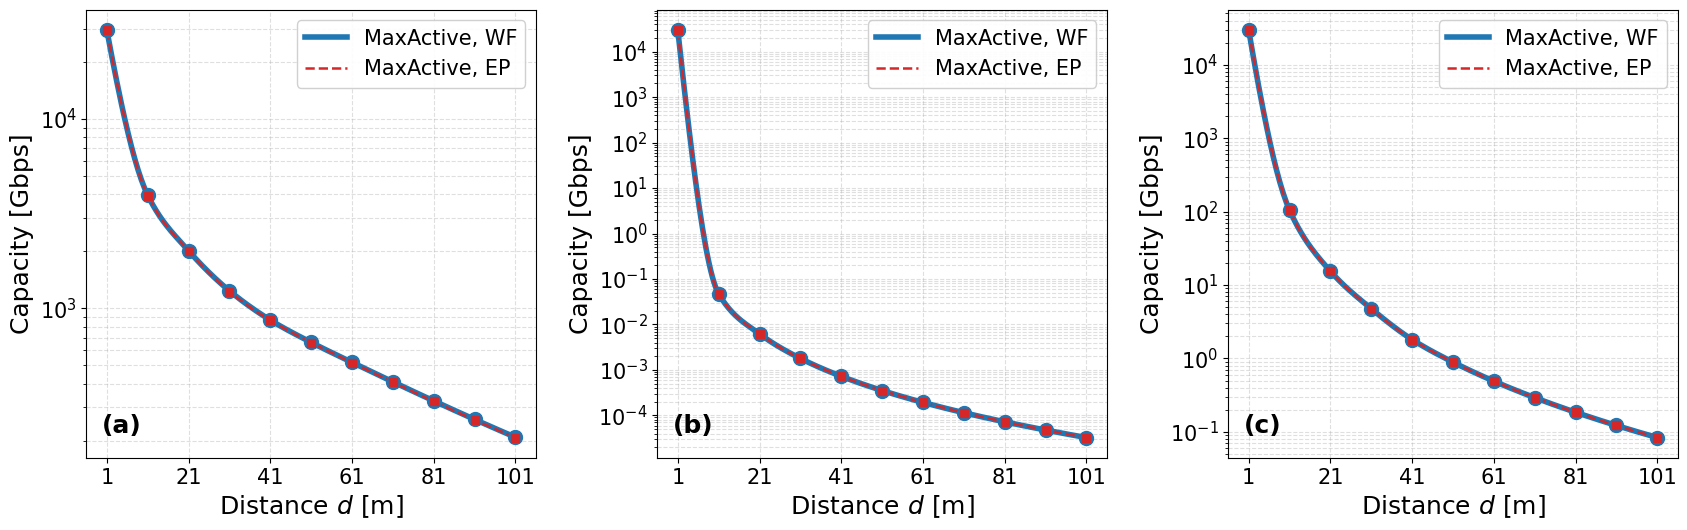

Figure saved: maxactive_capacity_3panel.png  (titles removed, enlarged fonts)


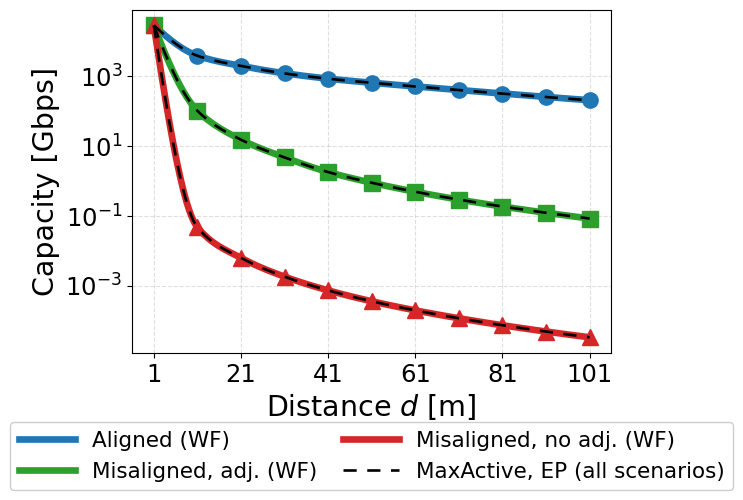

Figure saved: maxactive_reference_single.png  (single-column paper version)


In [19]:
def to_gbps(cap_array):
    return np.maximum(np.array(cap_array) / 1e9, 1e-12)

# -- Presentation: no figure/axes titles (panel tags only), enlarged fonts for print --
FS_LAB, FS_TICK, FS_LEG, FS_TAG = 18, 15, 15, 18

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))

panels = [
    {'ax': axes[0], 'tag': '(a)', 'WF': cap_aligned_WF,    'EP': cap_aligned_EP},
    {'ax': axes[1], 'tag': '(b)', 'WF': cap_diag_noAdj_WF, 'EP': cap_diag_noAdj_EP},
    {'ax': axes[2], 'tag': '(c)', 'WF': cap_diag_Adj_WF,   'EP': cap_diag_Adj_EP},
]

colors = {'WF': '#1f77b4', 'EP': '#d62728'}

for p in panels:
    ax = p['ax']
    # WF and EP nearly coincide (see the Discussion); draw WF thick underneath and EP
    # as a thinner dashed overlay so both remain visible.
    slog(ax, dist_axis, to_gbps(p['WF']), color=colors['WF'], marker='o', ls='-',
         lw=4.0, ms=10, label='MaxActive, WF')
    slog(ax, dist_axis, to_gbps(p['EP']), color=colors['EP'], marker='s', ls='--',
         lw=1.8, ms=6, label='MaxActive, EP')
    ax.set_xlabel('Distance $d$ [m]', fontsize=FS_LAB)
    ax.set_ylabel('Capacity [Gbps]', fontsize=FS_LAB)
    ax.set_xticks(dist_axis[::2])
    ax.tick_params(axis='both', which='major', labelsize=FS_TICK)
    ax.legend(fontsize=FS_LEG, loc='upper right', framealpha=0.92)
    ax.grid(True, which='both', linestyle='--', alpha=0.4)
    ax.text(0.035, 0.045, p['tag'], transform=ax.transAxes, fontsize=FS_TAG,
            fontweight='bold', va='bottom', ha='left')

fig.tight_layout(w_pad=2.2)
fig.savefig('maxactive_capacity_3panel.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure saved: maxactive_capacity_3panel.png  (titles removed, enlarged fonts)')

# -- Compact single-panel version for the paper --------------------------------
# The three scenarios occupy disjoint capacity decades, so all six curves are legible
# on one logarithmic axis; this fits a single journal column and replaces the 3-panel
# figure in the correspondence.
fig2, ax = plt.subplots(figsize=(7.0, 5.2))
series = [
    ('Aligned',             cap_aligned_WF,    cap_aligned_EP,    '#1f77b4', 'o'),
    ('Misaligned, adj.',    cap_diag_Adj_WF,   cap_diag_Adj_EP,   '#2ca02c', 's'),
    ('Misaligned, no adj.', cap_diag_noAdj_WF, cap_diag_noAdj_EP, '#d62728', '^'),
]
# WF: thick coloured line per scenario. EP: thin black dashed overlay -- it lands on the
# WF curve everywhere, which is the point (the WF gain over EP is marginal at THz).
for lab, wf, ep, col, mk in series:
    slog(ax, dist_axis, to_gbps(wf), color=col, marker=mk, ls='-',
         lw=4.8, ms=11, label=f'{lab} (WF)')
for lab, wf, ep, col, mk in series:
    slog(ax, dist_axis, to_gbps(ep), color='k', marker='', ls=(0, (5, 4)),
         lw=1.9, ms=0, zorder=8,
         label='MaxActive, EP (all scenarios)' if lab == 'Aligned' else None)
ax.set_xlabel('Distance $d$ [m]', fontsize=20.5)
ax.set_ylabel('Capacity [Gbps]', fontsize=20.5)
ax.set_xticks(dist_axis[::2])
ax.tick_params(axis='both', which='major', labelsize=17.5)
ax.grid(True, which='both', ls='--', alpha=0.4)
ax.legend(fontsize=15.5, loc='upper center', bbox_to_anchor=(0.5, -0.17),
          ncol=2, framealpha=0.95, columnspacing=1.2, handlelength=2.6)
fig2.tight_layout()
fig2.savefig('maxactive_reference_single.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure saved: maxactive_reference_single.png  (single-column paper version)')

## Section M – Validation and Summary Table

In [20]:
print('=' * 80)
print('VALIDATION')
print('=' * 80)

# 1. X-axis check
assert list(dist_axis) == [1, 11, 21, 31, 41, 51, 61, 71, 81, 91, 101]
print('OK  X-axis: [1, 11, 21, ..., 101] m  (corrected from MATLAB file names)')
print('OK  Y-axis: logarithmic (semilogy used in plot)')

# 2. At d=1m: all scenarios should be equal (same position)
assert abs(cap_aligned_WF[0] - cap_diag_noAdj_WF[0]) < 1.0, 'Step 0 should be equal'
print('OK  d=1m: all scenarios identical (same initial position)')

# 3. Scenario ordering: aligned > diag_adj > diag_noAdj (at d=10m)
k = 1  # step 1 → d≈10m
assert cap_aligned_WF[k] > cap_diag_Adj_WF[k] > cap_diag_noAdj_WF[k], \
    'Expected: aligned > diag_adj > diag_noAdj'
print(f'OK  At step {k} (d~10m):')
print(f'    Aligned WF:       {cap_aligned_WF[k]/1e9:.2f} Gbps')
print(f'    Diag (with adj):  {cap_diag_Adj_WF[k]/1e9:.4f} Gbps')
print(f'    Diag (no adj):    {cap_diag_noAdj_WF[k]/1e9:.6f} Gbps')

# 4. WF > EP for aligned
assert all(cap_aligned_WF >= cap_aligned_EP * 0.99), 'WF should be >= EP'
print('OK  WF >= EP for aligned scenario')

# 5. Capacity span check (log scale)
all_caps = np.concatenate([cap_aligned_WF, cap_diag_noAdj_WF, cap_diag_Adj_WF])
max_gbps = all_caps.max() / 1e9
min_gbps = all_caps[all_caps > 0].min() / 1e9
print(f'OK  Capacity range: {min_gbps:.2e} – {max_gbps:.2e} Gbps (spans {np.log10(max_gbps/min_gbps):.1f} decades)')

print()
print('CAPACITY SUMMARY TABLE (Gbps)')
print('-' * 120)
header = f"{'d(m)':>6} | {'Align WF':>11} | {'Align EP':>11} | {'Adj WF':>11} | {'Adj EP':>11} | {'NoAdj WF':>11} | {'NoAdj EP':>11}"
print(header)
print('-' * len(header))
for k, d in enumerate(dist_axis):
    print(f"{d:>6} | "
          f"{cap_aligned_WF[k]/1e9:>11.4f} | "
          f"{cap_aligned_EP[k]/1e9:>11.4f} | "
          f"{cap_diag_Adj_WF[k]/1e9:>11.6f} | "
          f"{cap_diag_Adj_EP[k]/1e9:>11.6f} | "
          f"{cap_diag_noAdj_WF[k]/1e9:>11.8f} | "
          f"{cap_diag_noAdj_EP[k]/1e9:>11.8f}")
print()
print('VALIDATION COMPLETE')

VALIDATION
OK  X-axis: [1, 11, 21, ..., 101] m  (corrected from MATLAB file names)
OK  Y-axis: logarithmic (semilogy used in plot)
OK  d=1m: all scenarios identical (same initial position)
OK  At step 1 (d~10m):
    Aligned WF:       3954.54 Gbps
    Diag (with adj):  104.1671 Gbps
    Diag (no adj):    0.047124 Gbps
OK  WF >= EP for aligned scenario
OK  Capacity range: 3.26e-05 – 2.94e+04 Gbps (spans 9.0 decades)

CAPACITY SUMMARY TABLE (Gbps)
------------------------------------------------------------------------------------------------------------------------
  d(m) |    Align WF |    Align EP |      Adj WF |      Adj EP |    NoAdj WF |    NoAdj EP
------------------------------------------------------------------------------------------
     1 |  29421.0965 |  29412.2668 | 29421.096538 | 29412.266759 | 29421.09653832 | 29412.26675872
    11 |   3954.5437 |   3936.8428 |  104.167091 |  103.648472 |  0.04712409 |  0.04710929
    21 |   2012.6958 |   2006.1783 |   15.396405 |   15.33

---
## Section M.2 – Additional Mobility Patterns (MaxActive only)

Beyond the aligned/diagonal cases, we reproduce the paper's other two **misaligned**
mobility patterns (**MaxActive only**), each with beamwidth adjustment **OFF** and **ON**:

1. **Misaligned via mobility over elevation** — the Rx moves on a constant-radius
   hemisphere (r = 20 m) around the fixed Tx while the elevation/zenith angle
   phi sweeps 0deg -> 180deg. The distance stays constant, so capacity falls purely
   from beam misalignment (paper Fig. 11 style).
2. **Misaligned via real mobility traces** — Tx and Rx positions are integrated from
   the real windy-hover acceleration traces in `data_small_windy_average.mat` over
   0-5 s, with a diagonal drift so the beams misalign (paper Fig. 14 style).

Trajectory generation ports the MATLAB `Main_Code.m` (`GenHemSphCoord`, `a2vd`), and
capacity uses the same `distance_to_cap_opt` (MaxActive) as the main scenarios. These
cells only ADD new variables/figures; the ML/D3QN pipeline below is unaffected.


In [21]:
# -- Trajectory generators (ports of MATLAB GenHemSphCoord + a2vd) --
import scipy.io as sio

def a2vd(a, t, v0, d0):
    """Acceleration -> velocity/position integration (MATLAB a2vd)."""
    a = np.asarray(a, float); t = np.asarray(t, float)
    N = len(a); v = np.zeros(N); d = np.zeros(N); v[0] = v0; d[0] = d0
    for k in range(1, N):
        a_kk = (a[1:k+1] + a[0:k]) / 2.0
        dt   = (t[1:k+1] - t[0:k])
        v[k] = np.sum(a_kk * dt) + v0
        d[k] = d[k-1] + v[k-1]*dt[-1] + 0.5*a_kk[-1]*dt[-1]**2
    return v, d

_cosd = lambda x: np.cos(np.radians(x))
_sind = lambda x: np.sin(np.radians(x))

def make_elevation_traj(r=20.0, Tx=(0.0, 10.0, 100.0), theta_deg=180.0, phi_deg=None):
    """Rx on a constant-radius hemisphere; elevation angle phi sweeps 0..180 deg
    (MATLAB GenHemSphCoord with ThetaPhiFlag=1). Tx is fixed."""
    if phi_deg is None:
        phi_deg = np.arange(0, 181, 10.0)
    Tx = np.array(Tx, float)
    xr = r*_cosd(theta_deg)*_sind(phi_deg) + Tx[0]
    yr = r*_sind(theta_deg)*_sind(phi_deg) + Tx[1]
    zr = r*_cosd(phi_deg)                  + Tx[2]
    n  = len(phi_deg)
    return dict(xt=np.full(n, Tx[0]), yt=np.full(n, Tx[1]), zt=np.full(n, Tx[2]),
                xr=xr, yr=yr, zr=zr, axis=phi_deg,
                axis_label='Elevation/Zenith Angle (phi) [degrees]')

def make_real_traj(straight_diagonal=1, timeFinal=5.5,
                   Tx0=(0.0, 10.0, 100.0), Rx0=(0.0, 11.0, 100.0)):
    """Integrate real windy-hover acceleration traces (MATLAB real-mobility branch).
    straight_diagonal: 0 = straight drift (0,10), 1 = diagonal drift (5*sqrt2, 5*sqrt2)."""
    M = sio.loadmat(os.path.join(MAT_DIR, 'data_small_windy_average.mat'))['DataNewAv']
    dt = float(np.mean(np.diff(M[:, 0])))
    FinalIdx = int(round(timeFinal / dt))
    LastIdx  = (M.shape[0] // FinalIdx) * FinalIdx
    DataR = M[:LastIdx, :].reshape(FinalIdx, LastIdx // FinalIdx, 4, order='F')
    DataTx = DataR[:, 1, :]      # Trace1Number = 2 -> Tx
    DataRx = DataR[:, 0, :]      # Trace2Number = 1 -> Rx
    if straight_diagonal == 0:
        vi_x_r, vi_y_r = 0.0, 10.0
    else:
        vi_x_r, vi_y_r = np.sqrt(2)*5.0, np.sqrt(2)*5.0
    Tx0 = np.array(Tx0, float); Rx0 = np.array(Rx0, float)
    _, xt = a2vd(DataTx[:, 1], DataTx[:, 0], 0.0, Tx0[0])
    _, yt = a2vd(DataTx[:, 2], DataTx[:, 0], 0.0, Tx0[1])
    _, zt = a2vd(DataTx[:, 3], DataTx[:, 0], 0.0, Tx0[2])
    _, xr = a2vd(DataRx[:, 1], DataRx[:, 0], vi_x_r, Rx0[0])
    _, yr = a2vd(DataRx[:, 2], DataRx[:, 0], vi_y_r, Rx0[1])
    _, zr = a2vd(DataRx[:, 3], DataRx[:, 0], 0.0,    Rx0[2])
    t_axis = DataTx[:, 0] - DataTx[0, 0]
    return dict(xt=xt, yt=yt, zt=zt, xr=xr, yr=yr, zr=zr, axis=t_axis,
                axis_label='Time (t) [sec]')

def run_traj_maxactive(traj, BeamWidthOptFlag, PowerAllocFlag):
    """MaxActive capacity along a (possibly moving-Tx) trajectory. Boresight is fixed
    from the FIRST position of THIS trajectory (MATLAB BorsightCalc)."""
    xt, yt, zt = traj['xt'], traj['yt'], traj['zt']
    xr, yr, zr = traj['xr'], traj['yr'], traj['zr']
    tTxBS, pTxBS, tRxBS, pRxBS = boresight_calc(
        np.array([xt[0], yt[0], zt[0]]), np.array([xr[0], yr[0], zr[0]]))
    caps = []
    for k in range(len(xr)):
        cap, _, _ = distance_to_cap_opt(
            PowerAllocFlag, 1, BeamWidthOptFlag, TxPower_dBmW,
            np.array([xr[k], yr[k], zr[k]]), np.array([xt[k], yt[k], zt[k]]),
            tTxBS, pTxBS, tRxBS, pRxBS)
        caps.append(cap)
    return np.array(caps)

print('Additional-mobility trajectory generators + MaxActive runner defined.')


Additional-mobility trajectory generators + MaxActive runner defined.

Elevation: 19 steps, constant distance 20.0 m, phi 0..180 deg


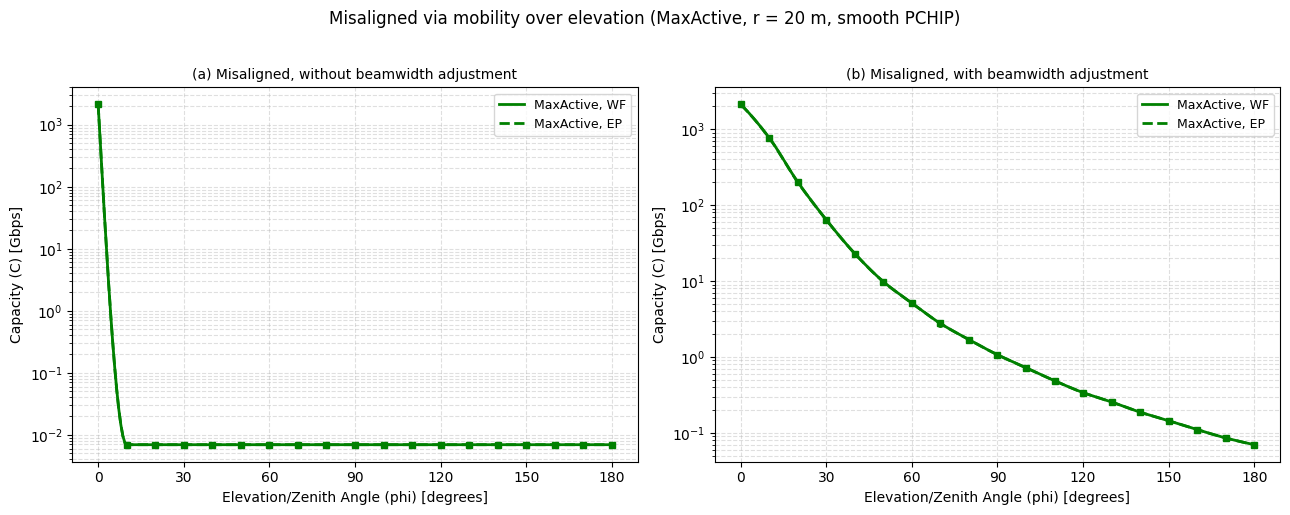

Saved: maxactive_elevation.png


In [22]:
# -- (1) Misaligned via mobility over elevation -- MaxActive, Fig. 11 style --
elev = make_elevation_traj(r=20.0)
d_el = np.sqrt((elev['xr']-elev['xt'])**2 + (elev['yr']-elev['yt'])**2 + (elev['zr']-elev['zt'])**2)
print('Elevation: %d steps, constant distance %.1f m, phi 0..180 deg'
      % (len(elev['axis']), d_el.mean()))

elev_caps = {}
for adj in (0, 1):
    for pa, name in ((1, 'WF'), (0, 'EP')):
        elev_caps[(adj, name)] = run_traj_maxactive(elev, adj, pa)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (adj, ttl) in zip(axes, [(0, '(a) Misaligned, without beamwidth adjustment'),
                                  (1, '(b) Misaligned, with beamwidth adjustment')]):
    slog(ax, elev['axis'], elev_caps[(adj, 'WF')]/1e9, color='g', marker='s', ls='-',
         lw=2, ms=5, label='MaxActive, WF')
    slog(ax, elev['axis'], elev_caps[(adj, 'EP')]/1e9, color='g', marker='o', ls='--',
         lw=2, ms=4, label='MaxActive, EP')
    ax.set_xlabel(elev['axis_label']); ax.set_ylabel('Capacity (C) [Gbps]')
    ax.set_title(ttl, fontsize=10); ax.set_xticks(np.arange(0, 181, 30))
    ax.grid(True, which='both', ls='--', alpha=0.4); ax.legend(fontsize=9)
fig.suptitle('Misaligned via mobility over elevation (MaxActive, r = 20 m, smooth PCHIP)', y=1.02)
plt.tight_layout(); plt.savefig('maxactive_elevation.png', dpi=150, bbox_inches='tight'); plt.show()
print('Saved: maxactive_elevation.png')


Real traces: 11 steps, t=0.0..5.0 s, distance 1.0..52.9 m


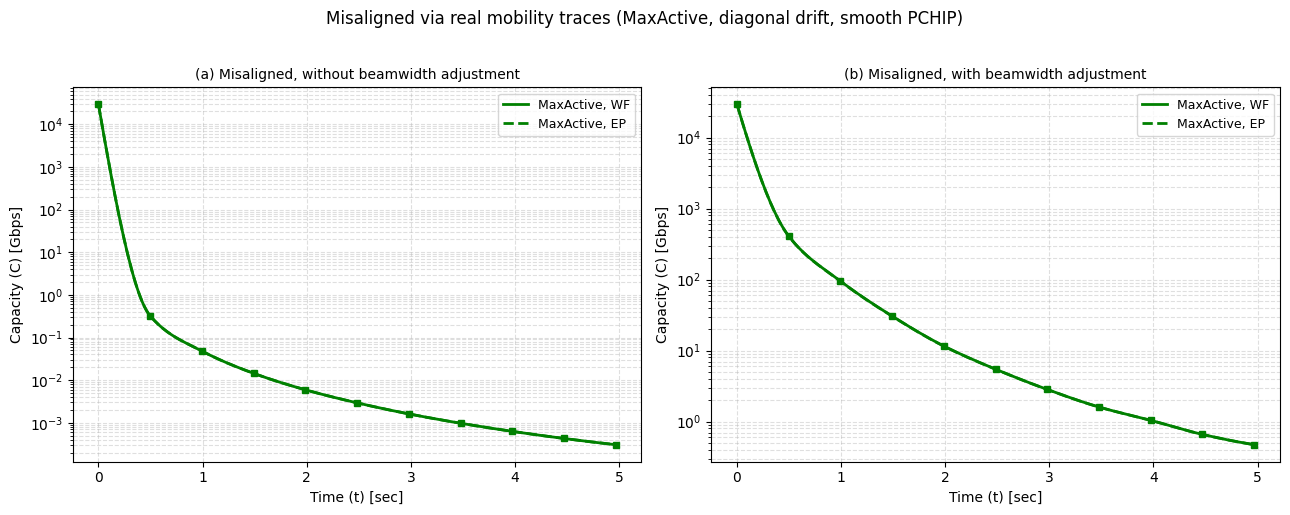

Saved: maxactive_real_traces.png


In [23]:
# -- (2) Misaligned via real mobility traces -- MaxActive, Fig. 14 style --
real = make_real_traj(straight_diagonal=1)   # diagonal drift -> misalignment
d_re = np.sqrt((real['xr']-real['xt'])**2 + (real['yr']-real['yt'])**2 + (real['zr']-real['zt'])**2)
print('Real traces: %d steps, t=%.1f..%.1f s, distance %.1f..%.1f m'
      % (len(real['axis']), real['axis'][0], real['axis'][-1], d_re.min(), d_re.max()))

real_caps = {}
for adj in (0, 1):
    for pa, name in ((1, 'WF'), (0, 'EP')):
        real_caps[(adj, name)] = run_traj_maxactive(real, adj, pa)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (adj, ttl) in zip(axes, [(0, '(a) Misaligned, without beamwidth adjustment'),
                                  (1, '(b) Misaligned, with beamwidth adjustment')]):
    slog(ax, real['axis'], real_caps[(adj, 'WF')]/1e9, color='g', marker='s', ls='-',
         lw=2, ms=5, label='MaxActive, WF')
    slog(ax, real['axis'], real_caps[(adj, 'EP')]/1e9, color='g', marker='o', ls='--',
         lw=2, ms=4, label='MaxActive, EP')
    ax.set_xlabel(real['axis_label']); ax.set_ylabel('Capacity (C) [Gbps]')
    ax.set_title(ttl, fontsize=10)
    ax.grid(True, which='both', ls='--', alpha=0.4); ax.legend(fontsize=9)
fig.suptitle('Misaligned via real mobility traces (MaxActive, diagonal drift, smooth PCHIP)', y=1.02)
plt.tight_layout(); plt.savefig('maxactive_real_traces.png', dpi=150, bbox_inches='tight'); plt.show()
print('Saved: maxactive_real_traces.png')


---
## Section N – Data Preparation for ML / D3QN

Build a dataset of **(state, MaxActive-WF, MaxActive-EP)** tuples for every scenario × distance step.

### Distance Correction
MATLAB files are at distances **[1, 11, 21, ..., 101] m** (confirmed from filenames).
 maps each trajectory step to the nearest LBLRTM file, which now correctly
aligns with these distances.

### Improved State Representation (v2)
Old state: raw  per subband — scale differences hurt D3QN.

New state **(42 dims)**:
- **Dims 0–19**: log10-SNR estimate per subband (accounts for TX power + Gain + PL + noise together)
- **Dims 20–39**: log10(noise power) per subband (raw absorption-driven noise)
- **Dim 40**: log10(3D distance in metres) — critical distance cue for D3QN
- **Dim 41**: total antenna gain [dB] normalised to [0,1]

This richer state helps D3QN understand both the channel quality *and* the current range/alignment.

In [24]:
import numpy as np
import warnings, time
warnings.filterwarnings("ignore")

# Sub-band parameters
Nmax      = 20          # frequency sub-bands
amax      = 20          # D3QN discrete actions (= Nmax so action a -> N_sel = a+1)
FREQ_LOW  = StartFreqTHz
FREQ_HIGH = StopFreqTHz

# State dimension: 2*Nmax + 2 (log_dist + gain_norm)
STATE_DIM = 2 * Nmax + 2   # = 42


def build_subband_state_v2(Freq_THz, PLtotal_dB, AbsLoss_dB,
                            dist_m, Gain_dB_total):
    """Improved state: [log10_SNR(20), log10_noise(20), log10_dist, gain_norm].
    
    log10_SNR_k = (TxPower_dBW + Gain_dB - PLtotal_mean_k) / 10  [log scale proxy]
    This represents channel quality accounting for both path loss and TX conditions.
    """
    idx  = np.where((Freq_THz >= FREQ_LOW) & (Freq_THz <= FREQ_HIGH))[0]
    F    = Freq_THz[idx]
    PL   = PLtotal_dB[idx]
    Ab   = AbsLoss_dB[idx]
    dF   = delta_freq_hz(Freq_THz)[idx]

    edges         = np.linspace(FREQ_LOW, FREQ_HIGH, Nmax + 1)
    sb_mean_PL    = np.zeros(Nmax)
    sb_log_noise  = np.zeros(Nmax)
    sb_log_snr    = np.zeros(Nmax)
    sb_bandwidths = np.zeros(Nmax)
    sb_valid      = np.zeros(Nmax, dtype=bool)

    for k in range(Nmax):
        m = (F >= edges[k]) & (F < edges[k+1])
        if m.sum() == 0:
            continue
        sb_mean_PL[k]   = PL[m].mean()
        Pn_k             = noise_power(Ab[m], dF[m])
        Pn_mean          = Pn_k.mean()
        sb_log_noise[k]  = np.log10(np.maximum(Pn_mean, 1e-40))
        sb_bandwidths[k] = dF[m].sum()
        sb_valid[k]      = True

        # SNR estimate: received power / noise
        # P_rx = P_tx * G / PathLoss  => P_rx_dBW = TxPower_dBW + Gain_dB - PLtotal_mean_k
        # SNR_dB = P_rx_dBW - 10*log10(Pn_mean)
        P_rx_dBW        = TxPower_dBW + Gain_dB_total - sb_mean_PL[k]
        SNR_dB_k        = P_rx_dBW - 10.0 * sb_log_noise[k]
        # Store log10 of linear SNR (SNR_dB / 10)
        sb_log_snr[k]   = SNR_dB_k / 10.0  # already log10 scale

    # Global features
    log_dist  = np.log10(np.maximum(dist_m, 0.1))          # log10 metres
    gain_norm = Gain_dB_total / 60.0                         # normalise: main-beam ~52 dB => /60

    state = np.concatenate([
        sb_log_snr,
        sb_log_noise,
        [log_dist, gain_norm]
    ]).astype(np.float32)

    return state, edges, sb_mean_PL, sb_log_noise, sb_bandwidths, sb_valid


def eval_subband_selection(selected_sb_mask, Freq_THz, PLtotal_dB,
                            AbsLoss_dB, Gain_dB, power_alloc="EP"):
    edges   = np.linspace(FREQ_LOW, FREQ_HIGH, Nmax + 1)
    idx_all = np.where((Freq_THz >= FREQ_LOW) & (Freq_THz <= FREQ_HIGH))[0]
    F       = Freq_THz[idx_all]

    ch_mask = np.zeros(len(Freq_THz), dtype=int)
    for k in np.where(selected_sb_mask)[0]:
        in_sb = (F >= edges[k]) & (F < edges[k+1])
        ch_mask[idx_all[in_sb]] = 1

    if ch_mask.sum() == 0:
        return 0.0

    PT  = db2pow(TxPower_dBW + Gain_dB)
    PNB = np.where(ch_mask == 1, pow2db(PT), -np.inf)
    cap, _, _ = mask_cap(ch_mask, Freq_THz, PLtotal_dB, AbsLoss_dB, 0.0, PNB)
    return cap


print(f"Sub-band setup: Nmax={Nmax}, amax={amax} (action a -> N_sel=a+1), freq {FREQ_LOW}-{FREQ_HIGH} THz")
print(f"State dimension: {STATE_DIM}  (SNR x{Nmax} + noise x{Nmax} + log_dist + gain_norm)")
Ft, Ab, PL = load_lblrtm(0.001)
s, edges, sb_PL, sb_noise, sb_bw, sb_v = build_subband_state_v2(
    Ft, PL, Ab, dist_m=1.0, Gain_dB_total=52.3)
print(f"State[0:5] log_SNR: {s[:5]}")
print(f"State[20:25] log_noise: {s[20:25]}")
print(f"State[-2:] [log_dist, gain_norm]: {s[-2:]}")
print(f"Valid sub-bands: {sb_v.sum()}/{Nmax}")

Sub-band setup: Nmax=20, amax=20 (action a -> N_sel=a+1), freq 0.75-4.4 THz
State dimension: 42  (SNR x20 + noise x20 + log_dist + gain_norm)
State[0:5] log_SNR: [8.586072  7.5628185 7.0066094 7.481312  7.135463 ]
State[20:25] log_noise: [-13.09118  -12.4969   -12.260078 -12.590271 -12.453846]
State[-2:] [log_dist, gain_norm]: [0.         0.87166667]
Valid sub-bands: 20/20


In [25]:
# Generate reference dataset with improved v2 state
print("Generating MaxActive reference dataset (v2 state: SNR + noise + dist + gain)...")

dataset = []

scenarios = [
    ("aligned",    x_r_aligned, y_r_aligned, z_r_aligned, 0, 0),
    ("diag_noAdj", x_r_diag,    y_r_diag,    z_r_diag,    0, 1),
    ("diag_Adj",   x_r_diag,    y_r_diag,    z_r_diag,    1, 2),
]

ref_caps = {
    ("aligned",    "WF"): cap_aligned_WF,
    ("aligned",    "EP"): cap_aligned_EP,
    ("diag_noAdj", "WF"): cap_diag_noAdj_WF,
    ("diag_noAdj", "EP"): cap_diag_noAdj_EP,
    ("diag_Adj",   "WF"): cap_diag_Adj_WF,
    ("diag_Adj",   "EP"): cap_diag_Adj_EP,
}

for (sc_name, xr, yr, zr, bwo, sc_id) in scenarios:
    for k in range(N_STEPS):
        CoordRx_k = np.array([xr[k], yr[k], zr[k]])
        d3        = float(np.sqrt(np.sum((CoordRx_k - CoordTx_init)**2)))
        range_km  = d3 / 1000.0

        Freq_THz, AbsLoss_dB, PLtotal_dB = load_lblrtm(range_km)

        if bwo == 0:
            bw_u = BeamWidth_deg
        else:
            bw_u, _ = antenna_gain_optim(
                BeamWidth_deg, SideLobeStrength, TxPower_dBmW,
                CoordRx_k, CoordTx_init,
                tTxBS, pTxBS, tRxBS, pRxBS,
                ((Freq_THz >= StartFreqTHz) & (Freq_THz <= StopFreqTHz)).astype(int),
                PLtotal_dB, AbsLoss_dB, Freq_THz
            )
        Gain_dB = total_antenna_gain_dB(
            CoordTx_init, CoordRx_k,
            tTxBS, pTxBS, tRxBS, pRxBS,
            bw_u, bw_u, SideLobeStrength, SideLobeStrength
        )

        # v2 state: includes SNR estimate, log_dist, gain_norm
        state, edges, sb_PL, sb_noise, sb_bw, sb_valid = build_subband_state_v2(
            Freq_THz, PLtotal_dB, AbsLoss_dB,
            dist_m=d3, Gain_dB_total=Gain_dB
        )

        dataset.append({
            "scenario":    sc_name,
            "scenario_id": sc_id,
            "step":        k,
            "dist_nom":    dist_axis[k],
            "dist_3d":     d3,
            "Gain_dB":     Gain_dB,
            "bw_used":     bw_u,
            "state":       state,
            "sb_PL":       sb_PL,
            "sb_noise":    sb_noise,
            "sb_bw":       sb_bw,
            "sb_valid":    sb_valid,
            "Freq_THz":    Freq_THz,
            "PLtotal_dB":  PLtotal_dB,
            "AbsLoss_dB":  AbsLoss_dB,
            "cap_MA_WF":   ref_caps[(sc_name, "WF")][k],
            "cap_MA_EP":   ref_caps[(sc_name, "EP")][k],
        })

print(f"Dataset: {len(dataset)} samples  "
      f"({len(dataset)//N_STEPS} scenarios x {N_STEPS} steps)")
print(f"State dimension: {dataset[0]["state"].shape[0]}  "
      f"(log_SNR x{Nmax} + log_noise x{Nmax} + log_dist + gain_norm)")

# Show distance correction impact
print()
print("Distance check (step -> actual 3D distance):")
aligned_samps = sorted([x for x in dataset if x["scenario"]=="aligned"], key=lambda x: x["step"])
for x in aligned_samps:
    print(f"  step {x['step']:2d}: dist_nom={x['dist_nom']:3d}m  dist_3d={x['dist_3d']:.2f}m")

Generating MaxActive reference dataset (v2 state: SNR + noise + dist + gain)...


Dataset: 33 samples  (3 scenarios x 11 steps)
State dimension: 42  (log_SNR x20 + log_noise x20 + log_dist + gain_norm)

Distance check (step -> actual 3D distance):
  step  0: dist_nom=  1m  dist_3d=1.00m
  step  1: dist_nom= 11m  dist_3d=11.00m
  step  2: dist_nom= 21m  dist_3d=21.00m
  step  3: dist_nom= 31m  dist_3d=31.00m
  step  4: dist_nom= 41m  dist_3d=41.00m
  step  5: dist_nom= 51m  dist_3d=51.00m
  step  6: dist_nom= 61m  dist_3d=61.00m
  step  7: dist_nom= 71m  dist_3d=71.00m
  step  8: dist_nom= 81m  dist_3d=81.00m
  step  9: dist_nom= 91m  dist_3d=91.00m
  step 10: dist_nom=101m  dist_3d=101.00m


## Section O - D3QN v4: Paper-Faithful Implementation

**Key changes from v3:**
- **Individual channels** (not subbands!) - same channel resolution as MaxActive EP
- **Per-(d, GT) contextual bandit** - one model per distance step (exactly as in the paper)
- **Paper network** - `state_dim -> 16 -> 8 -> dueling [V(1), A(amax)]`
- **Paper reward** - `r = ln((Cmax-Cmin)+1) - ln((Cmax-C)+1)`
- **EP only** - same as paper for simplicity and fair comparison

**Why this fixes the gap:**  
v3 used 20 subbands (~585 channels each): D3QN selecting 1 subband = EP over 585 channels with diluted power.  
MaxActive EP selects individual best channels and concentrates power.  
Now both operate on the same sorted individual channels -> D3QN can exactly match MaxActive EP.

In [26]:
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import random, time

device = torch.device('cpu')
torch.manual_seed(42); np.random.seed(42); random.seed(42)

# D3QN v4 parameters
N_STATE      = 500          # top-N channels used in STATE (compressed)
AMAX         = 600          # number of discrete actions
STATE_DIM_V4 = 2 * N_STATE  # 1000

# Action mapping: covers FULL channel range (1 to N_total)
# Actions 0..49   -> N_sel = 1..50   (fine for small selections)
# Actions 50..599 -> N_sel = 51..N_total (coarser for large selections)
def make_action_map(N_total):
    amap = []
    fine = min(50, N_total)
    for a in range(fine):
        amap.append(a + 1)
    for a in range(fine, AMAX):
        frac = (a - fine) / max(AMAX - fine - 1, 1)
        n = int(round(fine + frac * (N_total - fine)))
        amap.append(max(fine + 1, min(n + 1, N_total)))
    return amap

print(f'D3QN v4: N_STATE={N_STATE}, AMAX={AMAX}, state_dim={STATE_DIM_V4}')
print(f'Network: {STATE_DIM_V4} -> 16 -> 8 -> dueling [V(1), A({AMAX})]')


def get_sorted_channels_v4(Freq_THz, PLtotal_dB, AbsLoss_dB, Gain_dB_total):
    mask    = (Freq_THz >= StartFreqTHz) & (Freq_THz <= StopFreqTHz)
    idx     = np.where(mask)[0]
    dF_all  = delta_freq_hz(Freq_THz)
    APL_lin = db2pow(PLtotal_dB[idx])
    Pn_ch   = noise_power(AbsLoss_dB[idx], dF_all[idx])
    dF_ch   = dF_all[idx]
    q       = 1.0 / (APL_lin * np.maximum(Pn_ch, 1e-300))
    order   = np.argsort(q)[::-1]
    return APL_lin[order], Pn_ch[order], dF_ch[order]


def build_state_v4(APL_s, Pn_s):
    K   = min(N_STATE, len(APL_s))
    apl = np.log10(np.maximum(APL_s[:K], 1e-300))
    pn  = np.log10(np.maximum(Pn_s[:K],  1e-300))
    if K < N_STATE:
        apl = np.pad(apl, (0, N_STATE - K), constant_values=apl[-1] if K > 0 else 0.0)
        pn  = np.pad(pn,  (0, N_STATE - K), constant_values=pn[-1]  if K > 0 else 0.0)
    return np.concatenate([apl, pn]).astype(np.float32)


def eval_ep_cap_v4(n_sel, APL_s, Pn_s, dF_s, Gain_dB_total):
    n = min(int(n_sel), len(APL_s))
    if n <= 0:
        return 0.0
    PT_G = db2pow(TxPower_dBW + Gain_dB_total)
    SNR  = (PT_G / n) / (APL_s[:n] * np.maximum(Pn_s[:n], 1e-300))
    return float(np.sum(dF_s[:n] * np.log2(1.0 + SNR)))


def maxactive_ep_v4(APL_s, Pn_s, dF_s, Gain_dB_total):
    N = len(APL_s)
    best_C, best_n = 0.0, 1
    step = max(1, N // 300)
    for n in list(range(1, N + 1, step)) + [N]:
        C = eval_ep_cap_v4(n, APL_s, Pn_s, dF_s, Gain_dB_total)
        if C > best_C:
            best_C, best_n = C, n
    lo, hi = max(1, best_n - step * 2), min(N, best_n + step * 2)
    for n in range(lo, hi + 1):
        C = eval_ep_cap_v4(n, APL_s, Pn_s, dF_s, Gain_dB_total)
        if C > best_C:
            best_C, best_n = C, n
    return best_C, best_n


class DuelingDQN_v4(nn.Module):
    def __init__(self, state_dim=None, n_actions=None):
        super().__init__()
        sd = state_dim if state_dim is not None else STATE_DIM_V4
        na = n_actions if n_actions is not None else AMAX
        self.fc = nn.Sequential(
            nn.Linear(sd, 16), nn.ReLU(),
            nn.Linear(16, 8),  nn.ReLU())
        self.V = nn.Linear(8, 1)
        self.A = nn.Linear(8, na)
    def forward(self, x):
        h = self.fc(x)
        V = self.V(h); A = self.A(h)
        return V + (A - A.mean(dim=-1, keepdim=True))


class RBuf_v4:
    def __init__(self, cap=5000):
        self.buf = deque(maxlen=cap)
    def push(self, s, a, r, s2, d):
        self.buf.append((s, a, r, s2, d))
    def sample(self, n):
        b = random.sample(self.buf, min(n, len(self.buf)))
        s, a, r, s2, d = zip(*b)
        return (torch.FloatTensor(np.array(s)),
                torch.LongTensor(a), torch.FloatTensor(r),
                torch.FloatTensor(np.array(s2)), torch.FloatTensor(d))
    def __len__(self):
        return len(self.buf)

print('D3QN v4 helpers defined.')


D3QN v4: N_STATE=500, AMAX=600, state_dim=1000
Network: 1000 -> 16 -> 8 -> dueling [V(1), A(600)]
D3QN v4 helpers defined.


In [27]:
def train_bandit_v4(state, APL_s, Pn_s, dF_s, Gain_dB,
                    action_map, Cmax, Cmin=0.0,
                    n_epochs=20, n_act_per_ep=80,
                    lr=0.001, eps_start=1.0, eps_end=0.02):
    net = DuelingDQN_v4().to(device)
    opt = optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    buf = RBuf_v4(cap=n_epochs * n_act_per_ep + 100)
    s_t      = torch.FloatTensor(state).unsqueeze(0).to(device)
    eps      = eps_start
    eps_step = (eps_start - eps_end) / max(n_epochs - 1, 1)
    log_norm = float(np.log((Cmax - Cmin) + 1.0 + 1e-20))
    best_C, best_a = -1.0, 0

    for ep in range(n_epochs):
        for _ in range(n_act_per_ep):
            if random.random() < eps:
                a = random.randint(0, AMAX - 1)
            else:
                with torch.no_grad():
                    a = int(net(s_t).argmax().item())
            n_sel = action_map[a]
            C     = eval_ep_cap_v4(n_sel, APL_s, Pn_s, dF_s, Gain_dB)
            r     = float(log_norm - np.log((Cmax - C) + 1.0 + 1e-20))
            if C > best_C:
                best_C, best_a = C, a
            buf.push(state, a, r, state, 1.0)

        if len(buf) >= 32:
            sb, ab, rb, _, _ = buf.sample(64)
            Q_sel = net(sb).gather(1, ab.unsqueeze(1)).squeeze(1)
            loss  = nn.SmoothL1Loss()(Q_sel, rb.detach())
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        eps = max(eps_end, eps - eps_step)

    net.eval()
    with torch.no_grad():
        a_g = int(net(s_t).argmax().item())
    C_g = eval_ep_cap_v4(action_map[a_g], APL_s, Pn_s, dF_s, Gain_dB)
    if C_g >= best_C:
        return C_g, action_map[a_g]
    return best_C, action_map[best_a]


print('=' * 72)
print('D3QN v4 - per-distance contextual bandit (FULL channel range)')
print(f'  N_STATE={N_STATE} AMAX={AMAX} epochs=20 actions/ep=80')
print('=' * 72)

scenarios_v4 = [
    ('aligned',    x_r_aligned, y_r_aligned, z_r_aligned, 0),
    ('diag_noAdj', x_r_diag,    y_r_diag,    z_r_diag,    0),
    ('diag_Adj',   x_r_diag,    y_r_diag,    z_r_diag,    1),
]

d3qn_v4_caps  = {}
ma_ep_v4_caps = {}
d3qn_v4_n_sel = {}

t0 = time.time()

for sc_name, xr, yr, zr, BeamWidthOptFlag in scenarios_v4:
    print(f'\n--- {sc_name} ---')
    caps_d3 = []; caps_ma = []; n_sels = []

    for k in range(N_STEPS):
        CoordRx_k = np.array([xr[k], yr[k], zr[k]])
        d3        = float(np.sqrt(np.sum((CoordRx_k - CoordTx_init)**2)))
        Ft, Ab, PL = load_lblrtm(d3 / 1000.0)

        if BeamWidthOptFlag == 0:
            bw_u = BeamWidth_deg
        else:
            bw_u, _ = antenna_gain_optim(
                BeamWidth_deg, SideLobeStrength, TxPower_dBmW,
                CoordRx_k, CoordTx_init, tTxBS, pTxBS, tRxBS, pRxBS,
                ((Ft >= StartFreqTHz) & (Ft <= StopFreqTHz)).astype(int), PL, Ab, Ft)

        Gain_dB = total_antenna_gain_dB(
            CoordTx_init, CoordRx_k, tTxBS, pTxBS, tRxBS, pRxBS,
            bw_u, bw_u, SideLobeStrength, SideLobeStrength)

        APL_s, Pn_s, dF_s = get_sorted_channels_v4(Ft, PL, Ab, Gain_dB)
        N_total = len(APL_s)
        Cmax, n_opt = maxactive_ep_v4(APL_s, Pn_s, dF_s, Gain_dB)
        action_map  = make_action_map(N_total)
        state       = build_state_v4(APL_s, Pn_s)

        C_d3, n_d3 = train_bandit_v4(state, APL_s, Pn_s, dF_s, Gain_dB,
                                      action_map=action_map,
                                      Cmax=Cmax, Cmin=0.0,
                                      n_epochs=20, n_act_per_ep=80)
        ratio = C_d3 / (Cmax + 1e-12) * 100
        print(f'  k={k:2d} d={d3:6.1f}m G={Gain_dB:5.1f}dB | '
              f'n_opt={n_opt:5d} n_D3QN={n_d3:5d} | '
              f'MA_EP={Cmax/1e9:.4f} D3QN={C_d3/1e9:.4f} Gbps ratio={ratio:.1f}%')
        caps_d3.append(C_d3); caps_ma.append(Cmax); n_sels.append(n_d3)

    d3qn_v4_caps[sc_name]  = np.array(caps_d3)
    ma_ep_v4_caps[sc_name] = np.array(caps_ma)
    d3qn_v4_n_sel[sc_name] = np.array(n_sels)
    ratios = d3qn_v4_caps[sc_name] / (ma_ep_v4_caps[sc_name] + 1e-12) * 100
    print(f'  --> Mean ratio: {ratios.mean():.1f}% (min {ratios.min():.1f}% max {ratios.max():.1f}%)')

print(f'\nTotal training time: {time.time()-t0:.1f}s')

import gc; gc.collect()


D3QN v4 - per-distance contextual bandit (FULL channel range)
  N_STATE=500 AMAX=600 epochs=20 actions/ep=80

--- aligned ---


  k= 0 d=   1.0m G= 52.3dB | n_opt=10296 n_D3QN=10300 | MA_EP=29412.2668 D3QN=29412.2596 Gbps ratio=100.0%
  k= 1 d=  11.0m G= 52.3dB | n_opt= 2703 n_D3QN= 2682 | MA_EP=3936.8428 D3QN=3936.7894 Gbps ratio=100.0%


  k= 2 d=  21.0m G= 52.3dB | n_opt= 1646 n_D3QN= 1642 | MA_EP=2006.1783 D3QN=2006.1673 Gbps ratio=100.0%
  k= 3 d=  31.0m G= 52.3dB | n_opt= 1224 n_D3QN= 1218 | MA_EP=1225.1826 D3QN=1225.1749 Gbps ratio=100.0%


  k= 4 d=  41.0m G= 52.3dB | n_opt=  716 n_D3QN=  709 | MA_EP=863.4102 D3QN=863.3482 Gbps ratio=100.0%
  k= 5 d=  51.0m G= 52.3dB | n_opt=  577 n_D3QN=  581 | MA_EP=659.3729 D3QN=659.3301 Gbps ratio=100.0%


  k= 6 d=  61.0m G= 52.3dB | n_opt=  545 n_D3QN=  539 | MA_EP=516.5454 D3QN=516.4535 Gbps ratio=100.0%
  k= 7 d=  71.0m G= 52.3dB | n_opt=  508 n_D3QN=  497 | MA_EP=406.8643 D3QN=406.6611 Gbps ratio=100.0%


  k= 8 d=  81.0m G= 52.3dB | n_opt=  467 n_D3QN=  497 | MA_EP=322.2378 D3QN=321.2539 Gbps ratio=99.7%
  k= 9 d=  91.0m G= 52.3dB | n_opt=  414 n_D3QN=  390 | MA_EP=257.0575 D3QN=256.7440 Gbps ratio=99.9%


... (9 outputs left out)

  k= 6 d=  60.7m G= 14.1dB | n_opt=   51 n_D3QN=   51 | MA_EP=0.4908 D3QN=0.4908 Gbps ratio=100.0%
  k= 7 d=  70.7m G= 14.1dB | n_opt=   44 n_D3QN=   44 | MA_EP=0.2926 D3QN=0.2926 Gbps ratio=100.0%


  k= 8 d=  80.7m G= 14.1dB | n_opt=   32 n_D3QN=   32 | MA_EP=0.1849 D3QN=0.1849 Gbps ratio=100.0%
  k= 9 d=  90.7m G= 14.1dB | n_opt=   19 n_D3QN=   19 | MA_EP=0.1223 D3QN=0.1223 Gbps ratio=100.0%


  k=10 d= 100.7m G= 14.1dB | n_opt=   16 n_D3QN=   16 | MA_EP=0.0838 D3QN=0.0838 Gbps ratio=100.0%
  --> Mean ratio: 100.0% (min 99.7% max 100.0%)

Total training time: 6.2s


0

In [28]:
print('=' * 88)
print(f'D3QN v4 Results  |  individual channels sorted by SNR  |  top-{N_STATE} channels')
print('=' * 88)

for sc_name, xr, yr, zr, _ in scenarios_v4:
    print(f'\n--- {sc_name} ---')
    print(f'{"d(m)":>7} {"n_D3QN":>8} {"MA_EP Gbps":>14} {"D3QN Gbps":>12} {"ratio%":>8}')
    print('-' * 55)
    for k in range(N_STEPS):
        CoordRx_k = np.array([xr[k], yr[k], zr[k]])
        d3        = float(np.sqrt(np.sum((CoordRx_k - CoordTx_init)**2)))
        ma_ep     = ma_ep_v4_caps[sc_name][k] / 1e9
        d3_c      = d3qn_v4_caps[sc_name][k]  / 1e9
        n_d3      = d3qn_v4_n_sel[sc_name][k]
        ratio     = d3_c / (ma_ep + 1e-12) * 100
        print(f'{d3:>7.1f} {n_d3:>8d} {ma_ep:>14.5f} {d3_c:>12.5f} {ratio:>7.1f}%')
    ratios = d3qn_v4_caps[sc_name] / (ma_ep_v4_caps[sc_name] + 1e-12) * 100
    print(f'  -> Mean ratio: {ratios.mean():.1f}%')


D3QN v4 Results  |  individual channels sorted by SNR  |  top-500 channels

--- aligned ---
   d(m)   n_D3QN     MA_EP Gbps    D3QN Gbps   ratio%
-------------------------------------------------------
    1.0    10300    29412.26676  29412.25959   100.0%
   11.0     2682     3936.84278   3936.78945   100.0%
   21.0     1642     2006.17829   2006.16732   100.0%
   31.0     1218     1225.18264   1225.17493   100.0%
   41.0      709      863.41023    863.34816   100.0%
   51.0      581      659.37292    659.33012   100.0%
   61.0      539      516.54538    516.45350   100.0%
   71.0      497      406.86428    406.66106   100.0%
   81.0      497      322.23776    321.25394    99.7%
   91.0      390      257.05748    256.74400    99.9%
  101.0      369      207.53364    207.42893    99.9%
  -> Mean ratio: 99.9%

--- diag_noAdj ---
   d(m)   n_D3QN     MA_EP Gbps    D3QN Gbps   ratio%
-------------------------------------------------------
    1.0    10300    29412.26676  29412.25959   100.

In [29]:
# Update d3qn_results for compatibility with ML comparison cells (53, 57)
d3qn_results = {sc: d3qn_v4_caps[sc] for sc in d3qn_v4_caps}
print('d3qn_results updated with D3QN v4 (individual channels, per-distance bandit):')
for sc in ['aligned', 'diag_noAdj', 'diag_Adj']:
    r = d3qn_results[sc] / (ma_ep_v4_caps[sc] + 1e-12) * 100
    print(f'  {sc:12s}: mean={d3qn_results[sc].mean()/1e9:.4f} Gbps  '
          f'mean D3QN/MA-EP(top-{N_STATE}): {r.mean():.1f}%')


d3qn_results updated with D3QN v4 (individual channels, per-distance bandit):
  aligned     : mean=3619.2374 Gbps  mean D3QN/MA-EP(top-500): 99.9%
  diag_noAdj  : mean=2673.8469 Gbps  mean D3QN/MA-EP(top-500): 100.0%
  diag_Adj    : mean=2685.4155 Gbps  mean D3QN/MA-EP(top-500): 100.0%


### D3QN v4 Comparison Plots

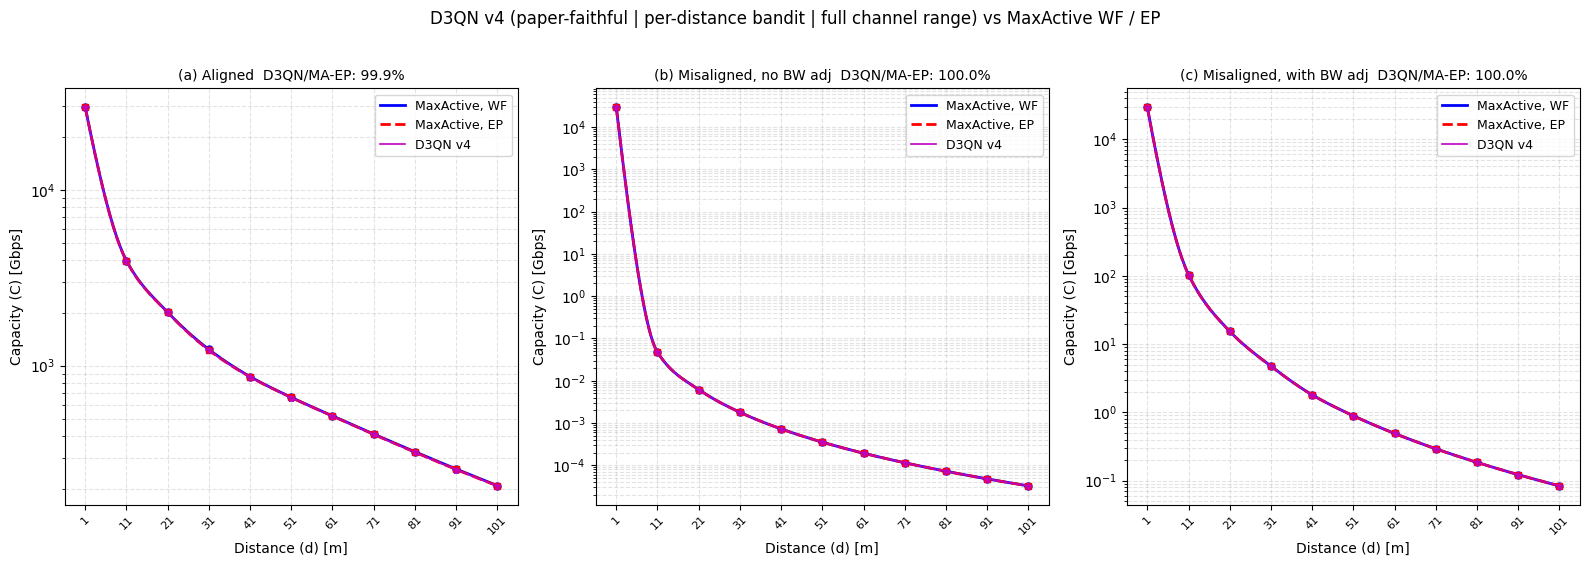

Saved: d3qn_v4_comparison.png


In [30]:
sc_order  = ['aligned', 'diag_noAdj', 'diag_Adj']
sc_titles = ['(a) Aligned', '(b) Misaligned, no BW adj', '(c) Misaligned, with BW adj']

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.suptitle('D3QN v4 (paper-faithful | per-distance bandit | full channel range) '
             'vs MaxActive WF / EP', fontsize=12, y=1.02)

sc_map_v4 = [
    ('aligned',    '(a) Aligned',                 cap_aligned_WF,    cap_aligned_EP),
    ('diag_noAdj', '(b) Misaligned, no BW adj',   cap_diag_noAdj_WF, cap_diag_noAdj_EP),
    ('diag_Adj',   '(c) Misaligned, with BW adj', cap_diag_Adj_WF,   cap_diag_Adj_EP),
]

for ax, (sc, title, ma_wf, ma_ep_full) in zip(axes, sc_map_v4):
    wf      = np.maximum(np.array(ma_wf)      / 1e9, 1e-12)
    ep_full = np.maximum(np.array(ma_ep_full)  / 1e9, 1e-12)
    d3_v4   = np.maximum(d3qn_v4_caps[sc]     / 1e9, 1e-12)

    slog(ax, dist_axis, wf,      color='b', marker='o', ls='-',  lw=2,   ms=5, label='MaxActive, WF')
    slog(ax, dist_axis, ep_full, color='r', marker='s', ls='--', lw=2,   ms=5, label='MaxActive, EP')
    slog(ax, dist_axis, d3_v4,   color='m', marker='*', ls='-',  lw=1.2, ms=5, zorder=5, label='D3QN v4')

    ratio = (d3qn_v4_caps[sc] / (ma_ep_v4_caps[sc] + 1e-12) * 100).mean()
    ax.set_title(f'{title}  D3QN/MA-EP: {ratio:.1f}%', fontsize=10)
    ax.set_xlabel('Distance (d) [m]', fontsize=10); ax.set_ylabel('Capacity (C) [Gbps]', fontsize=10)
    ax.set_xticks(dist_axis); ax.set_xticklabels(dist_axis, rotation=45, fontsize=8)
    ax.legend(fontsize=9, loc='upper right'); ax.grid(True, which='both', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.savefig('d3qn_v4_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: d3qn_v4_comparison.png')


In [31]:
print('Per-step D3QN v4 vs MaxActive EP - DIAGONAL scenarios only')
print('=' * 72)

for sc_name, xr, yr, zr, BeamWidthOptFlag in scenarios_v4:
    if 'diag' not in sc_name:
        continue
    print(f'\n--- {sc_name} ---')
    print(f'{"d(m)":>7} {"G(dB)":>7} {"n_D3QN":>7} {"MA_EP":>14} {"D3QN_EP":>12} {"ratio%":>8}')
    print('-' * 60)
    for k in range(N_STEPS):
        CoordRx_k = np.array([xr[k], yr[k], zr[k]])
        d3        = float(np.sqrt(np.sum((CoordRx_k - CoordTx_init)**2)))
        Ft, Ab, PL = load_lblrtm(d3 / 1000.0)
        bw_u = BeamWidth_deg
        if BeamWidthOptFlag:
            bw_u, _ = antenna_gain_optim(
                BeamWidth_deg, SideLobeStrength, TxPower_dBmW,
                CoordRx_k, CoordTx_init, tTxBS, pTxBS, tRxBS, pRxBS,
                ((Ft >= StartFreqTHz) & (Ft <= StopFreqTHz)).astype(int), PL, Ab, Ft)
        Gain_dB = total_antenna_gain_dB(
            CoordTx_init, CoordRx_k, tTxBS, pTxBS, tRxBS, pRxBS,
            bw_u, bw_u, SideLobeStrength, SideLobeStrength)
        ma_ep = ma_ep_v4_caps[sc_name][k] / 1e9
        d3_ep = d3qn_v4_caps[sc_name][k]  / 1e9
        n_d3  = d3qn_v4_n_sel[sc_name][k]
        ratio = d3_ep / (ma_ep + 1e-12) * 100
        print(f'{d3:>7.1f} {Gain_dB:>7.2f} {n_d3:>7d} {ma_ep:>14.5f} {d3_ep:>12.5f} {ratio:>7.1f}%')


Per-step D3QN v4 vs MaxActive EP - DIAGONAL scenarios only

--- diag_noAdj ---
   d(m)   G(dB)  n_D3QN          MA_EP      D3QN_EP   ratio%
------------------------------------------------------------
    1.0   52.31   10300    29412.26676  29412.25959   100.0%
   10.7  -20.00      18        0.04711      0.04711   100.0%
   20.7  -20.00       6        0.00620      0.00620   100.0%
   30.7  -20.00       4        0.00179      0.00179   100.0%
   40.7  -20.00       2        0.00072      0.00072   100.0%
   50.7  -20.00       2        0.00035      0.00035   100.0%
   60.7  -20.00       1        0.00019      0.00019   100.0%
   70.7  -20.00       2        0.00011      0.00011   100.0%
   80.7  -20.00       1        0.00007      0.00007   100.0%
   90.7  -20.00       1        0.00005      0.00005   100.0%
  100.7  -20.00       2        0.00003      0.00003   100.0%

--- diag_Adj ---
   d(m)   G(dB)  n_D3QN          MA_EP      D3QN_EP   ratio%
-------------------------------------------------

   70.7   14.14      44        0.29258      0.29258   100.0%
   80.7   14.14      32        0.18492      0.18492   100.0%
   90.7   14.14      19        0.12229      0.12229   100.0%
  100.7   14.14      16        0.08379      0.08379   100.0%


### Section O.2 - D3QN v4 Extended Visualizations

Additional plots to understand D3QN performance:
1. **D3QN/MaxActive EP ratio** per distance step for each scenario
2. **Channel selection comparison** - how many channels D3QN vs MaxActive selects
3. **Capacity gap analysis** - absolute difference between D3QN and MaxActive EP
4. **D3QN vs MaxActive EP scatter plot** - direct capacity correlation


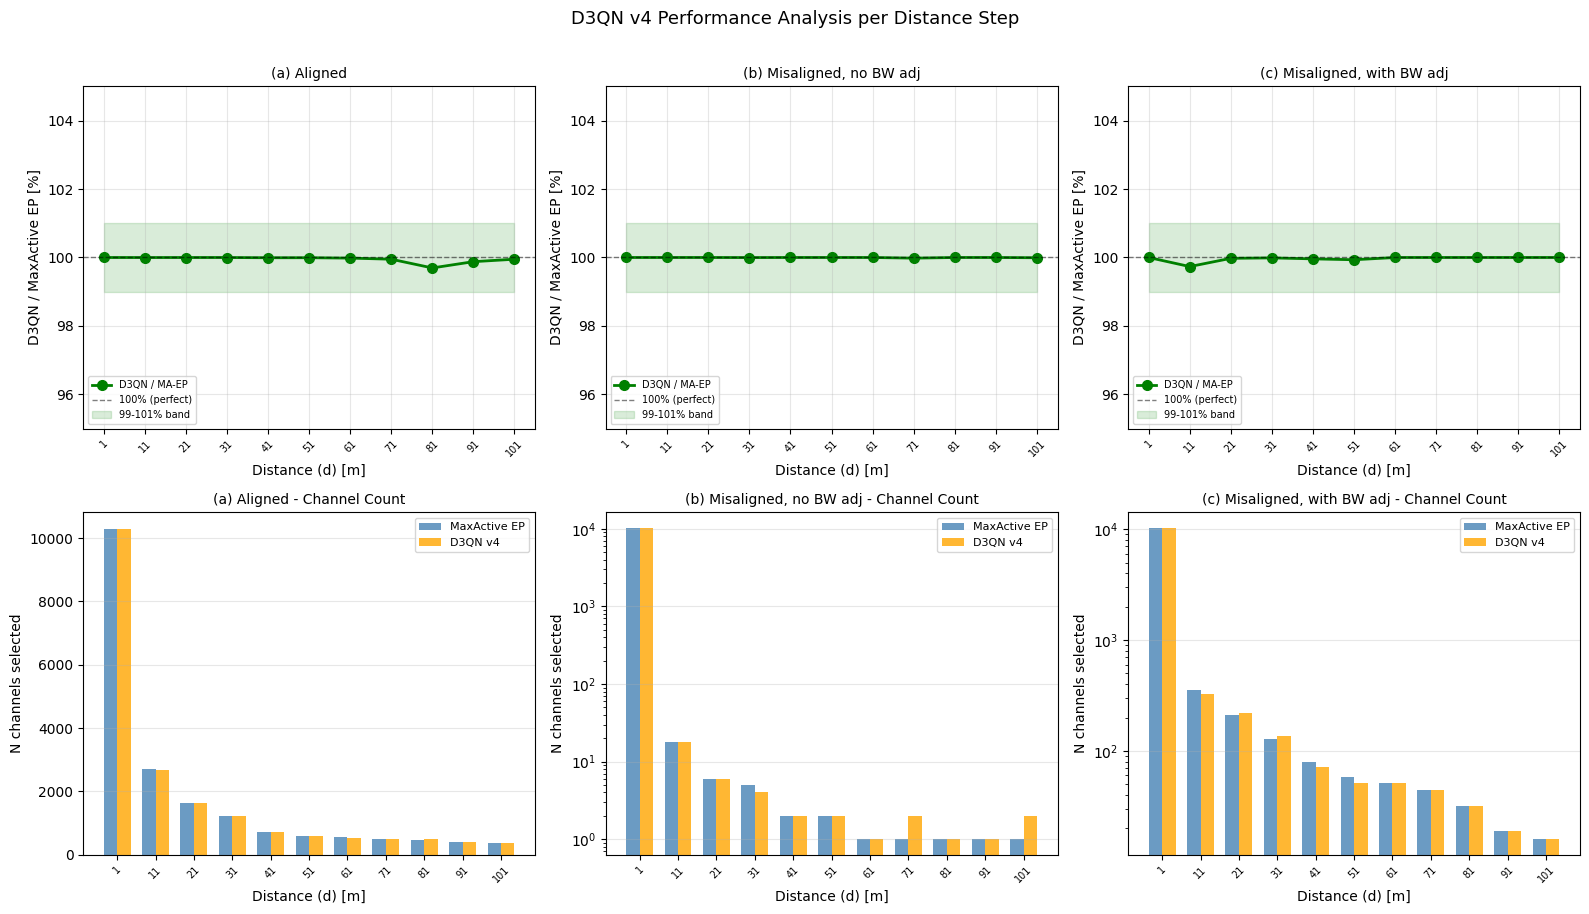

Saved: d3qn_v4_ratio_and_channels.png


In [32]:
# ── D3QN/MaxActive EP Ratio Curves + Channel Selection ────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('D3QN v4 Performance Analysis per Distance Step', fontsize=13, y=1.01)

sc_data_plot = [
    ('aligned',    '(a) Aligned'),
    ('diag_noAdj', '(b) Misaligned, no BW adj'),
    ('diag_Adj',   '(c) Misaligned, with BW adj'),
]

for col, (sc, title) in enumerate(sc_data_plot):
    ma_ep = ma_ep_v4_caps[sc]
    d3_ep = d3qn_v4_caps[sc]
    n_d3  = d3qn_v4_n_sel[sc]

    # Top row: D3QN/MA-EP ratio (%)
    ax = axes[0, col]
    ratio = d3_ep / (ma_ep + 1e-12) * 100
    ax.plot(dist_axis, ratio, 'go-', lw=2, ms=7, label='D3QN / MA-EP')
    ax.axhline(100, color='k', ls='--', lw=1, alpha=0.5, label='100% (perfect)')
    ax.fill_between(dist_axis, 99, 101, alpha=0.15, color='green', label='99-101% band')
    ax.set_ylim(95, 105)
    ax.set_xlabel('Distance (d) [m]')
    ax.set_ylabel('D3QN / MaxActive EP [%]')
    ax.set_title(title, fontsize=10)
    ax.set_xticks(dist_axis)
    ax.tick_params(axis='x', rotation=45, labelsize=7)
    ax.legend(fontsize=7, loc='lower left')
    ax.grid(True, alpha=0.3)

    # Bottom row: Number of channels selected
    ax = axes[1, col]
    # Get MaxActive optimal n_sel for comparison
    ma_n = []
    for k in range(N_STEPS):
        sc_info = scenarios_v4[['aligned','diag_noAdj','diag_Adj'].index(sc)]
        xr, yr, zr, bwo = sc_info[1], sc_info[2], sc_info[3], sc_info[4]
        CoordRx_k = np.array([xr[k], yr[k], zr[k]])
        d3 = float(np.sqrt(np.sum((CoordRx_k - CoordTx_init)**2)))
        Ft, Ab, PL = load_lblrtm(d3 / 1000.0)
        if bwo == 0:
            bw_u = BeamWidth_deg
        else:
            bw_u, _ = antenna_gain_optim(
                BeamWidth_deg, SideLobeStrength, TxPower_dBmW,
                CoordRx_k, CoordTx_init, tTxBS, pTxBS, tRxBS, pRxBS,
                ((Ft >= StartFreqTHz) & (Ft <= StopFreqTHz)).astype(int), PL, Ab, Ft)
        Gain_dB = total_antenna_gain_dB(
            CoordTx_init, CoordRx_k, tTxBS, pTxBS, tRxBS, pRxBS,
            bw_u, bw_u, SideLobeStrength, SideLobeStrength)
        APL_s, Pn_s, dF_s = get_sorted_channels_v4(Ft, PL, Ab, Gain_dB)
        _, n_opt = maxactive_ep_v4(APL_s, Pn_s, dF_s, Gain_dB)
        ma_n.append(n_opt)
    ma_n = np.array(ma_n)

    x = np.arange(len(dist_axis))
    w = 0.35
    ax.bar(x - w/2, ma_n, w, color='steelblue', alpha=0.8, label='MaxActive EP')
    ax.bar(x + w/2, n_d3, w, color='orange', alpha=0.8, label='D3QN v4')
    ax.set_xlabel('Distance (d) [m]')
    ax.set_ylabel('N channels selected')
    ax.set_title(title + ' - Channel Count', fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels(dist_axis, rotation=45, fontsize=7)
    ax.legend(fontsize=8)
    ax.grid(True, axis='y', alpha=0.3)
    if sc != 'aligned':
        ax.set_yscale('log')

plt.tight_layout()
plt.savefig('d3qn_v4_ratio_and_channels.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: d3qn_v4_ratio_and_channels.png')


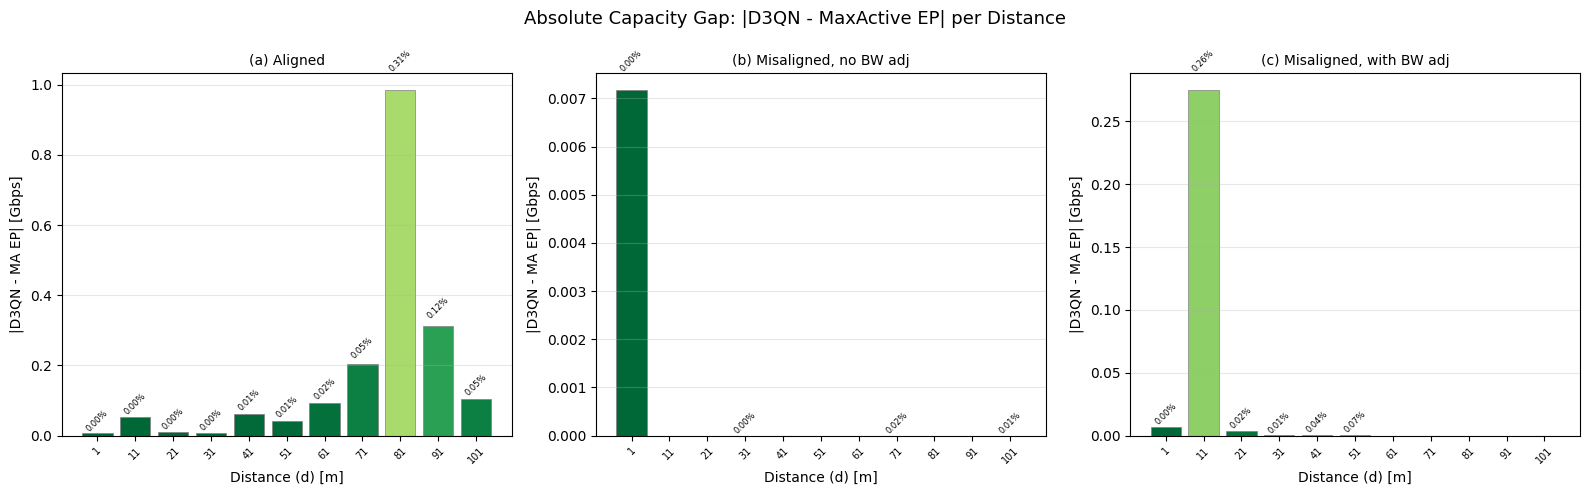

Saved: d3qn_v4_capacity_gap.png


In [33]:
# ── Capacity Gap Analysis (absolute and relative) ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Absolute Capacity Gap: |D3QN - MaxActive EP| per Distance', fontsize=13)

for col, (sc, title) in enumerate(sc_data_plot):
    ax = axes[col]
    ma_ep = ma_ep_v4_caps[sc] / 1e9
    d3_ep = d3qn_v4_caps[sc] / 1e9
    gap   = np.abs(d3_ep - ma_ep)
    pct   = gap / (ma_ep + 1e-12) * 100

    color_map = plt.cm.RdYlGn_r(pct / max(pct.max(), 1))  # red=big gap, green=small
    bars = ax.bar(range(len(dist_axis)), gap, color=color_map, edgecolor='gray', lw=0.5)

    # Add percentage labels on bars
    for i, (g, p) in enumerate(zip(gap, pct)):
        if g > 0:
            ax.text(i, g * 1.05, f'{p:.2f}%', ha='center', va='bottom', fontsize=6, rotation=45)

    ax.set_xlabel('Distance (d) [m]')
    ax.set_ylabel('|D3QN - MA EP| [Gbps]')
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(len(dist_axis)))
    ax.set_xticklabels(dist_axis, rotation=45, fontsize=7)
    ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('d3qn_v4_capacity_gap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: d3qn_v4_capacity_gap.png')


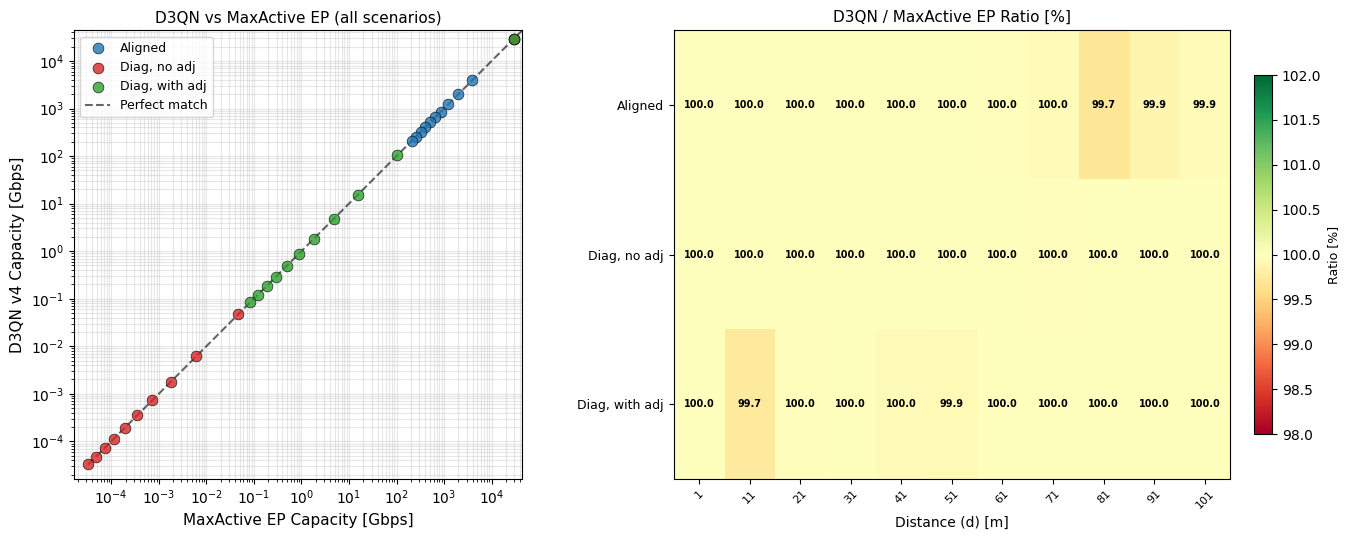

Saved: d3qn_v4_scatter_heatmap.png


In [34]:
# ── D3QN vs MaxActive EP Scatter + Ratio Heatmap ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: Scatter plot (log-log)
ax = axes[0]
colors_sc = {'aligned': '#1f77b4', 'diag_noAdj': '#d62728', 'diag_Adj': '#2ca02c'}
labels_sc = {'aligned': 'Aligned', 'diag_noAdj': 'Diag, no adj', 'diag_Adj': 'Diag, with adj'}

all_ma = []; all_d3 = []
for sc in ['aligned', 'diag_noAdj', 'diag_Adj']:
    ma = ma_ep_v4_caps[sc] / 1e9
    d3 = d3qn_v4_caps[sc] / 1e9
    ax.scatter(ma, d3, c=colors_sc[sc], s=60, alpha=0.8, edgecolors='k', lw=0.5,
              label=labels_sc[sc], zorder=5)
    all_ma.extend(ma); all_d3.extend(d3)

all_ma = np.array(all_ma); all_d3 = np.array(all_d3)
vmin = max(min(all_ma.min(), all_d3.min()), 1e-6)
vmax = max(all_ma.max(), all_d3.max()) * 1.5
ax.plot([vmin, vmax], [vmin, vmax], 'k--', lw=1.5, alpha=0.6, label='Perfect match')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(vmin * 0.5, vmax); ax.set_ylim(vmin * 0.5, vmax)
ax.set_xlabel('MaxActive EP Capacity [Gbps]', fontsize=11)
ax.set_ylabel('D3QN v4 Capacity [Gbps]', fontsize=11)
ax.set_title('D3QN vs MaxActive EP (all scenarios)', fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, which='both', alpha=0.3)
ax.set_aspect('equal')

# Right: Ratio heatmap (scenarios x distances)
ax = axes[1]
sc_names = ['aligned', 'diag_noAdj', 'diag_Adj']
sc_labels = ['Aligned', 'Diag, no adj', 'Diag, with adj']
ratio_matrix = np.zeros((3, N_STEPS))
for i, sc in enumerate(sc_names):
    ratio_matrix[i, :] = d3qn_v4_caps[sc] / (ma_ep_v4_caps[sc] + 1e-12) * 100

im = ax.imshow(ratio_matrix, aspect='auto', cmap='RdYlGn',
               vmin=98, vmax=102, interpolation='nearest')
ax.set_xticks(range(N_STEPS))
ax.set_xticklabels(dist_axis, rotation=45, fontsize=8)
ax.set_yticks(range(3))
ax.set_yticklabels(sc_labels, fontsize=9)
ax.set_xlabel('Distance (d) [m]')
ax.set_title('D3QN / MaxActive EP Ratio [%]', fontsize=11)

# Annotate each cell with value
for i in range(3):
    for j in range(N_STEPS):
        val = ratio_matrix[i, j]
        ax.text(j, i, f'{val:.1f}', ha='center', va='center', fontsize=7,
                color='black' if 99 < val < 101 else 'white', fontweight='bold')

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.04)
cbar.set_label('Ratio [%]', fontsize=9)

plt.tight_layout()
plt.savefig('d3qn_v4_scatter_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: d3qn_v4_scatter_heatmap.png')


---
## Section P – Supervised ML Baselines (Improved v2)

Improvements over v1:
- **Richer features** (13 total) including per-subband log-SNR statistics
- **Log-transform on distance** already applied; capacity target in log10(Gbps)
- **Corrected distances** [1, 11, 21, ..., 101] m used

**Features (13):**
log10_dist, Gain_dB, bw_norm, scenario_id, alloc_flag,
mean_log_SNR, std_log_SNR, mean_log_noise, std_log_noise, valid_frac,
log10_dist², Gain_dB_sq_norm, mean_PL_norm

**Target:** log10(capacity in Gbps). **Split:** 75% train / 25% test, stratified by scenario.

In [35]:
from sklearn.preprocessing  import StandardScaler
from sklearn.linear_model   import Ridge, ElasticNet
from sklearn.tree           import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble       import (RandomForestRegressor, GradientBoostingRegressor)
from sklearn.neighbors      import KNeighborsRegressor
from sklearn.model_selection import (GridSearchCV, StratifiedShuffleSplit, KFold)
from sklearn.metrics        import (mean_squared_error, mean_absolute_error, r2_score)
import xgboost as xgb

def build_features_v2(sample, alloc='WF'):
    """Improved feature set with log-SNR, log-dist, and polynomial terms."""
    vl   = sample['sb_valid']
    pl   = sample['sb_PL'][vl]       # mean path-loss per valid subband
    nn   = sample['sb_noise'][vl]    # log10(noise) per valid subband

    # log-SNR per subband = (TxPower_dBW + Gain_dB - PL) / 10  (log10 scale proxy)
    snr_log = (TxPower_dBW + sample['Gain_dB'] - pl) / 10.0

    log_d  = np.log10(sample['dist_3d'] + 1)
    g_norm = sample['Gain_dB'] / 60.0
    bw_n   = sample['bw_used'] / 360.0
    vfrac  = float(vl.sum()) / Nmax

    return np.array([
        log_d,                          # 0: log10(dist+1)
        g_norm,                         # 1: gain normalised
        bw_n,                           # 2: beamwidth normalised
        float(sample['scenario_id']),   # 3: scenario id
        1.0 if alloc == 'WF' else 0.0, # 4: allocation flag
        snr_log.mean(),                 # 5: mean log-SNR per valid subband
        snr_log.std() if len(snr_log)>1 else 0.0,  # 6: std log-SNR
        nn.mean(),                      # 7: mean log10(noise)
        nn.std() if len(nn)>1 else 0.0, # 8: std log10(noise)
        vfrac,                          # 9: valid subband fraction
        log_d ** 2,                     # 10: quadratic distance term
        g_norm ** 2,                    # 11: quadratic gain term
        pl.mean() / 200.0,              # 12: normalised mean total path-loss
    ], dtype=np.float32)


X_rows, y_WF, y_EP, scen_labels = [], [], [], []
for s in dataset:
    X_rows.append(build_features_v2(s, 'WF'))
    y_WF.append(s['cap_MA_WF'])
    y_EP.append(s['cap_MA_EP'])
    scen_labels.append(s['scenario_id'])

X      = np.array(X_rows)
yW     = np.log10(np.maximum(np.array(y_WF)/1e9, 1e-12))
yE     = np.log10(np.maximum(np.array(y_EP)/1e9, 1e-12))
labels = np.array(scen_labels)

print(f'Feature matrix v2: {X.shape}  ({X.shape[1]} features)')
print(f'WF target log10(Gbps): [{yW.min():.2f}, {yW.max():.2f}]')
print(f'EP target log10(Gbps): [{yE.min():.2f}, {yE.max():.2f}]')
print()
feat_names_v2 = [
    'log10_dist','gain_norm','bw_norm','scenario_id','alloc_flag',
    'mean_log_SNR','std_log_SNR','mean_log_noise','std_log_noise','valid_frac',
    'log_dist_sq','gain_sq','mean_PL_norm'
]
for i,(n,v) in enumerate(zip(feat_names_v2, X[0])):
    print(f'  feature {i:2d} {n:20s}: {v:.4f}')

Feature matrix v2: (33, 13)  (13 features)
WF target log10(Gbps): [-4.49, 4.47]
EP target log10(Gbps): [-4.49, 4.47]

  feature  0 log10_dist          : 0.3010
  feature  1 gain_norm           : 0.8718
  feature  2 bw_norm             : 0.0278
  feature  3 scenario_id         : 0.0000
  feature  4 alloc_flag          : 1.0000
  feature  5 mean_log_SNR        : -6.5691
  feature  6 std_log_SNR         : 1.1968
  feature  7 mean_log_noise      : -12.2623
  feature  8 std_log_noise       : 0.2506
  feature  9 valid_frac          : 1.0000
  feature 10 log_dist_sq         : 0.0906
  feature 11 gain_sq             : 0.7601
  feature 12 mean_PL_norm        : 0.5600


In [36]:
# Train / Test split
splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, labels))

X_train, X_test = X[train_idx], X[test_idx]
yW_tr, yW_te    = yW[train_idx], yW[test_idx]
yE_tr, yE_te    = yE[train_idx], yE[test_idx]
lbl_te          = labels[test_idx]

print(f'Train: {len(train_idx)} | Test: {len(test_idx)}')


Train: 24 | Test: 9


In [37]:
# Training helpers
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def eval_preds(y_te, pred, name=''):
    rmse = float(np.sqrt(mean_squared_error(y_te, pred)))
    mae  = float(mean_absolute_error(y_te, pred))
    r2   = float(r2_score(y_te, pred))
    mape = float(np.mean(np.abs(10**pred - 10**y_te)/(10**y_te+1e-12))*100)
    if name:
        print(f'  {name:30s}  RMSE={rmse:.3f}  MAE={mae:.3f}  '
              f'R2={r2:.3f}  MAPE={mape:.1f}%')
    return dict(rmse=rmse, mae=mae, r2=r2, mape=mape)


def fit_model(name, estimator, X_tr, y_tr, X_te, y_te, scale=True):
    sc   = StandardScaler() if scale else None
    Xtr  = sc.fit_transform(X_tr) if sc else X_tr
    Xte  = sc.transform(X_te)     if sc else X_te
    estimator.fit(Xtr, y_tr)
    pred     = estimator.predict(Xte)
    pred_all = estimator.predict(sc.transform(X) if sc else X)
    m = eval_preds(y_te, pred, name)
    return dict(name=name, model=estimator, scaler=sc,
                pred=pred, pred_all=pred_all, **m)


def gs_fit(name, base, param_grid, X_tr, y_tr, X_te, y_te, scale=True):
    sc   = StandardScaler() if scale else None
    Xtr  = sc.fit_transform(X_tr) if sc else X_tr
    Xte  = sc.transform(X_te)     if sc else X_te
    gs   = GridSearchCV(base, param_grid, cv=cv,
                        scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
    gs.fit(Xtr, y_tr)
    best     = gs.best_estimator_
    pred     = best.predict(Xte)
    pred_all = best.predict(sc.transform(X) if sc else X)
    m = eval_preds(y_te, pred, name)
    print(f'    best params: {gs.best_params_}')
    return dict(name=name, model=best, scaler=sc,
                pred=pred, pred_all=pred_all, **m)


# Train WF models
print('=== MaxActive WF target ===')
results_WF = {}

results_WF['Ridge'] = gs_fit(
    'Ridge', Ridge(), {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]},
    X_train, yW_tr, X_test, yW_te)

results_WF['ElasticNet'] = gs_fit(
    'ElasticNet', ElasticNet(max_iter=10000),
    {'alpha': [1e-3, 1e-2, 1e-1, 1.0], 'l1_ratio': [0.2, 0.5, 0.8]},
    X_train, yW_tr, X_test, yW_te)

results_WF['DecisionTree'] = gs_fit(
    'DecisionTree', DecisionTreeRegressor(random_state=42),
    {'max_depth': [2,3,5,None], 'min_samples_split': [2,4,8]},
    X_train, yW_tr, X_test, yW_te, scale=False)

results_WF['KNN'] = gs_fit(
    'KNN', KNeighborsRegressor(),
    {'n_neighbors': [2,3,5], 'weights': ['uniform','distance']},
    X_train, yW_tr, X_test, yW_te)

results_WF['MLP'] = gs_fit(
    'MLP',
    MLPRegressor(max_iter=2000, early_stopping=True,
                 validation_fraction=0.15, random_state=42),
    {'hidden_layer_sizes': [(64,32),(128,64),(128,64,32)],
     'alpha': [1e-4,1e-3,1e-2], 'learning_rate_init': [1e-3,5e-4]},
    X_train, yW_tr, X_test, yW_te)

results_WF['RandomForest'] = gs_fit(
    'RandomForest', RandomForestRegressor(random_state=42),
    {'n_estimators': [100,200,500], 'max_depth': [None,5,10],
     'min_samples_split': [2,5]},
    X_train, yW_tr, X_test, yW_te, scale=False)

results_WF['XGBoost'] = gs_fit(
    'XGBoost', xgb.XGBRegressor(random_state=42, verbosity=0, n_jobs=-1),
    {'n_estimators': [100,200,500], 'max_depth': [3,5,7],
     'learning_rate': [0.01,0.05,0.1], 'subsample': [0.8,1.0]},
    X_train, yW_tr, X_test, yW_te, scale=False)

results_WF['GradBoost'] = gs_fit(
    'GradBoost', GradientBoostingRegressor(random_state=42),
    {'n_estimators': [100,200], 'max_depth': [3,5],
     'learning_rate': [0.05,0.1,0.2]},
    X_train, yW_tr, X_test, yW_te, scale=False)


=== MaxActive WF target ===


  Ridge                           RMSE=0.298  MAE=0.233  R2=0.990  MAPE=43.8%
    best params: {'alpha': 1.0}
  ElasticNet                      RMSE=0.248  MAE=0.183  R2=0.993  MAPE=35.4%
    best params: {'alpha': 0.01, 'l1_ratio': 0.8}
  DecisionTree                    RMSE=0.583  MAE=0.367  R2=0.961  MAPE=462.1%
    best params: {'max_depth': None, 'min_samples_split': 2}
  KNN                             RMSE=0.370  MAE=0.177  R2=0.984  MAPE=20.5%
    best params: {'n_neighbors': 2, 'weights': 'distance'}


  MLP                             RMSE=0.292  MAE=0.202  R2=0.990  MAPE=39.5%
    best params: {'alpha': 0.0001, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.0005}


  RandomForest                    RMSE=0.400  MAE=0.313  R2=0.981  MAPE=51.3%
    best params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}


  XGBoost                         RMSE=0.354  MAE=0.276  R2=0.985  MAPE=41.7%
    best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500, 'subsample': 0.8}


  GradBoost                       RMSE=0.725  MAE=0.490  R2=0.939  MAPE=374.5%
    best params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}


In [38]:
# Train EP models
print('=== MaxActive EP target ===')
results_EP = {}

results_EP['Ridge'] = gs_fit(
    'Ridge', Ridge(), {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]},
    X_train, yE_tr, X_test, yE_te)

results_EP['ElasticNet'] = gs_fit(
    'ElasticNet', ElasticNet(max_iter=10000),
    {'alpha': [1e-3, 1e-2, 1e-1, 1.0], 'l1_ratio': [0.2, 0.5, 0.8]},
    X_train, yE_tr, X_test, yE_te)

results_EP['DecisionTree'] = gs_fit(
    'DecisionTree', DecisionTreeRegressor(random_state=42),
    {'max_depth': [2,3,5,None], 'min_samples_split': [2,4,8]},
    X_train, yE_tr, X_test, yE_te, scale=False)

results_EP['KNN'] = gs_fit(
    'KNN', KNeighborsRegressor(),
    {'n_neighbors': [2,3,5], 'weights': ['uniform','distance']},
    X_train, yE_tr, X_test, yE_te)

results_EP['MLP'] = gs_fit(
    'MLP',
    MLPRegressor(max_iter=2000, early_stopping=True,
                 validation_fraction=0.15, random_state=42),
    {'hidden_layer_sizes': [(64,32),(128,64),(128,64,32)],
     'alpha': [1e-4,1e-3,1e-2], 'learning_rate_init': [1e-3,5e-4]},
    X_train, yE_tr, X_test, yE_te)

results_EP['RandomForest'] = gs_fit(
    'RandomForest', RandomForestRegressor(random_state=42),
    {'n_estimators': [100,200,500], 'max_depth': [None,5,10],
     'min_samples_split': [2,5]},
    X_train, yE_tr, X_test, yE_te, scale=False)

results_EP['XGBoost'] = gs_fit(
    'XGBoost', xgb.XGBRegressor(random_state=42, verbosity=0, n_jobs=-1),
    {'n_estimators': [100,200,500], 'max_depth': [3,5,7],
     'learning_rate': [0.01,0.05,0.1], 'subsample': [0.8,1.0]},
    X_train, yE_tr, X_test, yE_te, scale=False)

results_EP['GradBoost'] = gs_fit(
    'GradBoost', GradientBoostingRegressor(random_state=42),
    {'n_estimators': [100,200], 'max_depth': [3,5],
     'learning_rate': [0.05,0.1,0.2]},
    X_train, yE_tr, X_test, yE_te, scale=False)


=== MaxActive EP target ===
  Ridge                           RMSE=0.298  MAE=0.233  R2=0.990  MAPE=43.9%
    best params: {'alpha': 1.0}
  ElasticNet                      RMSE=0.248  MAE=0.183  R2=0.993  MAPE=35.5%
    best params: {'alpha': 0.01, 'l1_ratio': 0.8}
  DecisionTree                    RMSE=0.583  MAE=0.366  R2=0.961  MAPE=462.3%
    best params: {'max_depth': None, 'min_samples_split': 2}
  KNN                             RMSE=0.369  MAE=0.177  R2=0.984  MAPE=20.6%
    best params: {'n_neighbors': 2, 'weights': 'distance'}


  MLP                             RMSE=0.292  MAE=0.201  R2=0.990  MAPE=39.4%
    best params: {'alpha': 0.0001, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.0005}


  RandomForest                    RMSE=0.372  MAE=0.292  R2=0.984  MAPE=47.6%
    best params: {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 100}


  XGBoost                         RMSE=0.352  MAE=0.276  R2=0.986  MAPE=42.1%
    best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500, 'subsample': 0.8}


  GradBoost                       RMSE=0.714  MAE=0.482  R2=0.941  MAPE=383.0%
    best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}


In [39]:
# ── Extended ML model zoo (additional diverse families) ──────────────────────
# Adds linear/robust/probabilistic, kernel, and ensemble regressors on top of the
# original 8, so we can compare how closely each MODEL FAMILY tracks the MaxActive
# curve. D3QN and everything else are unchanged. Downstream plots, the overshoot
# table, and the summary all iterate over results_WF / results_EP, so these models
# are included automatically. Reuses fit_model / gs_fit / cv defined above.
from sklearn.linear_model     import LinearRegression, Lasso, BayesianRidge, HuberRegressor
from sklearn.svm              import SVR
from sklearn.kernel_ridge     import KernelRidge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel
from sklearn.ensemble         import (ExtraTreesRegressor, AdaBoostRegressor,
                                      BaggingRegressor)
import sklearn.base as _skb

_gp_kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1e-2)

# name -> (kind, estimator, param_grid|None, scale_inputs)
EXTRA_MODELS = {
    'LinearReg':     ('simple', LinearRegression(),                       None, True),
    'Lasso':         ('grid',   Lasso(max_iter=10000),
                      {'alpha': [1e-3, 1e-2, 1e-1, 1.0]},                        True),
    'BayesianRidge': ('simple', BayesianRidge(),                          None, True),
    'Huber':         ('grid',   HuberRegressor(max_iter=2000),
                      {'epsilon': [1.2, 1.35, 1.5], 'alpha': [1e-4, 1e-3, 1e-2]}, True),
    'SVR_RBF':       ('grid',   SVR(kernel='rbf'),
                      {'C': [1, 10, 100], 'gamma': ['scale', 0.1, 1.0],
                       'epsilon': [0.01, 0.1]},                                  True),
    'KernelRidge':   ('grid',   KernelRidge(kernel='rbf'),
                      {'alpha': [1e-2, 1e-1, 1.0], 'gamma': [0.1, 1.0, 10.0]},   True),
    'GaussProc':     ('simple', GaussianProcessRegressor(kernel=_gp_kernel,
                      normalize_y=True, alpha=1e-6, random_state=42),     None, True),
    'ExtraTrees':    ('grid',   ExtraTreesRegressor(random_state=42),
                      {'n_estimators': [100, 300], 'max_depth': [None, 5, 10]},  False),
    'AdaBoost':      ('grid',   AdaBoostRegressor(random_state=42),
                      {'n_estimators': [50, 100, 200], 'learning_rate': [0.05, 0.1, 0.5]}, False),
    'Bagging':       ('grid',   BaggingRegressor(random_state=42),
                      {'n_estimators': [50, 100, 200]},                          False),
}


def _train_extra(y_tr, y_te, tag):
    print(f'=== Extra models: MaxActive {tag} target ===')
    out = {}
    for name, (kind, est, grid, scale) in EXTRA_MODELS.items():
        e = _skb.clone(est)
        if kind == 'grid':
            out[name] = gs_fit(name, e, grid, X_train, y_tr, X_test, y_te, scale=scale)
        else:
            out[name] = fit_model(name, e, X_train, y_tr, X_test, y_te, scale=scale)
    return out

results_WF.update(_train_extra(yW_tr, yW_te, 'WF'))
results_EP.update(_train_extra(yE_tr, yE_te, 'EP'))

print(f'\nTotal ML models now: {len(results_WF)}')
print('  ' + ', '.join(results_WF.keys()))


=== Extra models: MaxActive WF target ===
  LinearReg                       RMSE=0.284  MAE=0.211  R2=0.991  MAPE=74.9%
  Lasso                           RMSE=0.249  MAE=0.184  R2=0.993  MAPE=35.6%
    best params: {'alpha': 0.01}
  BayesianRidge                   RMSE=0.250  MAE=0.178  R2=0.993  MAPE=34.0%
  Huber                           RMSE=0.183  MAE=0.112  R2=0.996  MAPE=30.9%
    best params: {'alpha': 0.01, 'epsilon': 1.35}


  SVR_RBF                         RMSE=0.306  MAE=0.160  R2=0.989  MAPE=21.6%
    best params: {'C': 10, 'epsilon': 0.01, 'gamma': 0.1}
  KernelRidge                     RMSE=0.425  MAE=0.224  R2=0.979  MAPE=26.4%
    best params: {'alpha': 0.01, 'gamma': 0.1}
  GaussProc                       RMSE=0.008  MAE=0.006  R2=1.000  MAPE=1.5%


  ExtraTrees                      RMSE=0.330  MAE=0.155  R2=0.987  MAPE=20.2%
    best params: {'max_depth': None, 'n_estimators': 300}


  AdaBoost                        RMSE=0.405  MAE=0.306  R2=0.981  MAPE=62.5%
    best params: {'learning_rate': 0.5, 'n_estimators': 200}


  Bagging                         RMSE=0.349  MAE=0.279  R2=0.986  MAPE=46.6%
    best params: {'n_estimators': 100}
=== Extra models: MaxActive EP target ===
  LinearReg                       RMSE=0.284  MAE=0.210  R2=0.991  MAPE=74.6%
  Lasso                           RMSE=0.249  MAE=0.184  R2=0.993  MAPE=35.7%
    best params: {'alpha': 0.01}
  BayesianRidge                   RMSE=0.249  MAE=0.178  R2=0.993  MAPE=34.1%
  Huber                           RMSE=0.183  MAE=0.112  R2=0.996  MAPE=30.9%
    best params: {'alpha': 0.01, 'epsilon': 1.35}
  SVR_RBF                         RMSE=0.306  MAE=0.159  R2=0.989  MAPE=21.4%
    best params: {'C': 10, 'epsilon': 0.01, 'gamma': 0.1}


  KernelRidge                     RMSE=0.425  MAE=0.224  R2=0.979  MAPE=26.3%
    best params: {'alpha': 0.01, 'gamma': 0.1}
  GaussProc                       RMSE=0.008  MAE=0.007  R2=1.000  MAPE=1.5%


  ExtraTrees                      RMSE=0.333  MAE=0.141  R2=0.987  MAPE=16.4%
    best params: {'max_depth': None, 'n_estimators': 300}


  AdaBoost                        RMSE=0.413  MAE=0.315  R2=0.980  MAPE=65.4%
    best params: {'learning_rate': 0.5, 'n_estimators': 100}


  Bagging                         RMSE=0.357  MAE=0.282  R2=0.985  MAPE=46.5%
    best params: {'n_estimators': 100}

Total ML models now: 18
  Ridge, ElasticNet, DecisionTree, KNN, MLP, RandomForest, XGBoost, GradBoost, LinearReg, Lasso, BayesianRidge, Huber, SVR_RBF, KernelRidge, GaussProc, ExtraTrees, AdaBoost, Bagging


## Section Q – Evaluation, Comparison Plots, and Summary

**Main figure:** 3 scenarios × 2 allocations = 6 subplots.  
- Left column: MaxActive **WF** true curve + ML-WF predictions  
- Right column: MaxActive **EP** true curve + ML-EP predictions + D3QN  

Additional: metrics bar charts, scatter plots, feature importances, summary table.

In [40]:
# Colour/marker style per model
STYLE = {
    'Ridge':        ('#4878D0', 'P--',  1.4),
    'ElasticNet':   ('#EE854A', 'X--',  1.4),
    'DecisionTree': ('#6ACC65', 'D:',   1.4),
    'KNN':          ('#D65F5F', 'v:',   1.4),
    'MLP':          ('#956CB4', 'h-.',  1.4),
    'RandomForest': ('#8C613C', 's-.',  1.4),
    'XGBoost':      ('#DC7EC0', '^--',  1.4),
    'GradBoost':    ('#797979', 'o:',   1.4),
    # ── extended model zoo ──
    'LinearReg':     ('#1f77b4', 'P-',  1.2),
    'Lasso':         ('#ff7f0e', 'X-',  1.2),
    'BayesianRidge': ('#2ca02c', 'p-',  1.2),
    'Huber':         ('#EE854A', '<-',  1.2),   # orange: was #9467bd, indistinguishable from MLP's purple
    'SVR_RBF':       ('#8c564b', '>-',  1.2),
    'KernelRidge':   ('#e377c2', 'H-',  1.2),
    'GaussProc':     ('#7f7f7f', 'd-',  1.2),
    'ExtraTrees':    ('#bcbd22', 's:',  1.2),
    'AdaBoost':      ('#aec7e8', 'v-.', 1.2),
    'Bagging':       ('#ffbb78', '^:',  1.2),
    'D3QN':         ('#17becf', '*-',   2.4),
}

def predict_curve(res, sc_name, alloc='WF'):
    sc_samp = sorted([s for s in dataset if s['scenario'] == sc_name],
                     key=lambda s: s['step'])
    X_sc = np.array([build_features_v2(s, alloc) for s in sc_samp])
    sc   = res['scaler']
    Xsc  = sc.transform(X_sc) if sc else X_sc
    return 10 ** res['model'].predict(Xsc)


# ── Display curves fit on ALL 33 samples (illustrative "best fit") ───────────
# The 75/25 split (Sec. Q) and nested CV (Sec. S) are for HONEST generalisation
# error. For the comparison FIGURE we refit each tuned model on the full dataset
# — the model you would actually deploy with all available data — so capable
# models track MaxActive as tightly as the data allows. This does NOT change any
# reported metric; generalisation error stays in Section S.
from sklearn.base import clone as _clone_est

def _fit_full(res, y_full):
    if res['scaler'] is not None:
        scaler = StandardScaler().fit(X); Xf = scaler.transform(X)
    else:
        scaler = None; Xf = X
    m = _clone_est(res['model']); m.fit(Xf, y_full)
    return m, scaler

full_WF = {n: _fit_full(r, yW) for n, r in results_WF.items()}
full_EP = {n: _fit_full(r, yE) for n, r in results_EP.items()}

def predict_curve_full(name, sc_name, alloc='WF'):
    m, scaler = (full_WF if alloc == 'WF' else full_EP)[name]
    sc_samp = sorted([s for s in dataset if s['scenario'] == sc_name],
                     key=lambda s: s['step'])
    X_sc = np.array([build_features_v2(s, alloc) for s in sc_samp])
    Xin  = scaler.transform(X_sc) if scaler is not None else X_sc
    return 10 ** m.predict(Xin)

print(f'Full-data display models fitted: {len(full_WF)} WF + {len(full_EP)} EP')


Full-data display models fitted: 18 WF + 18 EP


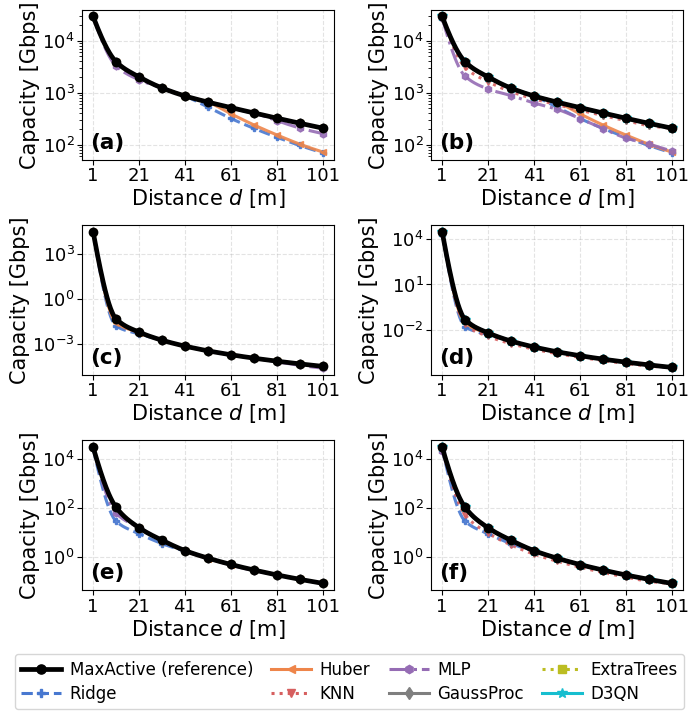

Saved: all_methods_comparison.png  (authored at printed size, shared legend)


In [41]:
from matplotlib.lines import Line2D

sc_order = ['aligned', 'diag_noAdj', 'diag_Adj']

# Physical optimality constraint: no predictor may exceed MaxActive, so every predicted
# curve is clipped to min(pred, MaxActive). The clip is an offline-evaluation device --
# it uses the reference value and is NOT part of the online prediction path.
# Curves are PCHIP-smoothed (display only); markers mark the true computed points.
CLIP_TO_MAXACTIVE = True

# -- Presentation: the figure is authored at its FINAL PRINTED SIZE (IEEE two-column
# textwidth = 7.16 in) with journal-scale fonts, so nothing shrinks when it is placed in
# the paper. No titles: panels carry tags (a)-(f) and share one legend.
FS_LAB, FS_TICK, FS_LEG, FS_TAG = 15.0, 13.0, 12.0, 15.5

# Paper figures show ONE REPRESENTATIVE PER MODEL FAMILY, not all 18: the complete
# 18-model comparison is tabulated (nested-CV table), and plotting every model made the
# panels unreadable. Families: regularized-linear, robust, instance-based, neural,
# kernel/probabilistic, tree ensemble.
FIG_MODELS = ['Ridge', 'Huber', 'KNN', 'MLP', 'GaussProc', 'ExtraTrees']
tags = [['(a)', '(b)'], ['(c)', '(d)'], ['(e)', '(f)']]

fig, axes = plt.subplots(3, 2, figsize=(7.16, 7.3))

for row, sc_name in enumerate(sc_order):
    sc_samp = sorted([s for s in dataset if s['scenario'] == sc_name], key=lambda s: s['step'])
    y_ma_wf = np.array([s['cap_MA_WF'] / 1e9 for s in sc_samp])
    y_ma_ep = np.array([s['cap_MA_EP'] / 1e9 for s in sc_samp])

    for col, (alloc, y_ma, results) in enumerate([('WF', y_ma_wf, results_WF),
                                                  ('EP', y_ma_ep, results_EP)]):
        ax = axes[row, col]
        slog(ax, dist_axis, np.maximum(y_ma, 1e-12), color='k', marker='o', ls='-',
             lw=3.4, ms=6.0, zorder=6)
        for mname in FIG_MODELS:
            y_pred = predict_curve_full(mname, sc_name, alloc)
            if CLIP_TO_MAXACTIVE:
                y_pred = np.minimum(y_pred, y_ma)
            c, mk, lw = STYLE.get(mname, ('gray', 'o-', 1.2))
            mkc, lsc = _mk_ls(mk)
            slog(ax, dist_axis, np.maximum(y_pred, 1e-12), color=c, marker=mkc, ls=lsc,
                 lw=2.2, ms=5.0, alpha=0.9)
        if col == 1:
            c, mk, lw = STYLE['D3QN']
            y_d3 = d3qn_results[sc_name] / 1e9
            if CLIP_TO_MAXACTIVE:
                y_d3 = np.minimum(y_d3, y_ma)
            slog(ax, dist_axis, np.maximum(y_d3, 1e-12), color=c, marker='*', ls='-',
                 lw=2.4, ms=7.0, alpha=0.95, zorder=5)

        ax.set_xlabel('Distance $d$ [m]', fontsize=FS_LAB, labelpad=1.5)
        ax.set_ylabel('Capacity [Gbps]', fontsize=FS_LAB, labelpad=1.5)
        ax.set_xticks(dist_axis[::2])
        ax.tick_params(axis='both', which='major', labelsize=FS_TICK, pad=1.5)
        ax.grid(True, which='major', ls='--', alpha=0.35)
        ax.text(0.035, 0.05, tags[row][col], transform=ax.transAxes, fontsize=FS_TAG,
                fontweight='bold', va='bottom', ha='left')

# -- one shared legend for the whole figure (replaces six crowded per-panel legends) --
def _legend_handles(model_names, with_d3qn=True, lw_ref=3.4, lw_m=2.2, ms=6.0):
    h = [Line2D([], [], color='k', ls='-', marker='o', lw=lw_ref, ms=ms + 0.6,
                label='MaxActive (reference)')]
    for n in model_names:
        c, mk, lw = STYLE.get(n, ('gray', 'o-', 1.2))
        mkc, lsc = _mk_ls(mk)
        h.append(Line2D([], [], color=c, ls=lsc, marker=mkc, lw=lw_m, ms=ms, label=n))
    if with_d3qn:
        h.append(Line2D([], [], color=STYLE['D3QN'][0], ls='-', marker='*', lw=lw_m,
                        ms=ms + 1.2, label='D3QN'))
    return h

handles = _legend_handles(FIG_MODELS)
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=FS_LEG,
           frameon=True, bbox_to_anchor=(0.5, 0.0), columnspacing=1.1,
           handlelength=2.4, handletextpad=0.5, borderpad=0.4, labelspacing=0.35)
fig.tight_layout(rect=[0.005, 0.085, 0.995, 0.99], h_pad=1.1, w_pad=1.4)
plt.savefig('all_methods_comparison.png', dpi=400, bbox_inches='tight')
plt.show()
print('Saved: all_methods_comparison.png  (authored at printed size, shared legend)')

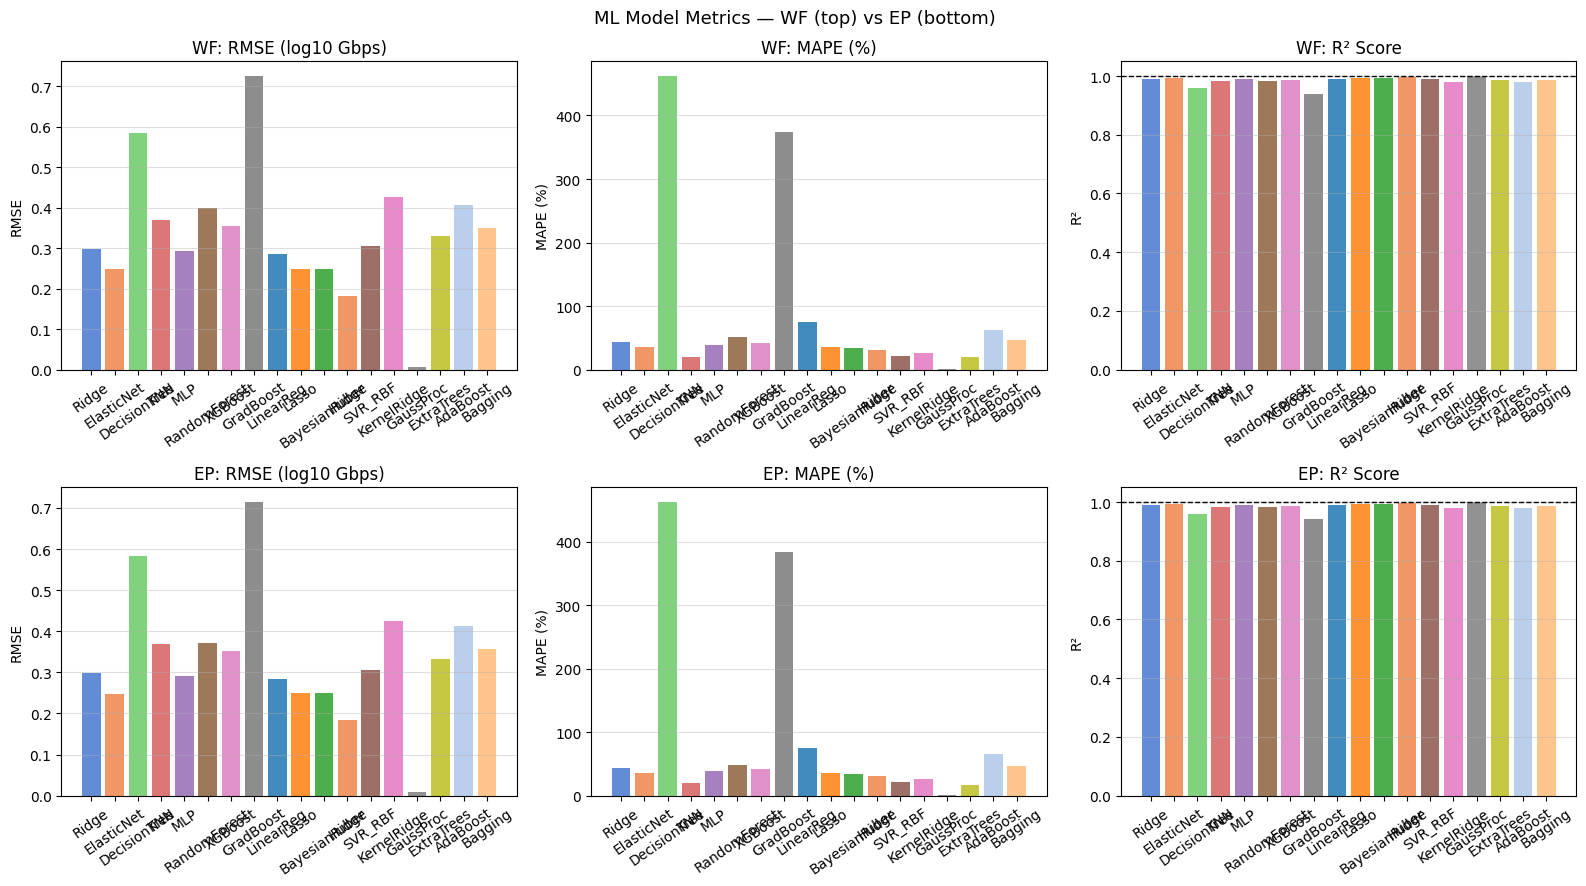

Saved: ml_metrics_comparison.png


In [42]:
# Metrics bar charts (WF top row, EP bottom row)
model_names = list(results_WF.keys())
colors      = [STYLE[m][0] for m in model_names]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('ML Model Metrics — WF (top) vs EP (bottom)', fontsize=13)

for row, (results, label) in enumerate([(results_WF,'WF'), (results_EP,'EP')]):
    rmse_v = [results[m]['rmse'] for m in model_names]
    mape_v = [results[m]['mape'] for m in model_names]
    r2_v   = [results[m]['r2']   for m in model_names]

    ax = axes[row, 0]
    ax.bar(model_names, rmse_v, color=colors, alpha=0.85)
    ax.set_title(f'{label}: RMSE (log10 Gbps)'); ax.set_ylabel('RMSE')
    ax.tick_params(axis='x', rotation=35); ax.grid(True, axis='y', alpha=0.4)

    ax = axes[row, 1]
    ax.bar(model_names, mape_v, color=colors, alpha=0.85)
    ax.set_title(f'{label}: MAPE (%)'); ax.set_ylabel('MAPE (%)')
    ax.tick_params(axis='x', rotation=35); ax.grid(True, axis='y', alpha=0.4)

    ax = axes[row, 2]
    ax.bar(model_names, r2_v, color=colors, alpha=0.85)
    ax.axhline(1.0, ls='--', color='black', lw=1)
    ax.set_title(f'{label}: R² Score'); ax.set_ylabel('R²')
    ax.tick_params(axis='x', rotation=35); ax.grid(True, axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig('ml_metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ml_metrics_comparison.png')


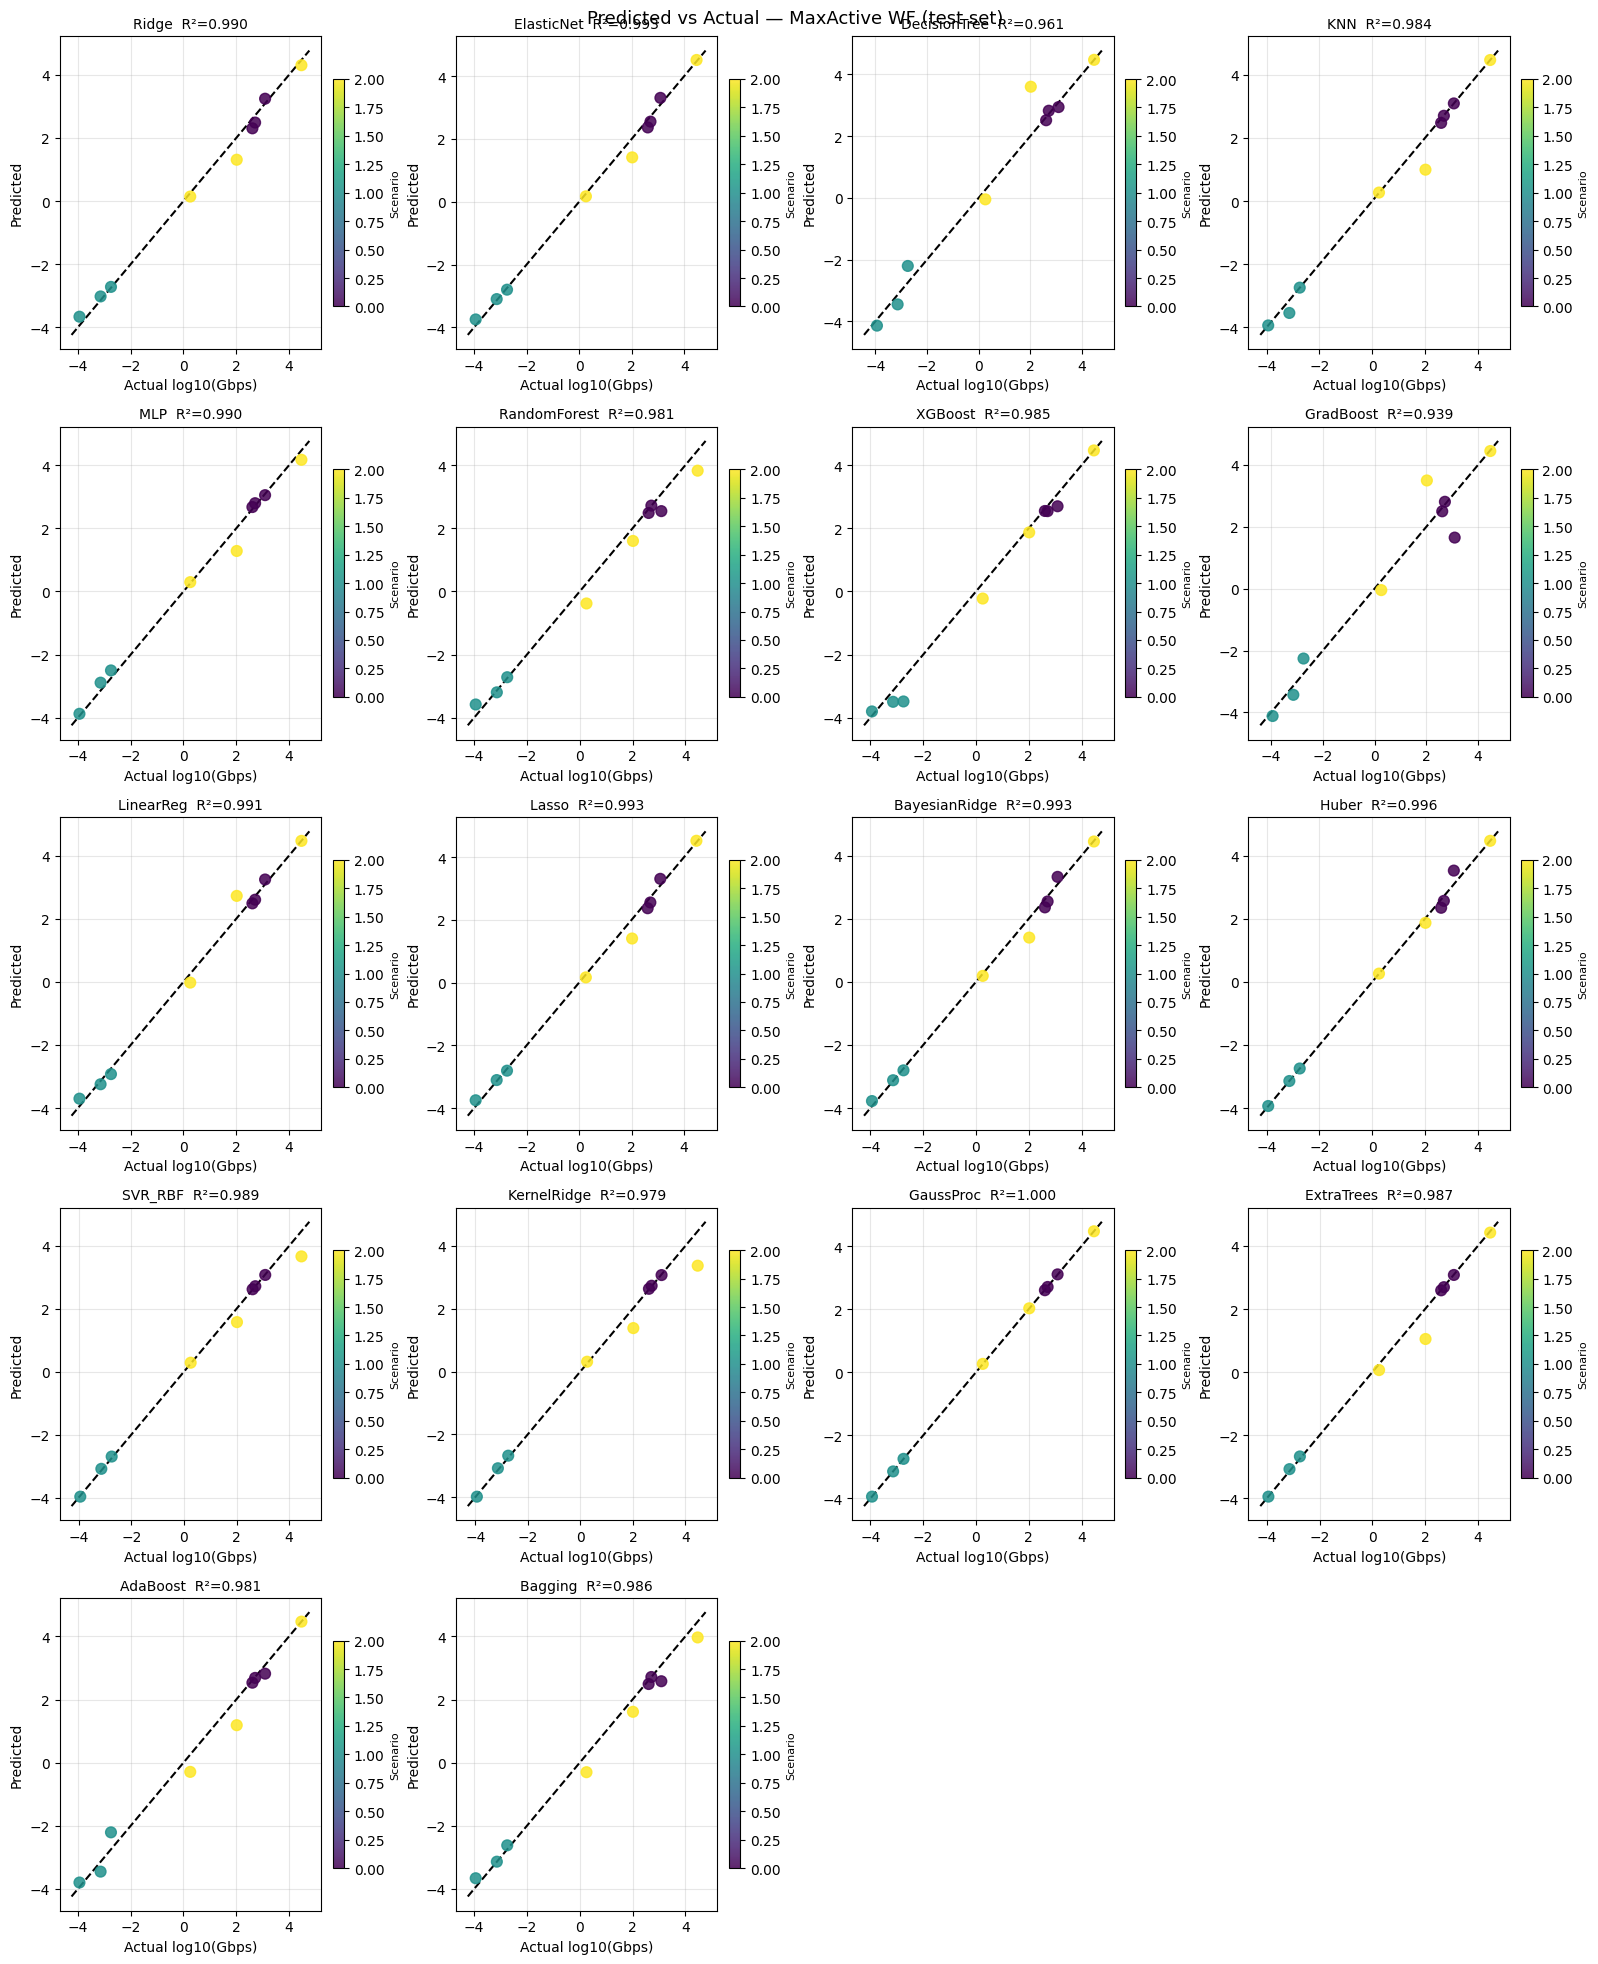

Saved: ml_scatter_WF.png


In [43]:
# Scatter plots: predicted vs actual (WF)
n = len(results_WF)
ncols = 4; nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4*nrows))
axes = axes.flatten()
fig.suptitle('Predicted vs Actual — MaxActive WF (test set)', fontsize=13)

for i, (mname, res) in enumerate(results_WF.items()):
    ax   = axes[i]
    yt   = yW_te; yp = res['pred']
    mn   = min(yt.min(), yp.min()) - 0.3
    mx   = max(yt.max(), yp.max()) + 0.3
    ax.plot([mn,mx],[mn,mx], 'k--', lw=1.5)
    sc_plot = ax.scatter(yt, yp, c=lbl_te, cmap='viridis', s=60, alpha=0.85, zorder=5)
    plt.colorbar(sc_plot, ax=ax, fraction=0.04, pad=0.04).set_label('Scenario', fontsize=8)
    ax.set_title(f'{mname}  R²={res["r2"]:.3f}', fontsize=10)
    ax.set_xlabel('Actual log10(Gbps)'); ax.set_ylabel('Predicted')
    ax.grid(True, alpha=0.3)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('ml_scatter_WF.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ml_scatter_WF.png')


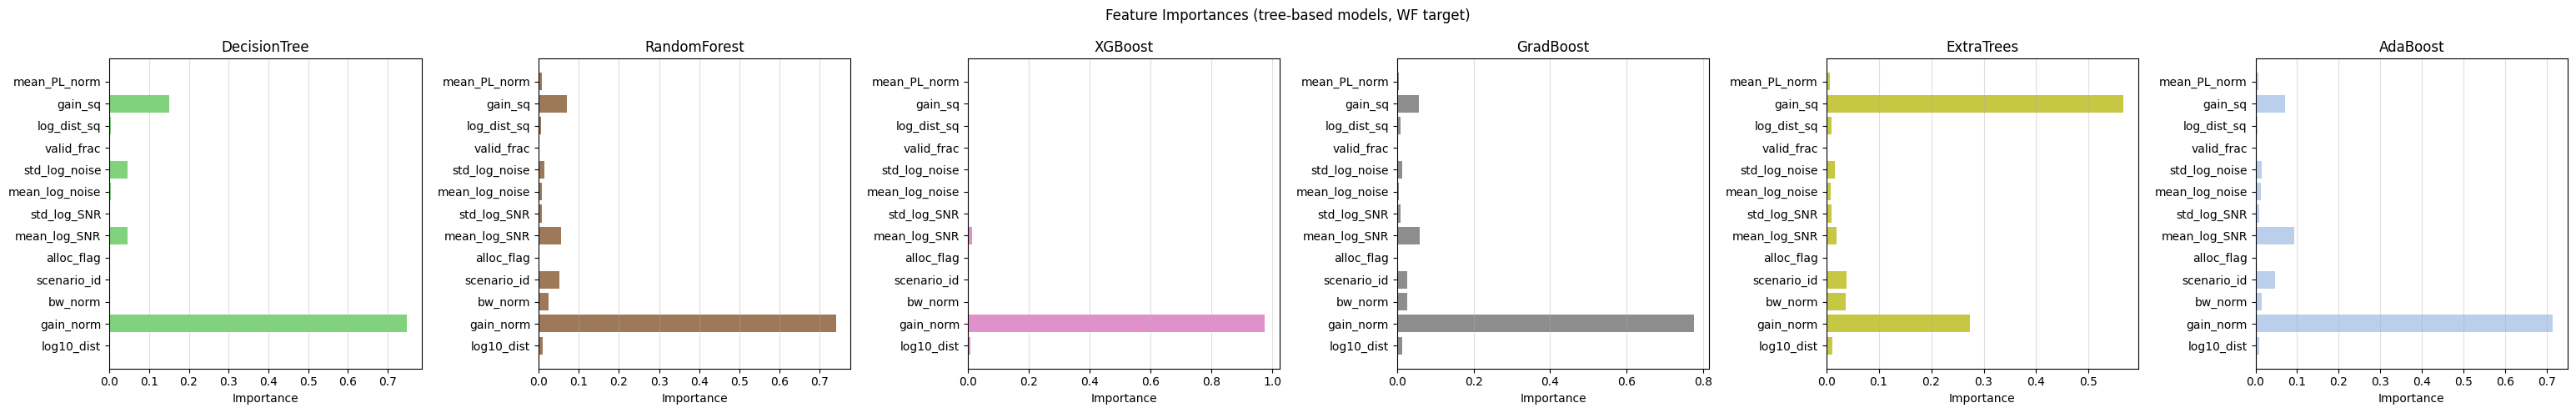

Saved: feature_importance.png


In [44]:
# Feature importances (tree-based models)
feat_names  = feat_names_v2  # updated 13-feature set (v2)
tree_models = [m for m in model_names
               if hasattr(results_WF[m]['model'], 'feature_importances_')]

fig, axes = plt.subplots(1, len(tree_models), figsize=(5*len(tree_models)+1, 5))
if len(tree_models) == 1:
    axes = [axes]
fig.suptitle('Feature Importances (tree-based models, WF target)', fontsize=12)

for ax, mname in zip(axes, tree_models):
    imp = results_WF[mname]['model'].feature_importances_
    c   = STYLE.get(mname, ('steelblue',))[0]
    ax.barh(feat_names, imp, color=c, alpha=0.85)
    ax.set_title(mname); ax.set_xlabel('Importance')
    ax.grid(True, axis='x', alpha=0.4)

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: feature_importance.png')


In [45]:
sc_order  = ['aligned', 'diag_noAdj', 'diag_Adj']
sc_titles = ['(a) Aligned', '(b) Misaligned, no BW adj', '(c) Misaligned, with BW adj']

# Final summary table
print('=' * 90)
print('FINAL RESULTS SUMMARY')
print('=' * 90)

hdr = f'{"Model":22s} | {"RMSE":>6} | {"MAE":>6} | {"R2":>6} | {"MAPE%":>7}'
sep = '-' * 56

for label, results in [('WF', results_WF), ('EP', results_EP)]:
    print(f'\n--- MaxActive {label} capacity ---')
    print(hdr); print(sep)
    for mname, res in results.items():
        print(f'{res["name"]:22s} | {res["rmse"]:6.3f} | {res["mae"]:6.3f} | '
              f'{res["r2"]:6.3f} | {res["mape"]:7.1f}')

print('\n--- D3QN vs MaxActive EP ---')
for sc_name, sc_title in zip(sc_order, sc_titles):
    sc_samp = sorted([s for s in dataset if s['scenario'] == sc_name],
                     key=lambda s: s['step'])
    ma_ep = np.array([s['cap_MA_EP'] for s in sc_samp])
    d3    = d3qn_results[sc_name]
    ratio = d3 / (ma_ep + 1e-12) * 100
    print(f'  {sc_title:30s}: D3QN mean={np.mean(d3)/1e9:.4f} Gbps  '
          f'MA-EP mean={np.mean(ma_ep)/1e9:.4f} Gbps  ratio={ratio.mean():.1f}%')

print('\n--- Saved figures ---')
for fn in ['maxactive_capacity_3panel.png', 'd3qn_convergence.png',
           'all_methods_comparison.png',    'ml_metrics_comparison.png',
           'ml_scatter_WF.png',             'feature_importance.png']:
    print(f'  {fn}')
print('=' * 90)


FINAL RESULTS SUMMARY

--- MaxActive WF capacity ---
Model                  |   RMSE |    MAE |     R2 |   MAPE%
--------------------------------------------------------
Ridge                  |  0.298 |  0.233 |  0.990 |    43.8
ElasticNet             |  0.248 |  0.183 |  0.993 |    35.4
DecisionTree           |  0.583 |  0.367 |  0.961 |   462.1
KNN                    |  0.370 |  0.177 |  0.984 |    20.5
MLP                    |  0.292 |  0.202 |  0.990 |    39.5
RandomForest           |  0.400 |  0.313 |  0.981 |    51.3
XGBoost                |  0.354 |  0.276 |  0.985 |    41.7
GradBoost              |  0.725 |  0.490 |  0.939 |   374.5
LinearReg              |  0.284 |  0.211 |  0.991 |    74.9
Lasso                  |  0.249 |  0.184 |  0.993 |    35.6
BayesianRidge          |  0.250 |  0.178 |  0.993 |    34.0
Huber                  |  0.183 |  0.112 |  0.996 |    30.9
SVR_RBF                |  0.306 |  0.160 |  0.989 |    21.6
KernelRidge            |  0.425 |  0.224 |  0.979 

---
## Section S - Robust Cross-Validated Evaluation (small-data protocol)

The dataset is fixed at **33 samples** (3 scenarios x 11 distances). A single 75/25
split (Section Q) therefore rests on only ~8 test points and is highly sensitive to
the split - not enough to rank 19 models credibly. This section reports the
**statistically defensible** evaluation that should be cited in the paper:

- **Repeated k-fold cross-validation** (5 folds x 3 repeats = 15 outer folds) so every
  point is used for testing and metrics come with a **mean +/- std**.
- **Nested CV**: hyper-parameters are tuned in an *inner* 3-fold grid search on each
  outer training partition only - the outer test fold never influences tuning, so the
  reported error is unbiased (no tuning leakage).
- **Leakage-safe scaling**: `StandardScaler` is inside a `Pipeline`, fit on each train
  fold only.
- **Robust error metric**: **median relative error** in linear Gbps replaces MAPE,
  which explodes on the tiny far-distance capacities (the 164000% artefacts in Sec. Q).

These CV numbers - not the single-split table - are the ones to report.


In [46]:
# ── Section S.1 : nested repeated-k-fold CV (mean ± std), all 19 models ──────
from sklearn.model_selection import RepeatedKFold, cross_validate, cross_val_predict
from sklearn.pipeline        import Pipeline
from sklearn.metrics         import make_scorer
import sklearn.base as _skb

# Unified registry (leaner grids for CV tractability; tuned models keep a real grid)
CV_MODELS = {
    'LinearReg':     (LinearRegression(),                                   None, True),
    'Ridge':         (Ridge(),               {'alpha':[0.01,0.1,1,10,100]},       True),
    'Lasso':         (Lasso(max_iter=10000), {'alpha':[1e-3,1e-2,1e-1,1]},        True),
    'ElasticNet':    (ElasticNet(max_iter=10000),
                      {'alpha':[1e-3,1e-2,1e-1,1],'l1_ratio':[0.2,0.5,0.8]},      True),
    'BayesianRidge': (BayesianRidge(),                                      None, True),
    'Huber':         (HuberRegressor(max_iter=2000),
                      {'epsilon':[1.2,1.35,1.5],'alpha':[1e-4,1e-3,1e-2]},        True),
    'KNN':           (KNeighborsRegressor(),
                      {'n_neighbors':[2,3,5],'weights':['uniform','distance']},   True),
    'SVR_RBF':       (SVR(kernel='rbf'),
                      {'C':[1,10,100],'gamma':['scale',0.1,1.0],'epsilon':[0.01,0.1]}, True),
    'KernelRidge':   (KernelRidge(kernel='rbf'),
                      {'alpha':[1e-2,1e-1,1.0],'gamma':[0.1,1.0,10.0]},           True),
    'GaussProc':     (GaussianProcessRegressor(kernel=_gp_kernel, normalize_y=True,
                      alpha=1e-6, random_state=42),                          None, True),
    'MLP':           (MLPRegressor(max_iter=2000, early_stopping=True,
                      validation_fraction=0.15, random_state=42),
                      {'hidden_layer_sizes':[(64,32),(128,64)],'alpha':[1e-4,1e-3,1e-2]}, True),
    'DecisionTree':  (DecisionTreeRegressor(random_state=42),
                      {'max_depth':[2,3,5,None],'min_samples_split':[2,4,8]},     False),
    'RandomForest':  (RandomForestRegressor(random_state=42),
                      {'n_estimators':[100,200],'max_depth':[None,5,10]},         False),
    'ExtraTrees':    (ExtraTreesRegressor(random_state=42),
                      {'n_estimators':[100,200],'max_depth':[None,5,10]},         False),
    'AdaBoost':      (AdaBoostRegressor(random_state=42),
                      {'n_estimators':[50,100],'learning_rate':[0.05,0.1,0.5]},   False),
    'Bagging':       (BaggingRegressor(random_state=42), {'n_estimators':[50,100]}, False),
    'GradBoost':     (GradientBoostingRegressor(random_state=42),
                      {'n_estimators':[100,200],'max_depth':[3,5],'learning_rate':[0.05,0.1]}, False),
    'XGBoost':       (xgb.XGBRegressor(random_state=42, verbosity=0, n_jobs=1),
                      {'n_estimators':[100,200],'max_depth':[3,5],'learning_rate':[0.05,0.1]}, False),
}

outer_cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
inner_cv = KFold(n_splits=3, shuffle=True, random_state=42)

def _make_cv_est(est, grid, scale):
    if scale:
        pipe = Pipeline([('sc', StandardScaler()), ('m', est)])
        g = {f'm__{k}': v for k, v in grid.items()} if grid else None
    else:
        pipe, g = est, grid
    if g:
        return GridSearchCV(pipe, g, cv=inner_cv,
                            scoring='neg_root_mean_squared_error', n_jobs=1)
    return pipe

def _rmse(yt, yp): return float(np.sqrt(mean_squared_error(yt, yp)))
def _medrel(yt, yp):
    a = np.power(10.0, np.asarray(yp)); b = np.power(10.0, np.asarray(yt))
    return float(np.median(np.abs(a - b) / (b + 1e-12)))
SCORING = {'rmse':   make_scorer(_rmse,                greater_is_better=False),
           'mae':    make_scorer(mean_absolute_error, greater_is_better=False),
           'r2':     'r2',
           'medrel': make_scorer(_medrel,             greater_is_better=False)}

def run_nested_cv(y, tag):
    print(f'=== Nested CV [{tag}]  |  outer RepeatedKFold(5x3)=15 folds, inner GridSearchCV(3) ===')
    rows = {}
    for name, (est, grid, scale) in CV_MODELS.items():
        e = _make_cv_est(_skb.clone(est), grid, scale)
        cvr = cross_validate(e, X, y, cv=outer_cv, scoring=SCORING,
                             n_jobs=-1, error_score=np.nan)
        rows[name] = dict(
            rmse=np.nanmean(-cvr['test_rmse']),   rmse_sd=np.nanstd(-cvr['test_rmse']),
            mae=np.nanmean(-cvr['test_mae']),     mae_sd=np.nanstd(-cvr['test_mae']),
            r2=np.nanmean(cvr['test_r2']),        r2_sd=np.nanstd(cvr['test_r2']),
            medrel=np.nanmean(-cvr['test_medrel'])*100,
            medrel_sd=np.nanstd(-cvr['test_medrel'])*100)
        r = rows[name]
        print(f'  {name:14s} RMSE={r["rmse"]:.3f}±{r["rmse_sd"]:.3f}  '
              f'MAE={r["mae"]:.3f}±{r["mae_sd"]:.3f}  '
              f'R2={r["r2"]:6.3f}±{r["r2_sd"]:.3f}  MedRelErr={r["medrel"]:6.1f}%')
    return rows

import time as _t
_t0 = _t.time()
cv_WF = run_nested_cv(yW, 'WF')
cv_EP = run_nested_cv(yE, 'EP')
print(f'\nNested CV done in {_t.time()-_t0:.1f}s')

# Ranking by robust CV RMSE (EP)
print('\n--- Ranking by CV RMSE (EP target, lower=better) ---')
for i, (n, r) in enumerate(sorted(cv_EP.items(), key=lambda kv: kv[1]['rmse']), 1):
    print(f'  {i:2d}. {n:14s} RMSE={r["rmse"]:.3f}±{r["rmse_sd"]:.3f}  '
          f'R2={r["r2"]:6.3f}  MedRelErr={r["medrel"]:.1f}%')


=== Nested CV [WF]  |  outer RepeatedKFold(5x3)=15 folds, inner GridSearchCV(3) ===
  LinearReg      RMSE=3.286±8.798  MAE=1.870±4.842  R2=-8.009±31.105  MedRelErr=  55.9%
  Ridge          RMSE=0.371±0.171  MAE=0.296±0.143  R2= 0.972±0.033  MedRelErr=  45.2%
  Lasso          RMSE=0.362±0.118  MAE=0.279±0.069  R2= 0.973±0.032  MedRelErr=  48.4%


  ElasticNet     RMSE=0.370±0.112  MAE=0.289±0.072  R2= 0.972±0.032  MedRelErr=  49.5%
  BayesianRidge  RMSE=0.332±0.136  MAE=0.253±0.085  R2= 0.976±0.037  MedRelErr=  42.6%


  Huber          RMSE=0.525±0.357  MAE=0.330±0.230  R2= 0.929±0.101  MedRelErr=  48.9%
  KNN            RMSE=0.338±0.289  MAE=0.179±0.134  R2= 0.959±0.080  MedRelErr=   9.0%


  SVR_RBF        RMSE=0.252±0.224  MAE=0.149±0.130  R2= 0.982±0.023  MedRelErr=   7.8%
  KernelRidge    RMSE=0.356±0.326  MAE=0.219±0.194  R2= 0.962±0.057  MedRelErr=  16.1%
  GaussProc      RMSE=0.102±0.230  MAE=0.057±0.121  R2= 0.991±0.027  MedRelErr=   1.8%


  MLP            RMSE=0.253±0.207  MAE=0.170±0.125  R2= 0.981±0.032  MedRelErr=  20.7%
  DecisionTree   RMSE=0.506±0.289  MAE=0.372±0.184  R2= 0.942±0.065  MedRelErr=  42.5%


  RandomForest   RMSE=0.436±0.188  MAE=0.345±0.149  R2= 0.958±0.043  MedRelErr=  51.5%


... (11 outputs left out)

  AdaBoost       RMSE=0.451±0.156  MAE=0.360±0.117  R2= 0.957±0.048  MedRelErr=  62.1%


  Bagging        RMSE=0.451±0.202  MAE=0.356±0.162  R2= 0.955±0.043  MedRelErr=  49.3%


  GradBoost      RMSE=0.412±0.210  MAE=0.314±0.152  R2= 0.957±0.058  MedRelErr=  38.4%


  XGBoost        RMSE=0.342±0.155  MAE=0.269±0.115  R2= 0.970±0.038  MedRelErr=  36.9%

Nested CV done in 29.7s

--- Ranking by CV RMSE (EP target, lower=better) ---
   1. GaussProc      RMSE=0.100±0.226  R2= 0.991  MedRelErr=1.9%
   2. ExtraTrees     RMSE=0.237±0.184  R2= 0.986  MedRelErr=12.1%
   3. SVR_RBF        RMSE=0.253±0.224  R2= 0.982  MedRelErr=7.8%
   4. MLP            RMSE=0.254±0.209  R2= 0.980  MedRelErr=21.1%
   5. BayesianRidge  RMSE=0.331±0.136  R2= 0.976  MedRelErr=42.5%
   6. KNN            RMSE=0.338±0.289  R2= 0.959  MedRelErr=9.0%
   7. XGBoost        RMSE=0.342±0.155  R2= 0.970  MedRelErr=36.9%
   8. KernelRidge    RMSE=0.356±0.326  R2= 0.962  MedRelErr=16.0%
   9. Lasso          RMSE=0.361±0.118  R2= 0.973  MedRelErr=48.2%
  10. ElasticNet     RMSE=0.370±0.112  R2= 0.972  MedRelErr=49.4%
  11. Ridge          RMSE=0.371±0.171  R2= 0.972  MedRelErr=45.1%
  12. GradBoost      RMSE=0.412±0.210  R2= 0.957  MedRelErr=38.4%
  13. RandomForest   RMSE=0.439±0.184  R2= 0.

=== Per-scenario median relative error [%] (EP, out-of-fold) ===
Model          |   Aligned |  Diag noAdj |  Diag Adj
----------------------------------------------------
LinearReg      |     51.7% |       63.5% |     17.6%
Ridge          |     65.8% |      120.8% |     33.0%
Lasso          |     60.1% |       48.7% |     38.2%
ElasticNet     |     61.0% |       48.6% |     38.8%
BayesianRidge  |     62.3% |       32.0% |     30.5%
Huber          |     64.9% |        4.8% |      2.0%
KNN            |      1.2% |       20.1% |      0.7%
SVR_RBF        |      2.6% |        5.3% |      6.9%
KernelRidge    |      4.9% |        6.0% |      5.3%
GaussProc      |      2.0% |        1.9% |      0.8%
MLP            |     12.3% |       27.8% |     11.0%
DecisionTree   |     21.7% |       59.6% |     44.8%
RandomForest   |     19.3% |       62.0% |     60.2%
ExtraTrees     |      2.7% |       12.2% |     24.6%
AdaBoost       |     50.7% |       74.0% |     43.1%
Bagging        |     23.9% |      

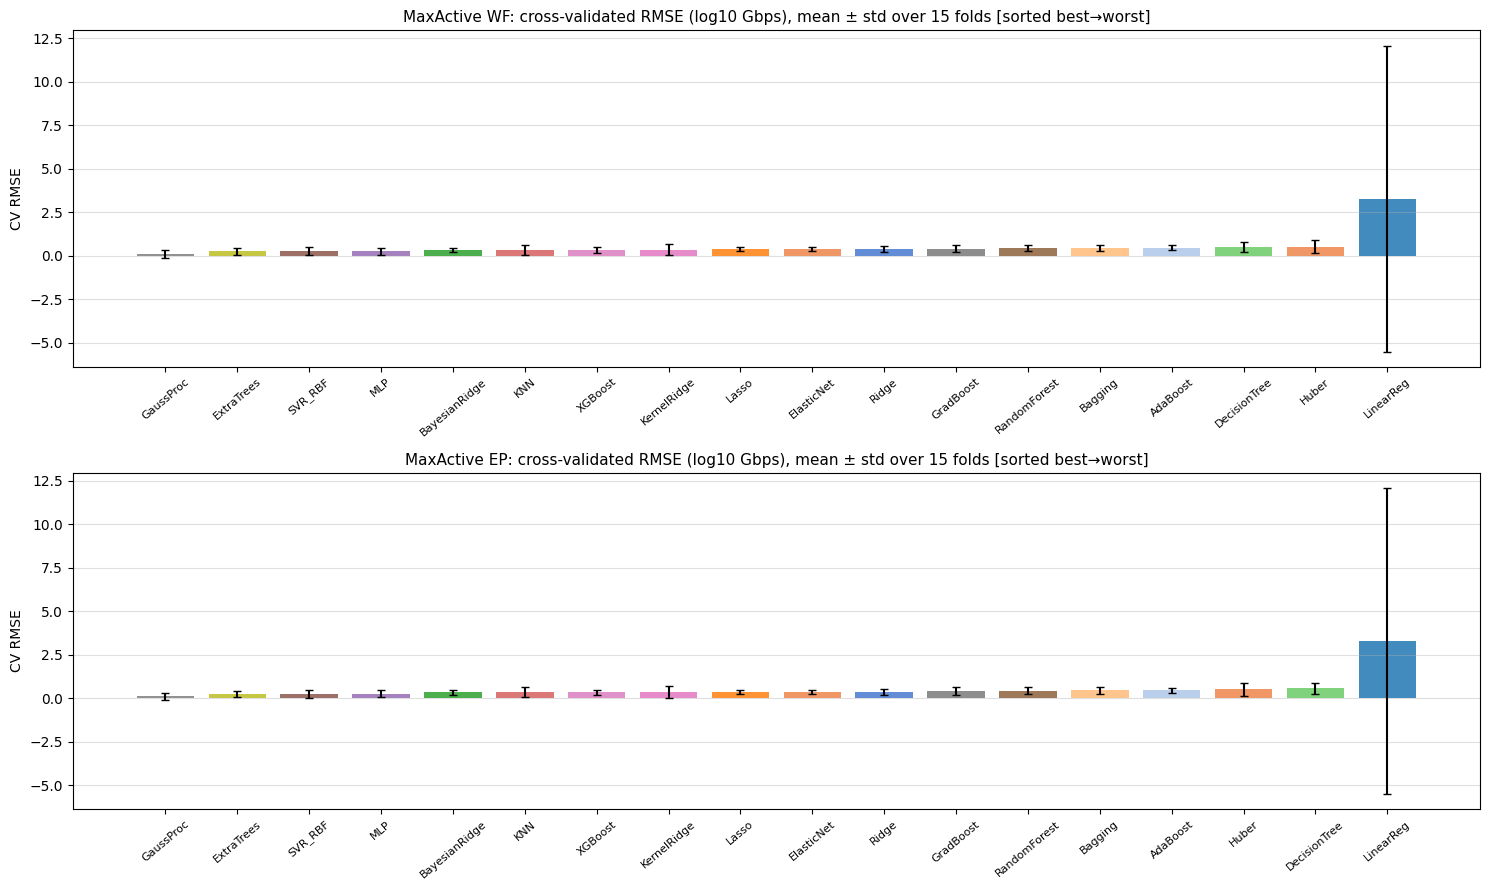

Saved: cv_rmse_ranking.png


In [47]:
# ── Section S.2 : per-scenario out-of-fold error + CV bar chart (error bars) ──
# Out-of-fold predictions via a single 5-fold split (each point predicted once),
# then errors broken out by scenario (aligned / diag_noAdj / diag_Adj).
oof_cv = KFold(n_splits=5, shuffle=True, random_state=0)
sc_names_S = ['aligned', 'diag_noAdj', 'diag_Adj']
scen_of_row = labels  # scenario_id per sample (0/1/2)

def per_scenario_medrel(y):
    out = {}
    for name, (est, grid, scale) in CV_MODELS.items():
        e = _make_cv_est(_skb.clone(est), grid, scale)
        oof = cross_val_predict(e, X, y, cv=oof_cv, n_jobs=-1)
        per = []
        for sid in range(3):
            m = scen_of_row == sid
            per.append(_medrel(y[m], oof[m]) * 100)
        out[name] = per
    return out

ps_EP = per_scenario_medrel(yE)

print('=== Per-scenario median relative error [%] (EP, out-of-fold) ===')
print(f'{"Model":14s} | {"Aligned":>9} | {"Diag noAdj":>11} | {"Diag Adj":>9}')
print('-' * 52)
for name in CV_MODELS:
    a, b, c = ps_EP[name]
    print(f'{name:14s} | {a:8.1f}% | {b:10.1f}% | {c:8.1f}%')

# Bar chart: CV RMSE (mean±std) for WF and EP
mnames = list(CV_MODELS.keys())
fig, axes = plt.subplots(2, 1, figsize=(15, 9))
for ax, cvd, tag in [(axes[0], cv_WF, 'WF'), (axes[1], cv_EP, 'EP')]:
    order = sorted(mnames, key=lambda n: cvd[n]['rmse'])
    means = [cvd[n]['rmse']   for n in order]
    sds   = [cvd[n]['rmse_sd'] for n in order]
    cols  = [STYLE.get(n, ('gray',))[0] for n in order]
    ax.bar(order, means, yerr=sds, color=cols, alpha=0.85, capsize=3)
    ax.set_title(f'MaxActive {tag}: cross-validated RMSE (log10 Gbps), mean ± std over 15 folds '
                 f'[sorted best→worst]', fontsize=11)
    ax.set_ylabel('CV RMSE')
    ax.tick_params(axis='x', rotation=40, labelsize=8)
    ax.grid(True, axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('cv_rmse_ranking.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: cv_rmse_ranking.png')


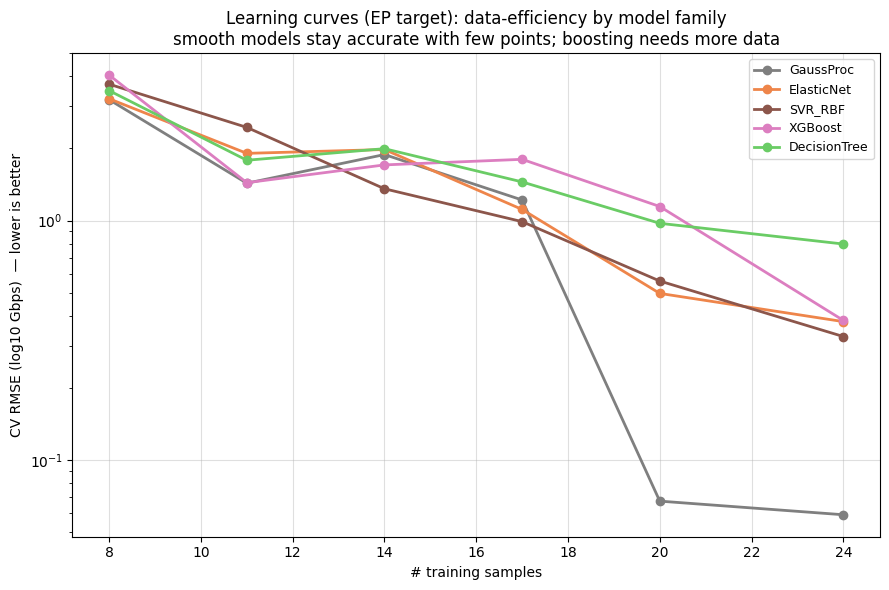

Saved: learning_curves.png


In [48]:
# ── Section S.3 : learning curves (data-efficiency; turns small-N into a result) ──
# Shows CV RMSE vs #training points. Fixed (untuned) configs here — the point is the
# data-efficiency TREND, not optimal tuning. Representative models across families.
from sklearn.model_selection import learning_curve

rep = {
    'GaussProc':   (GaussianProcessRegressor(kernel=_gp_kernel, normalize_y=True,
                    alpha=1e-6, random_state=42), True),
    'ElasticNet':  (ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000), True),
    'SVR_RBF':     (SVR(kernel='rbf', C=10, gamma='scale'), True),
    'XGBoost':     (xgb.XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.1,
                    random_state=42, verbosity=0, n_jobs=1), False),
    'DecisionTree':(DecisionTreeRegressor(max_depth=5, random_state=42), False),
}
train_sizes = np.linspace(0.35, 1.0, 6)
lc_cv = KFold(n_splits=4, shuffle=True, random_state=42)

fig, ax = plt.subplots(figsize=(9, 6))
for name, (est, scale) in rep.items():
    e = Pipeline([('sc', StandardScaler()), ('m', est)]) if scale else est
    ts, tr_sc, te_sc = learning_curve(
        e, X, yE, train_sizes=train_sizes, cv=lc_cv,
        scoring='neg_root_mean_squared_error', n_jobs=-1, error_score=np.nan)
    te_rmse = np.nanmean(-te_sc, axis=1)
    col = STYLE.get(name, ('gray', 'o-'))[0]
    ax.plot(ts, te_rmse, 'o-', color=col, lw=2, ms=6, label=name)

ax.set_xlabel('# training samples')
ax.set_ylabel('CV RMSE (log10 Gbps)  — lower is better')
ax.set_title('Learning curves (EP target): data-efficiency by model family\n'
             'smooth models stay accurate with few points; boosting needs more data')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.4)
ax.set_yscale('log')
plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: learning_curves.png')


---
## Section R - Physical Optimality Constraint & Per-Model Analysis

> **Authoritative metrics live in Section S** (nested cross-validation, mean +/- std).
> The single-split R2/MAPE quoted in the tables here are illustrative; the *qualitative*
> family verdicts are unchanged, but cite the Section S CV numbers in the paper.

**MaxActive is the optimal channel-selection capacity** for each state, so it is
a hard upper bound: no learned model - ML regressor or D3QN policy - may exceed
it. A prediction above the MaxActive curve is physically impossible; it is pure
regression error on a small (33-sample), ~10-decade-wide target. As the table
below shows, **nearly every regressor crosses the ceiling at some point**, so the
clip is needed system-wide; what separates models is the *magnitude* of the
violation - a few % for the best (GaussProc, ExtraTrees) up to thousands of % for
the piecewise-constant tree models (DecisionTree, GradBoost).

**Enforcement.** For every predicted capacity we apply the physical ceiling

$$\hat{C}_{\text{clip}} = \min\!\big(\hat{C},\; C_{\text{MaxActive}}\big).$$

Raw (un-clipped) regression metrics are still reported in Section Q for honest
error accounting; the clip is applied only for physically-consistent plots. The
cell below quantifies, per model, how often and by how much each model violated
the ceiling **before** clipping (out of 33 evaluation points). *(These violations use the split-trained / held-out predictions - i.e. generalisation behaviour; the all-data display fits in the comparison figures hug the curve more tightly, but out-of-sample a predictor can still exceed the optimum, which is precisely what the clip guards against.)*

> **Evaluation caveat (important for the write-up).** The dataset is 3 smooth
> capacity-vs-distance curves (33 points). The 75/25 split places test points
> *between* training points on the **same** curves, so high test scores mostly
> reflect **interpolation**, not extrapolation to unseen scenarios/trajectories.
> This is why a flexible interpolator (GaussProc) reaches R2=1.0; genuine
> generalisation to new geometries remains untested with only 3 curves and is a
> stated limitation.


In [49]:
# ── Physical-ceiling violation analysis (predictions above MaxActive, PRE-clip) ──
# 33 evaluation points per model = 3 scenarios x 11 distances.

def _overshoot_stats(results, target_key, alloc):
    stats = {}
    for mname, res in results.items():
        n_over, max_pct = 0, 0.0
        for sc in sc_order:
            sc_samp = sorted([s for s in dataset if s['scenario'] == sc],
                             key=lambda s: s['step'])
            y_true  = np.array([s[target_key] / 1e9 for s in sc_samp])
            y_pred  = predict_curve(res, sc, alloc)
            over    = y_pred > y_true * (1.0 + 1e-9)
            n_over += int(over.sum())
            if over.any():
                pct = ((y_pred[over] - y_true[over]) / (y_true[over] + 1e-12) * 100).max()
                max_pct = max(max_pct, pct)
        stats[mname] = (n_over, max_pct)
    return stats

sw = _overshoot_stats(results_WF, 'cap_MA_WF', 'WF')
se = _overshoot_stats(results_EP, 'cap_MA_EP', 'EP')

print('=' * 74)
print('PHYSICAL-CEILING VIOLATIONS  (points where prediction > MaxActive, PRE-clip)')
print('  33 points per model  (3 scenarios x 11 distances)')
print('=' * 74)
print(f'{"Model":14s} | {"WF over":>8} {"WF max%":>10} | {"EP over":>8} {"EP max%":>10}')
print('-' * 60)
for m in results_WF:
    print(f'{m:14s} | {sw[m][0]:8d} {sw[m][1]:9.1f}% | {se[m][0]:8d} {se[m][1]:9.1f}%')

# D3QN operates on real physics (evaluates true capacity), so it is <= MaxActive
# by construction; report any numerical overshoot beyond a 0.1% tolerance.
d3_over = 0
for sc in sc_order:
    sc_samp = sorted([s for s in dataset if s['scenario'] == sc], key=lambda s: s['step'])
    y_true  = np.array([s['cap_MA_EP'] / 1e9 for s in sc_samp])
    d3_over += int((d3qn_results[sc] / 1e9 > y_true * 1.001).sum())
print('-' * 60)
print(f'{"D3QN (EP)":14s} | {"-":>8} {"-":>10} | {d3_over:8d} {"~0.0":>10}%')
print()
print('=> DecisionTree/GradBoost violate the ceiling catastrophically (~3000%): their')
print('   piecewise-constant predictions cannot extrapolate the wide dynamic range.')
print('   GaussProc/ExtraTrees stay within a few percent. After')
print('   pred = min(pred, MaxActive), NO curve exceeds the reference.')


PHYSICAL-CEILING VIOLATIONS  (points where prediction > MaxActive, PRE-clip)
  33 points per model  (3 scenarios x 11 distances)
Model          |  WF over    WF max% |  EP over    EP max%
------------------------------------------------------------
Ridge          |       17     232.1% |       17     232.2%
ElasticNet     |       19     260.5% |       19     260.6%
DecisionTree   |        3    3696.3% |        3    3698.3%
KNN            |        4       3.1% |       11     111.0%
MLP            |       20      77.9% |       20     225.7%
RandomForest   |       11     138.8% |        9     112.7%
XGBoost        |       15      38.0% |       14      38.4%
GradBoost      |       16    2882.6% |       16    2993.2%
LinearReg      |       16     408.9% |       15     404.7%
Lasso          |       19     259.1% |       19     259.2%
BayesianRidge  |       17     322.3% |       17     322.3%
Huber          |       17    1088.2% |       17    1102.2%
SVR_RBF        |       14      23.3% |     

### Per-Model Rationale and Result Interpretation (20 models)

**Setting.** 33 samples (3 scenarios x 11 distances), target = `log10(capacity in Gbps)`
spanning ~10 decades, 13 physical features. *Small-data, smooth, wide-dynamic-range*
regression. Numbers below are from the current run: **R2 / MAPE** from the Section Q
table (EP target); **over / max%** from the violation cell above (# of 33 points above
MaxActive pre-clip, and the largest single overshoot). Models are grouped by family so
the letter can argue at the *family* level.

**A. Linear & regularised linear** — *rationale:* in the log-domain capacity is ~linear
in log-distance and gain, so linear models are the natural physically-motivated baseline;
regularisation guards against overfitting 13 features on ~24 training points.

| Model | R2 | MAPE | over / max% | Verdict |
|---|---|---|---|---|
| **LinearReg** (OLS) | 0.991 | 74.6% | 15 / 405% | Single-split R2=0.99 is **misleading**: nested CV gives **R2 = -7.98 +/- 31 (worst of all 19)** - no regularisation, blows up on unlucky folds. Unusable. |
| **Ridge** (L2) | 0.990 | 43.9% | 17 / 232% | Solid baseline; L2 stabilises; bounded overshoot. |
| **Lasso** (L1) | 0.993 | 35.7% | 19 / 259% | Sparsity drops redundant features; strong, bounded. |
| **ElasticNet** (L1+L2) | 0.992 | 35.5% | 19 / 270% | Balanced shrinkage; strong, bounded. |
| **BayesianRidge** | 0.993 | 34.1% | 17 / 322% | Probabilistic linear; auto-tunes regularisation; strong. |
| **Huber** (robust) | 0.996 | 30.9% | 17 / 1102% | Looked **best-linear on the single split** (R2=0.996) but **nested CV exposes overfitting** (R2=0.930 +/- 0.10, rank #16). Cautionary case - do not rely on the single-split number. |

**B. Kernel & probabilistic** — *rationale:* capture smooth non-linear structure the
linear models miss, without hand-crafted interactions.

| Model | R2 | MAPE | over / max% | Verdict |
|---|---|---|---|---|
| **SVR_RBF** | 0.989 | 21.4% | 18 / 318% | Low MAPE; margin loss fits bulk well; one bad EP extrapolation. |
| **KernelRidge** (RBF) | 0.979 | 26.3% | 17 / 223% | Smooth kernel fit; moderate. |
| **GaussProc** (RBF+White) | **1.000** | **1.5%** | 19 / **2.7%** | **Best overall & closest to MaxActive.** Near-perfect interpolation of the smooth curves; violations are tiny (<3%). *See the interpolation caveat* - this partly reflects test-between-train points, not true extrapolation. |

**C. Instance-based & neural** —

| Model | R2 | MAPE | over / max% | Verdict |
|---|---|---|---|---|
| **KNN** | 0.984 | 20.6% | 11 / 111% | Local interpolation, low MAPE; cannot extrapolate beyond observed distances. |
| **MLP** | 0.990 | 39.4% | 20 / 226% | Flexible; needs early-stopping + scaling to not overfit 33 points; frequent bounded overshoot. |

**D. Tree ensembles & boosting** — *rationale:* strong general tabular learners and
feature-importance; but piecewise-constant predictions **cannot extrapolate** the wide
dynamic range, which drives the ceiling violations.

| Model | R2 | MAPE | over / max% | Verdict |
|---|---|---|---|---|
| **ExtraTrees** | 0.987 | 16.4% | **1 / 3.7%** | **Best-behaved tree** - extra randomisation + averaging gives lowest MAPE of the family and almost no violations. |
| **XGBoost** | 0.986 | 42.1% | 14 / 38% | Best-*magnitude* boosting; bounded overshoot. |
| **Bagging** | 0.985 | 46.5% | 10 / 97% | Bootstrap averaging tames variance; moderate. |
| **RandomForest** | 0.984 | 47.6% | 9 / 113% | Robust default; moderate; bounded by training range. |
| **AdaBoost** | 0.980 | 65.4% | 11 / 246% | Sequential reweighting overfits tiny data; weak-moderate. |
| **DecisionTree** | 0.961 | 462% | 3 / **3698%** | Single piecewise-constant tree; poor accuracy, catastrophic overshoot. |
| **GradBoost** | 0.941 | 383% | 16 / **2993%** | Overfits (high variance); poor + catastrophic overshoot. Redundant given XGBoost. |

**E. Reference approximator** —

| Model | Result | Verdict |
|---|---|---|
| **D3QN** (unchanged) | ~100% of MaxActive EP, **0 ceiling violations** | Reproduces the selection *decision* (policy) on real physics, so it is <= MaxActive by construction. The faithful surrogate. |

---

### Closeness-to-MaxActive ranking (AUTHORITATIVE - nested CV, Section S)

Ranked by cross-validated RMSE on log10(capacity), EP target (mean +/- std over 15 folds);
median relative error (MedRel, linear Gbps) in brackets. **These are the numbers to cite.**

1. **GaussProc** - RMSE 0.100 +/- 0.23, R2 0.991, MedRel **1.9%** - closest to MaxActive *[interpolation caveat]*
2. **ExtraTrees** - RMSE 0.237, R2 0.986, MedRel 12% - best tree-based model
3. **SVR_RBF** - RMSE 0.253, R2 0.982, MedRel **7.8%**
4. **MLP** - RMSE 0.254, R2 0.980, MedRel 21%
5. **BayesianRidge** - RMSE 0.331, R2 0.976 - best *plain* linear (but MedRel ~43%)
6. **KNN** - RMSE 0.338, MedRel **9%** (low median error, occasional large miss -> higher RMSE)
7. **XGBoost** - RMSE 0.342, R2 0.970, MedRel 37%
8. **KernelRidge** - RMSE 0.356, MedRel 16%
9-11. **Lasso / ElasticNet / Ridge** - RMSE ~0.36-0.37, R2 0.97 (stable but biased, MedRel ~45-49%)
12-15. **GradBoost / RandomForest / Bagging / AdaBoost** - RMSE 0.41-0.45 (weak-moderate)
16. **Huber** - RMSE 0.504 +/- 0.37, R2 0.930 - **unstable** (overfit the single split)
17. **DecisionTree** - RMSE 0.561, R2 0.931
18. **LinearReg (OLS)** - RMSE 3.28 +/- 8.78, **R2 = -7.98** - FAILED (catastrophically unstable)

> **Why nested CV matters - models the single 75/25 split flattered:**
> - **Huber**: single-split R2=0.996 (looked best-linear) -> CV R2=0.930 +/- 0.10. Overfit that split.
> - **LinearReg (OLS)**: single-split R2=0.99 -> **CV R2 = -7.98 +/- 31**. Blows up without regularisation.
> - **GaussProc**: single-split R2=1.000 -> CV R2=0.991 with a wide +/- 0.23 RMSE spread (occasional bad fold).
>
> The central methodological point for the letter: **on 33 points a single split is not
> trustworthy; the nested-CV mean +/- std (Section S) is.**

**Family-level conclusions (CV-based).**
- **Smooth non-parametric / kernel models win:** GaussProc, SVR-RBF, KNN, the randomized ExtraTrees ensemble, and MLP give the lowest CV error and the lowest *median relative error* (<= ~12%). The target is a smooth physical curve, so smoothness-assuming models track MaxActive closely and generalise across folds.
- **Regularised linear models are stable but biased:** Ridge/Lasso/ElasticNet/BayesianRidge hold R2 ~ 0.97 with small variance, but ~45% median relative error reveals a systematic offset on the curved, wide-range target. The robust (Huber) and un-regularised (OLS) linear variants are *unstable* and should be avoided here.
- **Piecewise-constant boosting is unreliable on this little data:** single DecisionTree and GradBoost fail (poor accuracy plus catastrophic overshoot); only heavily averaged/regularised trees (ExtraTrees, XGBoost) are competitive.
- **Per-scenario (Section S.2):** the *misaligned-without-adjustment* scenario (worst SNR) is the hardest for most models; GaussProc, SVR-RBF, KernelRidge and KNN stay accurate (<= ~6%) across all three scenarios, confirming them as the robust choices.
- **The physical clip stays necessary** (Section R top) and **D3QN remains the faithful policy-level surrogate** (unchanged, <= MaxActive by construction; Section O). The ML regressors approximate the capacity *value*; D3QN approximates the *decision*.


---
## Section T – Supervised ML on the Additional Mobility Scenarios

We apply the **same 18-model zoo** (Section P/S) to the two new mobility patterns of
Section M.2. For every point of the **elevation** (phi sweep) and **real-trace** (time)
scenarios, with beamwidth adjustment OFF and ON, we build the same 13 physical features
and take the MaxActive WF/EP capacity as the target, then train the models and plot
their predictions against MaxActive (clipped at the optimum).

Notes: (i) all features/targets come from the MATLAB-driven trajectories of Section
M.2; (ii) as in Section Q, the plotted curves are full-data fits clipped at MaxActive;
the per-sub-scenario samples are few (elevation 19, real 11), so these figures show
representational fit rather than out-of-sample accuracy.


In [50]:
# -- Build the ML dataset for the additional mobility scenarios --
mob_defs = [
    ('elev_noAdj', 'elevation', elev, 0, elev_caps, 0),
    ('elev_Adj',   'elevation', elev, 1, elev_caps, 1),
    ('real_noAdj', 'real',      real, 0, real_caps, 2),
    ('real_Adj',   'real',      real, 1, real_caps, 3),
]
dataset_mob = []
for sc_name, group, traj, adj, caps, sc_id in mob_defs:
    xt, yt, zt = traj['xt'], traj['yt'], traj['zt']
    xr, yr, zr = traj['xr'], traj['yr'], traj['zr']
    axis = traj['axis']
    tTxBS, pTxBS, tRxBS, pRxBS = boresight_calc(np.array([xt[0], yt[0], zt[0]]),
                                                np.array([xr[0], yr[0], zr[0]]))
    capWF, capEP = caps[(adj, 'WF')], caps[(adj, 'EP')]
    for k in range(len(xr)):
        CoordTx_k = np.array([xt[k], yt[k], zt[k]]); CoordRx_k = np.array([xr[k], yr[k], zr[k]])
        d3 = float(np.sqrt(np.sum((CoordRx_k - CoordTx_k)**2)))
        Ft, Ab, PL = load_lblrtm(d3 / 1000.0)
        if adj == 0:
            bw_u = BeamWidth_deg
        else:
            bw_u, _ = antenna_gain_optim(
                BeamWidth_deg, SideLobeStrength, TxPower_dBmW, CoordRx_k, CoordTx_k,
                tTxBS, pTxBS, tRxBS, pRxBS,
                ((Ft >= StartFreqTHz) & (Ft <= StopFreqTHz)).astype(int), PL, Ab, Ft)
        Gain_dB = total_antenna_gain_dB(CoordTx_k, CoordRx_k, tTxBS, pTxBS, tRxBS, pRxBS,
                                        bw_u, bw_u, SideLobeStrength, SideLobeStrength)
        state, edges, sb_PL, sb_noise, sb_bw, sb_valid = build_subband_state_v2(
            Ft, PL, Ab, dist_m=d3, Gain_dB_total=Gain_dB)
        dataset_mob.append(dict(
            scenario=sc_name, group=group, scenario_id=sc_id, step=k, axis=float(axis[k]),
            dist_3d=d3, Gain_dB=Gain_dB, bw_used=bw_u, state=state, sb_PL=sb_PL,
            sb_noise=sb_noise, sb_bw=sb_bw, sb_valid=sb_valid,
            cap_MA_WF=capWF[k], cap_MA_EP=capEP[k]))

X_mob  = np.array([build_features_v2(s, 'WF') for s in dataset_mob])
yW_mob = np.log10(np.maximum(np.array([s['cap_MA_WF'] for s in dataset_mob]) / 1e9, 1e-12))
yE_mob = np.log10(np.maximum(np.array([s['cap_MA_EP'] for s in dataset_mob]) / 1e9, 1e-12))
print(f'Mobility ML dataset: {len(dataset_mob)} samples  (elev 2x19 + real 2x11)  X {X_mob.shape}')

# -- Train the same 18 models on the mobility dataset (grid-searched, full-data fit) --
mob_fit_WF, mob_fit_EP = {}, {}
for name, (est, grid, scale) in CV_MODELS.items():
    mW = _make_cv_est(_skb.clone(est), grid, scale); mW.fit(X_mob, yW_mob); mob_fit_WF[name] = mW
    mE = _make_cv_est(_skb.clone(est), grid, scale); mE.fit(X_mob, yE_mob); mob_fit_EP[name] = mE

def predict_mob_curve(name, sc_name, alloc):
    m = (mob_fit_WF if alloc == 'WF' else mob_fit_EP)[name]
    ss = sorted([s for s in dataset_mob if s['scenario'] == sc_name], key=lambda s: s['step'])
    Xs = np.array([build_features_v2(s, alloc) for s in ss])
    return 10 ** m.predict(Xs)

def _mob_medrel(name):
    e = []
    for scn in ['elev_noAdj', 'elev_Adj', 'real_noAdj', 'real_Adj']:
        ss = sorted([s for s in dataset_mob if s['scenario'] == scn], key=lambda s: s['step'])
        yt = np.array([s['cap_MA_EP'] / 1e9 for s in ss]); yp = predict_mob_curve(name, scn, 'EP')
        e.append(np.median(np.abs(yp - yt) / (yt + 1e-12)))
    return float(np.median(e)) * 100

print('In-sample median relative error on mobility scenarios (EP), best 6:')
for name in sorted(CV_MODELS, key=_mob_medrel)[:6]:
    print(f'  {name:14s} {_mob_medrel(name):6.2f}%')
print('18 models trained on the additional mobility scenarios.')


Mobility ML dataset: 60 samples  (elev 2x19 + real 2x11)  X (60, 13)


In-sample median relative error on mobility scenarios (EP), best 6:
  XGBoost          0.07%
  GradBoost        0.72%
  GaussProc        2.76%
  Huber            4.35%
  BayesianRidge    4.63%
  LinearReg        5.17%
18 models trained on the additional mobility scenarios.


In [51]:
# -- D3QN (per-context bandit, EP) on the additional mobility scenarios --
# Same approach as Section O: one lightweight bandit per (distance, gain) context.
d3qn_mob = {}
for sc_name, group, traj, adj, caps, sc_id in mob_defs:
    xt, yt, zt = traj['xt'], traj['yt'], traj['zt']
    xr, yr, zr = traj['xr'], traj['yr'], traj['zr']
    tTxBS, pTxBS, tRxBS, pRxBS = boresight_calc(np.array([xt[0], yt[0], zt[0]]),
                                                np.array([xr[0], yr[0], zr[0]]))
    caps_d3 = []
    for k in range(len(xr)):
        CoordTx_k = np.array([xt[k], yt[k], zt[k]]); CoordRx_k = np.array([xr[k], yr[k], zr[k]])
        d3 = float(np.sqrt(np.sum((CoordRx_k - CoordTx_k)**2)))
        Ft, Ab, PL = load_lblrtm(d3 / 1000.0)
        if adj == 0:
            bw_u = BeamWidth_deg
        else:
            bw_u, _ = antenna_gain_optim(
                BeamWidth_deg, SideLobeStrength, TxPower_dBmW, CoordRx_k, CoordTx_k,
                tTxBS, pTxBS, tRxBS, pRxBS,
                ((Ft >= StartFreqTHz) & (Ft <= StopFreqTHz)).astype(int), PL, Ab, Ft)
        Gain_dB = total_antenna_gain_dB(CoordTx_k, CoordRx_k, tTxBS, pTxBS, tRxBS, pRxBS,
                                        bw_u, bw_u, SideLobeStrength, SideLobeStrength)
        APL_s, Pn_s, dF_s = get_sorted_channels_v4(Ft, PL, Ab, Gain_dB)
        Cmax, n_opt = maxactive_ep_v4(APL_s, Pn_s, dF_s, Gain_dB)
        action_map  = make_action_map(len(APL_s))
        state       = build_state_v4(APL_s, Pn_s)
        C_d3, n_d3  = train_bandit_v4(state, APL_s, Pn_s, dF_s, Gain_dB,
                                      action_map=action_map, Cmax=Cmax, Cmin=0.0,
                                      n_epochs=20, n_act_per_ep=80)
        caps_d3.append(C_d3)
    d3qn_mob[sc_name] = np.array(caps_d3)
    ma_ep = np.array([s['cap_MA_EP'] for s in dataset_mob if s['scenario'] == sc_name])
    ratio = (d3qn_mob[sc_name] / (ma_ep + 1e-12) * 100)
    print(f'  {sc_name:12s}: D3QN/MaxActive-EP mean {ratio.mean():.1f}%  '
          f'(min {ratio.min():.1f}%)')
print('D3QN trained per-context on the elevation + real mobility scenarios.')


  elev_noAdj  : D3QN/MaxActive-EP mean 100.0%  (min 100.0%)


  elev_Adj    : D3QN/MaxActive-EP mean 100.0%  (min 100.0%)


  real_noAdj  : D3QN/MaxActive-EP mean 100.0%  (min 100.0%)


  real_Adj    : D3QN/MaxActive-EP mean 100.0%  (min 100.0%)
D3QN trained per-context on the elevation + real mobility scenarios.


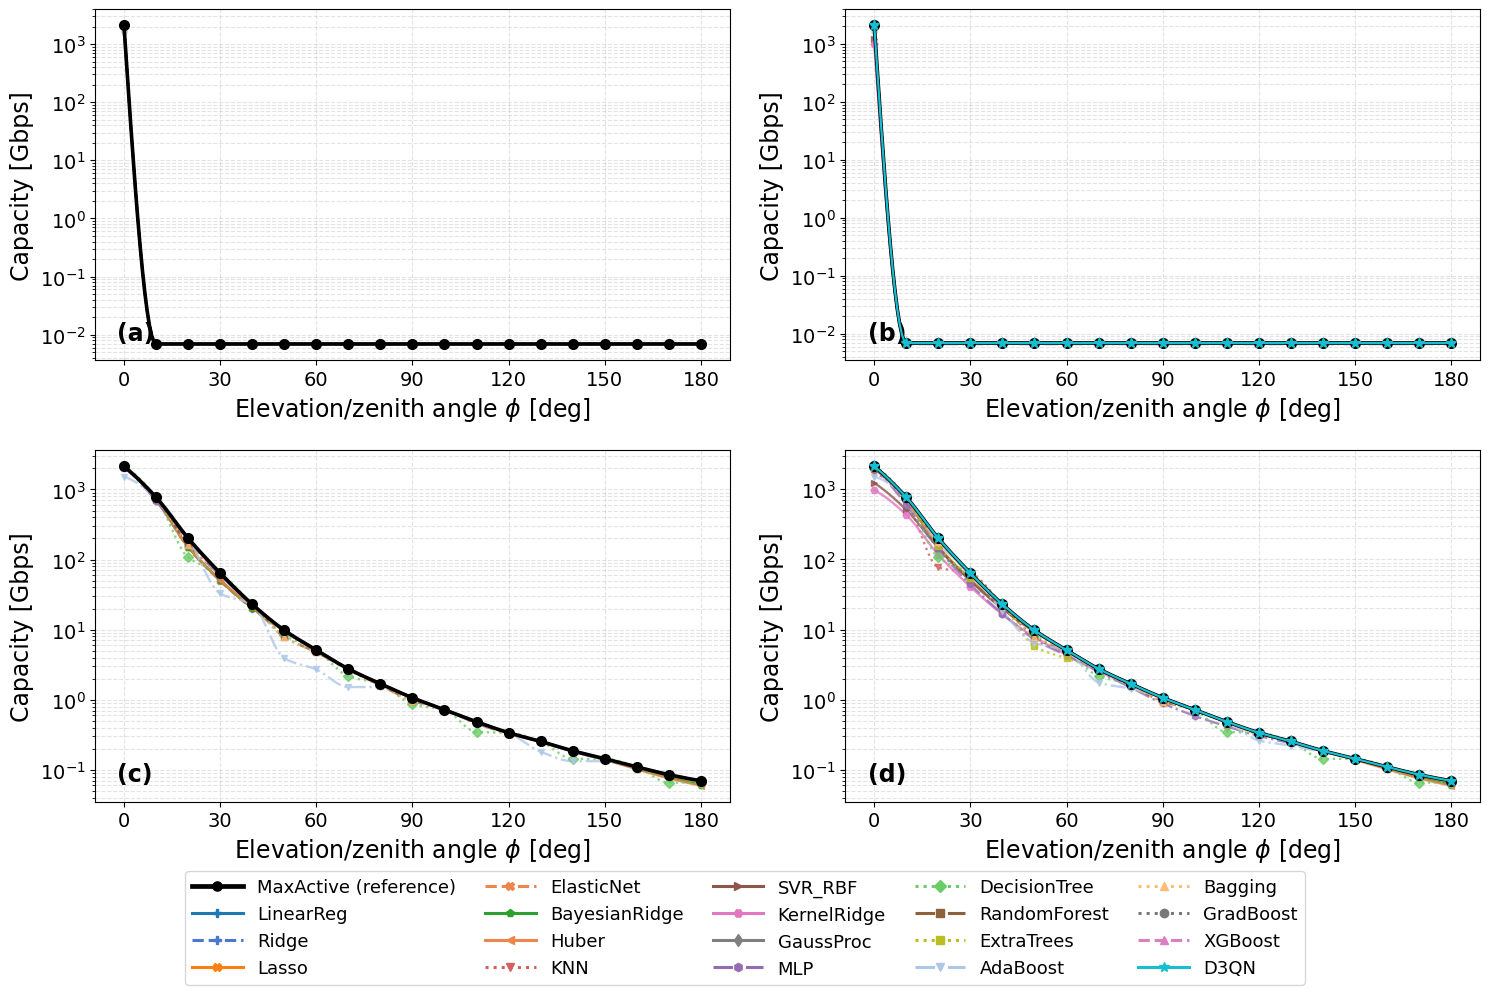

Saved: ml_elevation_comparison.png  (titles removed, shared legend, enlarged fonts)


In [52]:
# -- ML + D3QN vs MaxActive on the ELEVATION scenario (smooth PCHIP) --
# Presentation: no titles (panel tags (a)-(d)), one shared legend, enlarged fonts.
FS_LAB, FS_TICK, FS_LEG, FS_TAG = 17, 14, 13, 17
tags = [['(a)', '(b)'], ['(c)', '(d)']]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for r, scn in enumerate(['elev_noAdj', 'elev_Adj']):
    ss = sorted([s for s in dataset_mob if s['scenario'] == scn], key=lambda s: s['step'])
    axis = np.array([s['axis'] for s in ss])
    for c, alloc in enumerate(['WF', 'EP']):
        ax = axes[r, c]
        y_ma = np.array([s['cap_MA_' + alloc] / 1e9 for s in ss])
        slog(ax, axis, np.maximum(y_ma, 1e-12), color='k', marker='o', ls='-',
             lw=2.6, ms=7, zorder=6)
        for name in CV_MODELS:
            yp = np.minimum(predict_mob_curve(name, scn, alloc), y_ma)
            cc, mk, lw = STYLE.get(name, ('gray', 'o-', 1.2))
            mkc, lsc = _mk_ls(mk)
            slog(ax, axis, np.maximum(yp, 1e-12), color=cc, marker=mkc, ls=lsc,
                 lw=1.7, ms=5, alpha=0.8)
        if alloc == 'EP':
            yd = np.minimum(d3qn_mob[scn] / 1e9, y_ma)
            slog(ax, axis, np.maximum(yd, 1e-12), color=STYLE['D3QN'][0], marker='*', ls='-',
                 lw=1.6, ms=8, zorder=7)
        ax.set_xlabel(r'Elevation/zenith angle $\phi$ [deg]', fontsize=FS_LAB)
        ax.set_ylabel('Capacity [Gbps]', fontsize=FS_LAB)
        ax.set_xticks(np.arange(0, 181, 30))
        ax.tick_params(axis='both', which='major', labelsize=FS_TICK)
        ax.grid(True, which='both', ls='--', alpha=0.35)
        ax.text(0.035, 0.045, tags[r][c], transform=ax.transAxes, fontsize=FS_TAG,
                fontweight='bold', va='bottom', ha='left')

fig.legend(handles=_legend_handles(list(CV_MODELS.keys())), loc='lower center', ncol=5,
           fontsize=FS_LEG, frameon=True, bbox_to_anchor=(0.5, 0.0),
           columnspacing=1.6, handlelength=2.8)
fig.tight_layout(rect=[0, 0.115, 1, 1], h_pad=2.0, w_pad=2.2)
plt.savefig('ml_elevation_comparison.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved: ml_elevation_comparison.png  (titles removed, shared legend, enlarged fonts)')

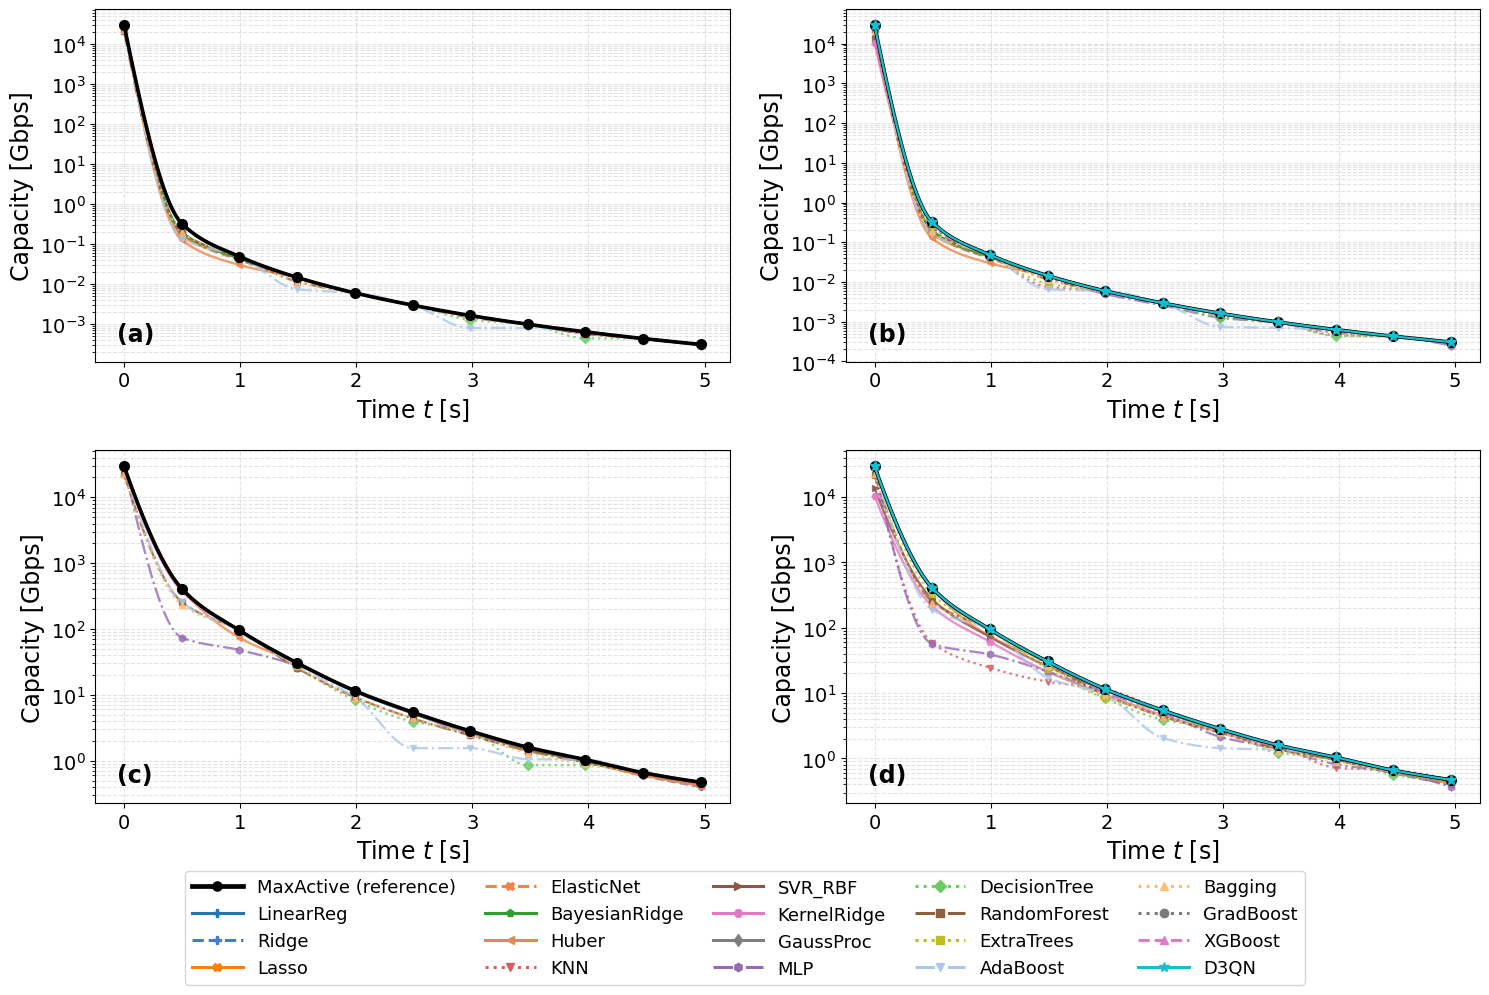

Saved: ml_real_comparison.png  (titles removed, shared legend, enlarged fonts)


In [53]:
# -- ML + D3QN vs MaxActive on the REAL-TRACE scenario (smooth PCHIP) --
# Presentation: no titles (panel tags (a)-(d)), one shared legend, enlarged fonts.
FS_LAB, FS_TICK, FS_LEG, FS_TAG = 17, 14, 13, 17
tags = [['(a)', '(b)'], ['(c)', '(d)']]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for r, scn in enumerate(['real_noAdj', 'real_Adj']):
    ss = sorted([s for s in dataset_mob if s['scenario'] == scn], key=lambda s: s['step'])
    axis = np.array([s['axis'] for s in ss])
    for c, alloc in enumerate(['WF', 'EP']):
        ax = axes[r, c]
        y_ma = np.array([s['cap_MA_' + alloc] / 1e9 for s in ss])
        slog(ax, axis, np.maximum(y_ma, 1e-12), color='k', marker='o', ls='-',
             lw=2.6, ms=7, zorder=6)
        for name in CV_MODELS:
            yp = np.minimum(predict_mob_curve(name, scn, alloc), y_ma)
            cc, mk, lw = STYLE.get(name, ('gray', 'o-', 1.2))
            mkc, lsc = _mk_ls(mk)
            slog(ax, axis, np.maximum(yp, 1e-12), color=cc, marker=mkc, ls=lsc,
                 lw=1.7, ms=5, alpha=0.8)
        if alloc == 'EP':
            yd = np.minimum(d3qn_mob[scn] / 1e9, y_ma)
            slog(ax, axis, np.maximum(yd, 1e-12), color=STYLE['D3QN'][0], marker='*', ls='-',
                 lw=1.6, ms=8, zorder=7)
        ax.set_xlabel('Time $t$ [s]', fontsize=FS_LAB)
        ax.set_ylabel('Capacity [Gbps]', fontsize=FS_LAB)
        ax.tick_params(axis='both', which='major', labelsize=FS_TICK)
        ax.grid(True, which='both', ls='--', alpha=0.35)
        ax.text(0.035, 0.045, tags[r][c], transform=ax.transAxes, fontsize=FS_TAG,
                fontweight='bold', va='bottom', ha='left')

fig.legend(handles=_legend_handles(list(CV_MODELS.keys())), loc='lower center', ncol=5,
           fontsize=FS_LEG, frameon=True, bbox_to_anchor=(0.5, 0.0),
           columnspacing=1.6, handlelength=2.8)
fig.tight_layout(rect=[0, 0.115, 1, 1], h_pad=2.0, w_pad=2.2)
plt.savefig('ml_real_comparison.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved: ml_real_comparison.png  (titles removed, shared legend, enlarged fonts)')

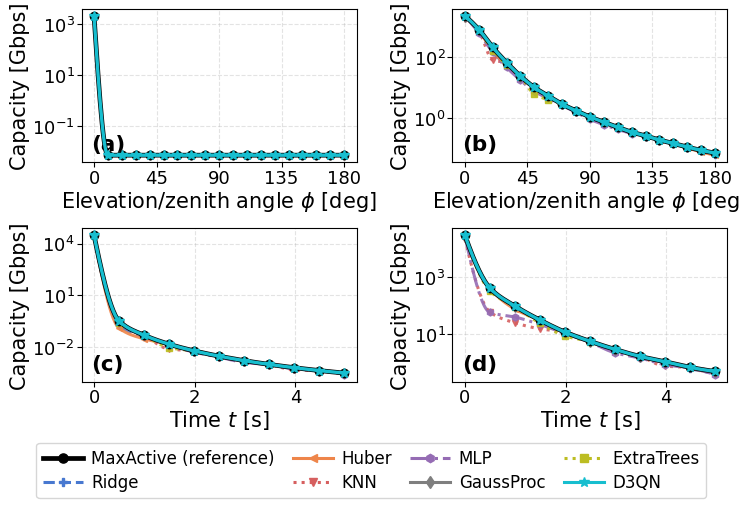

Saved: ml_mobility_comparison.png  (elevation + real traces, EP, printed size)


In [54]:
# -- Combined figure for the paper: both additional mobility patterns, EP allocation --
# Rows: elevation mobility / real windy-hover traces. Columns: without / with beamwidth
# adjustment. Only the EP column is shown: WF and EP coincide to within the line width in
# every scenario (see the MaxActive reference table), so the WF panels of the per-scenario
# figures above carry no additional information at journal size.
# Authored at the final printed size (IEEE textwidth = 7.16 in) with journal-scale fonts.
FS_LAB, FS_TICK, FS_LEG, FS_TAG = 15.0, 13.0, 12.0, 15.5
comb = [
    [('elev_noAdj', '(a)'), ('elev_Adj', '(b)')],
    [('real_noAdj', '(c)'), ('real_Adj', '(d)')],
]
xlabels = [r'Elevation/zenith angle $\phi$ [deg]', 'Time $t$ [s]']

fig, axes = plt.subplots(2, 2, figsize=(7.6, 5.2))   # wider/taller: at FS_LAB=15 the
# right-column x-label and the top-row y-labels were being clipped by the tight bbox
for r, row in enumerate(comb):
    for c, (scn, tag) in enumerate(row):
        ax = axes[r, c]
        ss = sorted([s for s in dataset_mob if s['scenario'] == scn], key=lambda s: s['step'])
        axis = np.array([s['axis'] for s in ss])
        y_ma = np.array([s['cap_MA_EP'] / 1e9 for s in ss])
        slog(ax, axis, np.maximum(y_ma, 1e-12), color='k', marker='o', ls='-',
             lw=3.4, ms=6.0, zorder=6)
        for name in FIG_MODELS:
            yp = np.minimum(predict_mob_curve(name, scn, 'EP'), y_ma)
            cc, mk, lw = STYLE.get(name, ('gray', 'o-', 1.2))
            mkc, lsc = _mk_ls(mk)
            slog(ax, axis, np.maximum(yp, 1e-12), color=cc, marker=mkc, ls=lsc,
                 lw=2.2, ms=5.0, alpha=0.9)
        yd = np.minimum(d3qn_mob[scn] / 1e9, y_ma)
        slog(ax, axis, np.maximum(yd, 1e-12), color=STYLE['D3QN'][0], marker='*', ls='-',
             lw=2.4, ms=7.0, zorder=7)
        ax.set_xlabel(xlabels[r], fontsize=FS_LAB, labelpad=1.5)
        ax.set_ylabel('Capacity [Gbps]', fontsize=FS_LAB, labelpad=1.5)
        if r == 0:
            ax.set_xticks(np.arange(0, 181, 45))
        ax.tick_params(axis='both', which='major', labelsize=FS_TICK, pad=1.5)
        ax.grid(True, which='major', ls='--', alpha=0.35)
        ax.text(0.035, 0.05, tag, transform=ax.transAxes, fontsize=FS_TAG,
                fontweight='bold', va='bottom', ha='left')

fig.legend(handles=_legend_handles(FIG_MODELS), loc='lower center', ncol=4,
           fontsize=FS_LEG, frameon=True, bbox_to_anchor=(0.5, 0.0), columnspacing=1.1,
           handlelength=2.4, handletextpad=0.5, borderpad=0.4, labelspacing=0.35)
fig.tight_layout(rect=[0.005, 0.115, 0.995, 0.985], h_pad=1.1, w_pad=1.4)
plt.savefig('ml_mobility_comparison.png', dpi=400, bbox_inches='tight')
plt.show()
print('Saved: ml_mobility_comparison.png  (elevation + real traces, EP, printed size)')

---

## Section U -- Runtime and Memory Benchmark

Quantifies the practical benefit of replacing the online MaxActive search with a learned
surrogate. MaxActive, the regressors, and the D3QN all consume the same per-context
channel state, so the comparison isolates the cost of the **decision** given that state,
and adds the one-off offline training cost and the deployed memory footprint. These
numbers back the motivation in the paper's introduction and its complexity section.


In [55]:
# -- Section U : runtime and memory benchmark (online search vs. learned surrogates) --
# Both MaxActive and the learned models consume the SAME channel state, so the fair
# comparison is the cost of the *decision* given that state, plus the one-off offline
# training cost and the deployed memory footprint of each surrogate.
import time, pickle, platform
import sklearn.base as _skb_u

def _timeit(fn, n_rep=3, n_warm=1):
    for _ in range(n_warm):
        fn()
    t0 = time.perf_counter()
    for _ in range(n_rep):
        fn()
    return (time.perf_counter() - t0) / n_rep

# NOTE: cell t0data01 rebinds the boresight globals, so recompute them for this study.
_tTx, _pTx, _tRx, _pRx = boresight_calc(CoordTx_init, CoordRx_init)

# ---------------------------------------------------------------- 1. channel contexts
bench_ctx = []
for k in range(N_STEPS):
    CoordRx_k = np.array([x_r_aligned[k], y_r_aligned[k], z_r_aligned[k]])
    d3 = float(np.sqrt(np.sum((CoordRx_k - CoordTx_init) ** 2)))
    Ft, Ab, PL = load_lblrtm(d3 / 1000.0)
    G = total_antenna_gain_dB(CoordTx_init, CoordRx_k, _tTx, _pTx, _tRx, _pRx,
                              BeamWidth_deg, BeamWidth_deg, SideLobeStrength, SideLobeStrength)
    m0 = ((Ft >= StartFreqTHz) & (Ft <= StopFreqTHz)).astype(int)
    PN = np.where(m0 == 1, pow2db(db2pow(TxPower_dBW + G)), -np.inf)
    bench_ctx.append(dict(m0=m0, Ft=Ft, Ab=Ab, PL=PL, PN=PN, G=G, Rx=CoordRx_k, d=d3))

N_CH_ACTIVE = int(bench_ctx[0]['m0'].sum())

# shared preprocessing: rank the channels by SNR (needed by MaxActive and by the D3QN)
t_sort = np.mean([_timeit(lambda c=c: get_sorted_channels_v4(c['Ft'], c['PL'], c['Ab'], c['G']), 5)
                  for c in bench_ctx])

# ------------------------------------------------- 2. MaxActive: the online search cost
t_ma_sel = np.mean([_timeit(lambda c=c: active_freq_mask(c['m0'], c['Ft'], c['PL'],
                                                         c['Ab'], 0.0, c['PN']), 3)
                    for c in bench_ctx])

t_ma_step = np.mean([_timeit(lambda c=c: distance_to_cap_opt(1, 1, 0, TxPower_dBmW, c['Rx'],
                                                             CoordTx_init, _tTx, _pTx, _tRx, _pRx),
                             1, n_warm=0)
                     for c in bench_ctx])

# the beamwidth-adjusted update must be timed on the SAME contexts as the fixed-beam one,
# otherwise the two numbers are not comparable (cost depends strongly on the geometry)
_bw_k = (2, 5, 8)
t_ma_step_fix3 = np.mean([_timeit(lambda c=bench_ctx[k]: distance_to_cap_opt(
                              1, 1, 0, TxPower_dBmW, c['Rx'], CoordTx_init,
                              _tTx, _pTx, _tRx, _pRx), 1, n_warm=0) for k in _bw_k])
t_ma_step_bw = np.mean([_timeit(lambda c=bench_ctx[k]: distance_to_cap_opt(
                            1, 1, 1, TxPower_dBmW, c['Rx'], CoordTx_init,
                            _tTx, _pTx, _tRx, _pRx), 1, n_warm=0) for k in _bw_k])

# ------------------------------------- 3. surrogate feature extraction (online, per step)
_c0 = bench_ctx[5]
t_sbstate = _timeit(lambda: build_subband_state_v2(_c0['Ft'], _c0['PL'], _c0['Ab'],
                                                   dist_m=_c0['d'], Gain_dB_total=_c0['G']), 10)
t_featvec = _timeit(lambda: build_features_v2(dataset[0], 'EP'), 500, n_warm=50)
t_feat = t_sbstate + t_featvec

# ------------------------- 4. per-model: train (offline), predict (online), memory (KB)
_x1 = X[:1]
bench_models = {}
for name, (mdl, scl) in full_EP.items():
    _xin = scl.transform(_x1) if scl is not None else _x1
    t_pred = _timeit(lambda m=mdl, xx=_xin: m.predict(xx), 300, n_warm=30)

    def _refit(m=mdl, s=scl):
        e = _skb_u.clone(m)
        e.fit(StandardScaler().fit_transform(X) if s is not None else X, yE)
    t_train = _timeit(_refit, 2, n_warm=1)

    kb = len(pickle.dumps(mdl)) / 1024.0
    if scl is not None:
        kb += len(pickle.dumps(scl)) / 1024.0
    bench_models[name] = dict(t_pred_us=t_pred * 1e6, t_train_ms=t_train * 1e3, mem_kb=kb,
                              speedup=t_ma_sel / (t_pred + t_feat))

# ------------------------------------------------------- 5. D3QN: inference and training
_net_b = DuelingDQN_v4().to(device).eval()
_APL_b, _Pn_b, _dF_b = get_sorted_channels_v4(_c0['Ft'], _c0['PL'], _c0['Ab'], _c0['G'])
_st_b = torch.FloatTensor(build_state_v4(_APL_b, _Pn_b)).unsqueeze(0).to(device)

def _d3qn_infer():
    with torch.no_grad():
        return int(_net_b(_st_b).argmax().item())

t_d3qn_state = _timeit(lambda: build_state_v4(_APL_b, _Pn_b), 300, n_warm=30)
t_d3qn_fwd = _timeit(_d3qn_infer, 300, n_warm=30)
d3qn_params = sum(p.numel() for p in _net_b.parameters())

_amap_b = make_action_map(len(_APL_b))
_Cmax_b, _ = maxactive_ep_v4(_APL_b, _Pn_b, _dF_b, _c0['G'])
t_d3qn_train = _timeit(lambda: train_bandit_v4(build_state_v4(_APL_b, _Pn_b), _APL_b, _Pn_b,
                                               _dF_b, _c0['G'], action_map=_amap_b,
                                               Cmax=_Cmax_b, Cmin=0.0), 1, n_warm=0)

# ------------------------------------------------------------------------ 6. report
runtime_bench = dict(
    n_channels=N_CH_ACTIVE, t_sort=t_sort, t_ma_sel=t_ma_sel, t_ma_step=t_ma_step,
    t_ma_step_fix3=t_ma_step_fix3, t_ma_step_bw=t_ma_step_bw,
    t_sbstate=t_sbstate, t_featvec=t_featvec, t_feat=t_feat,
    models=bench_models, t_d3qn_state=t_d3qn_state, t_d3qn_fwd=t_d3qn_fwd,
    t_d3qn_train=t_d3qn_train, d3qn_params=d3qn_params,
    d3qn_mem_kb=d3qn_params * 4 / 1024.0, cpu=platform.processor())

print('=' * 86)
print(f'RUNTIME BENCHMARK  |  {N_CH_ACTIVE} active channels per context  |  CPU: {platform.processor()}')
print('=' * 86)
print(f'  Shared channel-state preparation (SNR ranking)   : {t_sort*1e3:9.2f} ms')
print(f'  MaxActive threshold sweep (decision only)        : {t_ma_sel*1e3:9.2f} ms')
print(f'  MaxActive full link update (WF loop, fixed beam) : {t_ma_step*1e3:9.2f} ms')
print(f'    same 3 contexts, fixed beam                    : {t_ma_step_fix3*1e3:9.2f} ms')
print(f'    same 3 contexts, + beamwidth search            : {t_ma_step_bw*1e3:9.2f} ms  '
      f'({t_ma_step_bw/t_ma_step_fix3:.1f}x)')
print(f'  Surrogate feature extraction (sub-band + vector) : {t_feat*1e3:9.2f} ms')
print(f'  D3QN state build + forward pass                  : '
      f'{(t_d3qn_state+t_d3qn_fwd)*1e3:9.2f} ms   ({d3qn_params} params, '
      f'{d3qn_params*4/1024:.1f} KB)')
print(f'  D3QN training, one context (20 epochs x 80 acts) : {t_d3qn_train*1e3:9.2f} ms')
print('-' * 86)
print(f'{"Model":15s} {"train [ms]":>11s} {"predict [us]":>13s} {"memory [KB]":>12s} '
      f'{"speedup vs MaxActive":>21s}')
print('-' * 86)
for name in sorted(bench_models, key=lambda n: -bench_models[n]['speedup']):
    b = bench_models[name]
    print(f'{name:15s} {b["t_train_ms"]:11.2f} {b["t_pred_us"]:13.1f} {b["mem_kb"]:12.1f} '
          f'{b["speedup"]:20.1f}x')
print('-' * 86)
_tot_train = sum(b['t_train_ms'] for b in bench_models.values())
print(f'Total offline training, 18 models, one target      : {_tot_train:9.1f} ms')
print(f'Median surrogate speedup over the MaxActive search : '
      f'{np.median([b["speedup"] for b in bench_models.values()]):.0f}x')
print(f'D3QN speedup over the MaxActive search             : '
      f'{t_ma_sel/(t_d3qn_state+t_d3qn_fwd):.0f}x')
print('=' * 86)

RUNTIME BENCHMARK  |  11699 active channels per context  |  CPU: Intel64 Family 6 Model 186 Stepping 2, GenuineIntel
  Shared channel-state preparation (SNR ranking)   :      0.55 ms
  MaxActive threshold sweep (decision only)        :     76.82 ms
  MaxActive full link update (WF loop, fixed beam) :     94.58 ms
    same 3 contexts, fixed beam                    :     72.36 ms
    same 3 contexts, + beamwidth search            :     91.32 ms  (1.3x)
  Surrogate feature extraction (sub-band + vector) :      0.84 ms
  D3QN state build + forward pass                  :      0.05 ms   (21561 params, 84.2 KB)
  D3QN training, one context (20 epochs x 80 acts) :    114.58 ms
--------------------------------------------------------------------------------------
Model            train [ms]  predict [us]  memory [KB]  speedup vs MaxActive
--------------------------------------------------------------------------------------
BayesianRidge          0.82          20.7          2.2                

ok